
# Stable Linear E–I Neural Dynamics + Kernel Koopman Transient Spikes

This notebook keeps the **original kernel/KEDMD framework** and changes only the dynamical system.

We use a controlled linear excitatory–inhibitory (E–I) model for deviations around a stable neural-population equilibrium,

\[
\dot x = Jx,\qquad
x=\begin{bmatrix}\delta E\\ \delta I\end{bmatrix},
\]

with

\[
J=
\begin{bmatrix}
0.8 & -4.0\\
1.0 & -2.8
\end{bmatrix}.
\]

Interpretation:

- \(+0.8\): effective recurrent excitation in the E population;
- \(-4.0\): inhibitory influence \(I\to E\);
- \(+1.0\): excitatory influence \(E\to I\);
- \(-2.8\): inhibitory decay/self-damping.

The variables are **deviations from equilibrium**, so negative values are allowed.

The exact discrete flow is

\[
F_{\Delta t}=e^{J\Delta t},
\qquad x_{n+1}=F_{\Delta t}x_n.
\]

This gives us an exact physical ground truth for finite-time amplification,

\[
g_{\rm true}(n)=\|F_{\Delta t}^{\,n}\|_2.
\]

We then build the same regularized kernel Koopman surrogate used in the transient-spike framework,

\[
A_\lambda=(G_X+\lambda I)^{-1}A_X,
\]

and the geometry-normalized surrogate

\[
\widetilde A_\lambda
=
G_\lambda^{1/2}A_\lambda G_\lambda^{-1/2}
=
G_\lambda^{-1/2}A_XG_\lambda^{-1/2}.
\]

The main kernel-space transient diagnostic is

\[
\|A_\lambda^n\|_{G_\lambda}
=
\|\widetilde A_\lambda^n\|_2.
\]

We also compute:

1. fixed worst-direction growth;
2. eigenvalues of \(\widetilde A_\lambda\);
3. Koopman surrogate pseudospectra;
4. grid-based Kreiss estimates;
5. \(10^{-2}\)- and \(10^{-3}\)-pseudospectral radii;
6. optional \(\lambda\)-sensitivity.

**Important:** \(g_{\rm true}(n)\) lives in physical state space while
\(\|A_\lambda^n\|_{G_\lambda}\) lives in RKHS coefficient geometry.
They are therefore shown as complementary diagnostics, not treated as numerically identical quantities.


In [2]:

# Optional, only if packages are missing in your current VS Code/Jupyter kernel:
!pip3 install -U numpy scipy pandas matplotlib



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


In [3]:

import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.linalg import expm, eigh, solve, svdvals
from scipy.spatial.distance import cdist

np.set_printoptions(precision=6, suppress=True)

# ------------------------------------------------------------
# CONFIGURATION
# ------------------------------------------------------------
SEED = 42
DT = 0.05
LAMBDA = 1e-6
T_TRANSIENT = 60

# FAST_MODE is intended for the first Apple-laptop/Jupyter run.
# Publication mode is slower mainly because of pseudospectral SVDs.
FAST_MODE = True

if FAST_MODE:
    M = 80
    GRID_N = 61
else:
    M = 120
    GRID_N = 101

GRID_LIM = 1.30
EPS_LEVELS = (1e-2, 1e-3)

OUTDIR = "EI_kernel_koopman_results"
os.makedirs(OUTDIR, exist_ok=True)

print("FAST_MODE =", FAST_MODE)
print("M =", M)
print("pseudospectral grid =", GRID_N, "x", GRID_N)
print("lambda =", LAMBDA)


FAST_MODE = True
M = 80
pseudospectral grid = 61 x 61
lambda = 1e-06



## 1. Exact stable E–I dynamical system

The matrix is chosen to be **asymptotically stable but non-normal**.

That is useful for this control experiment because the true neural system is allowed to have a modest physical transient, while the exact matrix exponential tells us precisely how large that transient really is.

If a kernel surrogate produces much stronger finite-time amplification, we can distinguish that surrogate behavior from the true state-space response.


In [4]:

J = np.array([
    [ 0.8, -4.0],
    [ 1.0, -2.8],
], dtype=float)

F = expm(J * DT)

eig_J = np.linalg.eigvals(J)
eig_F = np.linalg.eigvals(F)

departure_J = np.linalg.norm(J.T @ J - J @ J.T, ord="fro")

print("J =")
print(J)
print("\neigenvalues(J) =", eig_J)
print("max Re eigenvalue(J) =", np.max(np.real(eig_J)))
print("departure from normality of J =", departure_J)

print("\nExact discrete map F = exp(J*DT) =")
print(F)
print("\neigenvalues(F) =", eig_F)
print("rho(F) =", np.max(np.abs(eig_F)))
print("||F||_2 =", svdvals(F)[0])


J =
[[ 0.8 -4. ]
 [ 1.  -2.8]]

eigenvalues(J) = [-1.+0.87178j -1.-0.87178j]
max Re eigenvalue(J) = -0.9999999999999998
departure from normality of J = 33.13608305156178

Exact discrete map F = exp(J*DT) =
[[ 1.035909 -0.190186]
 [ 0.047546  0.864742]]

eigenvalues(F) = [0.950326+0.04145j 0.950326-0.04145j]
rho(F) = 0.9512294245007141
||F||_2 = 1.069135688665857


In [5]:

# Exact continuous-time and discrete-time physical transient gain.

t_cont = np.linspace(0.0, T_TRANSIENT * DT, 800)
gain_cont = np.array([
    svdvals(expm(J * t))[0]
    for t in t_cont
])

steps = np.arange(0, T_TRANSIENT + 1)
gain_discrete = np.zeros_like(steps, dtype=float)

P = np.eye(2)
gain_discrete[0] = 1.0
for n in range(1, T_TRANSIENT + 1):
    P = P @ F
    gain_discrete[n] = svdvals(P)[0]

i_cont = int(np.argmax(gain_cont))
i_disc = int(np.argmax(gain_discrete))

print("Exact continuous physical peak:")
print(f"  peak gain = {gain_cont[i_cont]:.6f}")
print(f"  time      = {t_cont[i_cont]:.6f}")

print("\nExact discrete physical peak:")
print(f"  peak gain = {gain_discrete[i_disc]:.6f}")
print(f"  step      = {i_disc}")
print(f"  time      = {i_disc * DT:.6f}")


Exact continuous physical peak:
  peak gain = 1.677915
  time      = 0.728411

Exact discrete physical peak:
  peak gain = 1.677420
  step      = 15
  time      = 0.750000


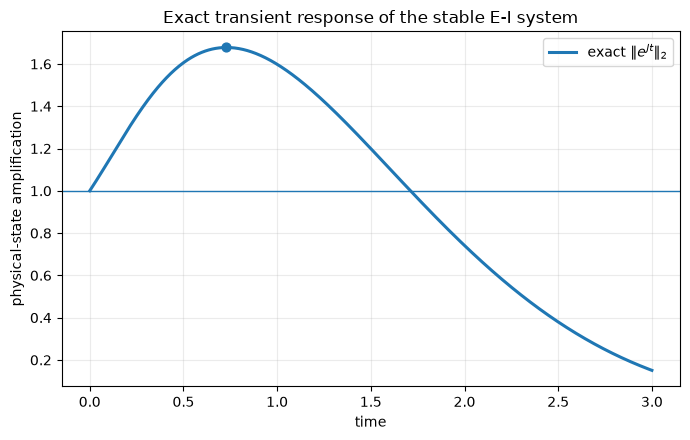

In [6]:

fig, ax = plt.subplots(figsize=(7.0, 4.5))

ax.plot(t_cont, gain_cont, linewidth=2.2, label=r"exact $\|e^{Jt}\|_2$")
ax.scatter([t_cont[i_cont]], [gain_cont[i_cont]], s=40)
ax.axhline(1.0, linewidth=1.0)

ax.set_xlabel("time")
ax.set_ylabel("physical-state amplification")
ax.set_title("Exact transient response of the stable E-I system")
ax.grid(alpha=0.25)
ax.legend()

plt.tight_layout()
plt.savefig(
    os.path.join(OUTDIR, "exact_EI_transient.png"),
    dpi=400,
    bbox_inches="tight",
)
plt.show()



## 2. One-step snapshot pairs

Instead of following one trajectory into the equilibrium and losing state-space coverage, we sample many perturbations around the equilibrium:

\[
x_i\sim [-1,1]^2,\qquad
y_i=F_{\Delta t}x_i.
\]

This gives \(M\) exact one-step pairs \((x_i,y_i)\).

Because \(x=(\delta E,\delta I)\) denotes deviations from equilibrium, the square \([-1,1]^2\) is a normalized perturbation domain rather than a raw firing-rate domain.


In [7]:

rng = np.random.default_rng(SEED)

X = rng.uniform(-1.0, 1.0, size=(M, 2))
Y = X @ F.T

print("X shape:", X.shape)
print("Y shape:", Y.shape)
print("\nFirst 3 snapshot pairs:")
for i in range(3):
    print("x =", X[i], " -> y =", Y[i])


X shape: (80, 2)
Y shape: (80, 2)

First 3 snapshot pairs:
x = [ 0.547912 -0.122243]  -> y = [ 0.590836 -0.079658]
x = [0.717196 0.394736]  -> y = [0.667877 0.375445]
x = [-0.811645  0.951245]  -> y = [-1.021704  0.783991]



## 3. Kernels and median-distance scales

We keep the same four kernel families:

- Laplace;
- Matérn-\(3/2\);
- Rational Quadratic;
- Gaussian RBF.

For the Laplace kernel, the median scale is computed with the \(L^1\) distance.
For the other three kernels, it is computed with the Euclidean distance.


In [8]:

KERNELS = ["Laplace", "Matern32", "RQ", "RBF"]

def pairwise_distance(A, B, metric="euclidean"):
    return cdist(A, B, metric=metric)

def median_scale(X, kind):
    metric = "cityblock" if kind == "Laplace" else "euclidean"
    D = pairwise_distance(X, X, metric=metric)
    positive = D[D > 0]
    return float(np.median(positive))

def kernel_matrix(A, B, kind, gamma):
    if kind == "Laplace":
        R = pairwise_distance(A, B, metric="cityblock")
        return np.exp(-R / gamma)

    R = pairwise_distance(A, B, metric="euclidean")

    if kind == "Matern32":
        q = np.sqrt(3.0) * R / gamma
        return (1.0 + q) * np.exp(-q)

    if kind == "RQ":
        return (1.0 + (R ** 2) / (2.0 * gamma ** 2)) ** (-1.0)

    if kind == "RBF":
        return np.exp(-(R ** 2) / (2.0 * gamma ** 2))

    raise ValueError(f"Unknown kernel: {kind}")

for kind in KERNELS:
    print(f"{kind:10s} gamma = {median_scale(X, kind):.6f}")


Laplace    gamma = 1.225703
Matern32   gamma = 0.977276
RQ         gamma = 0.977276
RBF        gamma = 0.977276



## 4. Original regularized KEDMD construction

For each kernel,

\[
G_X=[k(x_i,x_j)]_{i,j},
\qquad
A_X=[k(y_i,x_j)]_{i,j},
\]

\[
G_\lambda=G_X+\lambda I,
\qquad
A_\lambda=G_\lambda^{-1}A_X.
\]

The geometry-normalized operator is

\[
\widetilde A_\lambda
=
G_\lambda^{1/2} A_\lambda G_\lambda^{-1/2}
=
G_\lambda^{-1/2}A_XG_\lambda^{-1/2}.
\]

All transient envelopes and pseudospectra below are computed from
\(\widetilde A_\lambda\).


In [9]:

def spd_sqrt_and_invsqrt(G, floor=1e-14):
    Gs = 0.5 * (G + G.T)
    evals, U = eigh(Gs)
    evals = np.maximum(evals, floor)

    Ghalf = (U * np.sqrt(evals)) @ U.T
    Gmhalf = (U * (1.0 / np.sqrt(evals))) @ U.T
    return Ghalf, Gmhalf

def build_kedmd(X, Y, kind, lam=LAMBDA):
    gamma = median_scale(X, kind)

    GX = kernel_matrix(X, X, kind, gamma)
    AX = kernel_matrix(Y, X, kind, gamma)

    Glam = GX + lam * np.eye(GX.shape[0])

    A = solve(Glam, AX, assume_a="pos")

    Ghalf, Gmhalf = spd_sqrt_and_invsqrt(Glam)

    # Two equivalent forms. The second one is used because it directly
    # matches the normalized representation.
    Atilde_from_similarity = Ghalf @ A @ Gmhalf
    Atilde = Gmhalf @ AX @ Gmhalf

    rel_identity_error = (
        np.linalg.norm(Atilde - Atilde_from_similarity, ord="fro")
        / np.linalg.norm(Atilde, ord="fro")
    )

    return {
        "kind": kind,
        "gamma": gamma,
        "GX": GX,
        "AX": AX,
        "Glam": Glam,
        "A": A,
        "Ghalf": Ghalf,
        "Gmhalf": Gmhalf,
        "Atilde": Atilde,
        "identity_error": rel_identity_error,
    }

models = {
    kind: build_kedmd(X, Y, kind, lam=LAMBDA)
    for kind in KERNELS
}

for kind, model in models.items():
    print(
        f"{kind:10s} | gamma={model['gamma']:.6f} | "
        f"similarity identity relative error={model['identity_error']:.3e}"
    )


Laplace    | gamma=1.225703 | similarity identity relative error=1.953e-14
Matern32   | gamma=0.977276 | similarity identity relative error=1.009e-12
RQ         | gamma=0.977276 | similarity identity relative error=4.904e-10
RBF        | gamma=0.977276 | similarity identity relative error=1.139e-09



## 5. Kernel Koopman transient envelopes

We compute

\[
\|A_\lambda^n\|_{G_\lambda}
=
\|\widetilde A_\lambda^n\|_2.
\]

For each kernel we also find the right singular direction at its peak time and track that **same fixed direction** over the full horizon.


In [10]:

def transient_diagnostics(Atilde, T=T_TRANSIENT):
    d = Atilde.shape[0]

    env = np.zeros(T + 1)
    env[0] = 1.0

    powers = [np.eye(d)]
    P = np.eye(d)

    for n in range(1, T + 1):
        P = P @ Atilde
        powers.append(P.copy())
        env[n] = svdvals(P)[0]

    t_peak = int(np.argmax(env[1:]) + 1)
    peak = float(env[t_peak])

    _, _, Vh = np.linalg.svd(powers[t_peak], full_matrices=False)
    y_star = Vh[0, :]
    y_star = y_star / np.linalg.norm(y_star)

    fixed = np.zeros(T + 1)
    fixed[0] = 1.0

    for n in range(1, T + 1):
        fixed[n] = np.linalg.norm(powers[n] @ y_star)

    rho = float(np.max(np.abs(np.linalg.eigvals(Atilde))))

    dep_normal = float(
        np.linalg.norm(
            Atilde.conj().T @ Atilde
            - Atilde @ Atilde.conj().T,
            ord="fro",
        )
    )

    return {
        "env": env,
        "fixed": fixed,
        "t_peak": t_peak,
        "peak": peak,
        "rho": rho,
        "departure_normality": dep_normal,
    }

for kind in KERNELS:
    models[kind]["transient"] = transient_diagnostics(
        models[kind]["Atilde"],
        T=T_TRANSIENT,
    )

rows = []

for kind in KERNELS:
    m = models[kind]
    td = m["transient"]

    rows.append({
        "kernel": kind,
        "gamma": m["gamma"],
        "cond_Glambda": np.linalg.cond(m["Glam"]),
        "rho_Atilde": td["rho"],
        "departure_normality": td["departure_normality"],
        "peak_G": td["peak"],
        "t_peak": td["t_peak"],
    })

transient_table = pd.DataFrame(rows)
display(transient_table)

transient_table.to_csv(
    os.path.join(OUTDIR, "EI_transient_summary.csv"),
    index=False,
)


,kernel,gamma,cond_Glambda,rho_Atilde,departure_normality,peak_G,t_peak
0,Laplace,1.225703,1.645891e+03,1.000015,5.260621,1.847468,10
1,Matern32,0.977276,2.811101e+05,0.999975,2.582054,3.057903,16
2,RQ,0.977276,5.436829e+07,1.000005,2.210580,11.742282,13
3,RBF,0.977276,4.906964e+07,1.000006,1.575792,16.958628,12


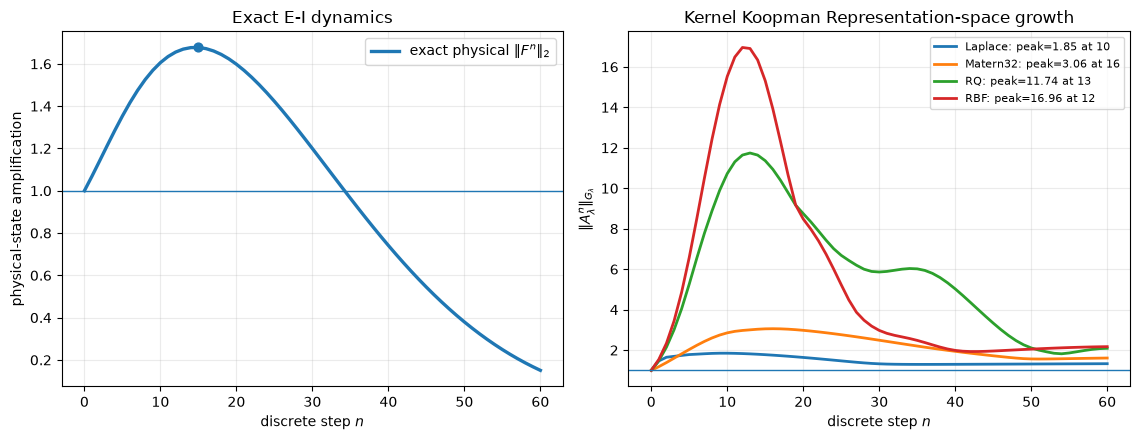

In [11]:

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.5))

# Exact physical gain
axes[0].plot(
    steps,
    gain_discrete,
    linewidth=2.4,
    label=r"exact physical $\|F^n\|_2$",
)
axes[0].axhline(1.0, linewidth=1.0)
axes[0].scatter([i_disc], [gain_discrete[i_disc]], s=40)
axes[0].set_xlabel("discrete step $n$")
axes[0].set_ylabel("physical-state amplification")
axes[0].set_title("Exact E-I dynamics")
axes[0].grid(alpha=0.25)
axes[0].legend()

# KEDMD representation-space gain
for kind in KERNELS:
    td = models[kind]["transient"]
    axes[1].plot(
        steps,
        td["env"],
        linewidth=2.0,
        label=f"{kind}: peak={td['peak']:.2f} at {td['t_peak']}",
    )

axes[1].axhline(1.0, linewidth=1.0)
axes[1].set_xlabel("discrete step $n$")
axes[1].set_ylabel(r"$\|A_\lambda^n\|_{G_\lambda}$")
axes[1].set_title("Kernel Koopman Representation-space growth")
axes[1].grid(alpha=0.25)
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.savefig(
    os.path.join(OUTDIR, "EI_exact_vs_KEDMD_transient.pdf"),
    dpi=500,
    bbox_inches="tight",
)
plt.show()


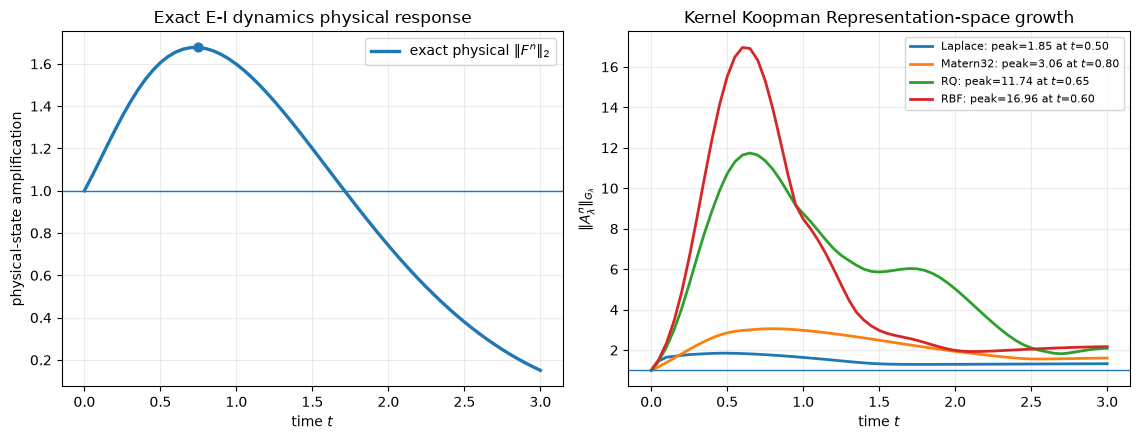

In [14]:
# Convert discrete Koopman steps to physical time
times = steps * DT

fig, axes = plt.subplots(
    1, 2,
    figsize=(11.5, 4.5)
)

# ============================================================
# Exact physical gain
# ============================================================

axes[0].plot(
    times,
    gain_discrete,
    linewidth=2.4,
    label=r"exact physical $\|F^n\|_2$",
)

axes[0].axhline(
    1.0,
    linewidth=1.0
)

axes[0].scatter(
    [times[i_disc]],
    [gain_discrete[i_disc]],
    s=40,
    zorder=5
)

axes[0].set_xlabel("time $t$")

axes[0].set_ylabel(
    "physical-state amplification"
)

axes[0].set_title(
    "Exact E-I dynamics physical response"
)

axes[0].grid(alpha=0.25)
axes[0].legend()


# ============================================================
# KEDMD representation-space gain
# ============================================================

for kind in KERNELS:

    td = models[kind]["transient"]

    axes[1].plot(
        times,
        td["env"],
        linewidth=2.0,
        label=(
            f"{kind}: "
            f"peak={td['peak']:.2f} "
            f"at $t$={td['t_peak'] * DT:.2f}"
        ),
    )


axes[1].axhline(
    1.0,
    linewidth=1.0
)

axes[1].set_xlabel("time $t$")

axes[1].set_ylabel(
    r"$\|A_\lambda^n\|_{G_\lambda}$"
)

axes[1].set_title(
    "Kernel Koopman Representation-space growth"
)

axes[1].grid(alpha=0.25)

axes[1].legend(
    fontsize=8
)


plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTDIR,
        "EI_exact_vs_KEDMD_transient.pdf"
    ),
    dpi=500,
    bbox_inches="tight",
)

plt.show()

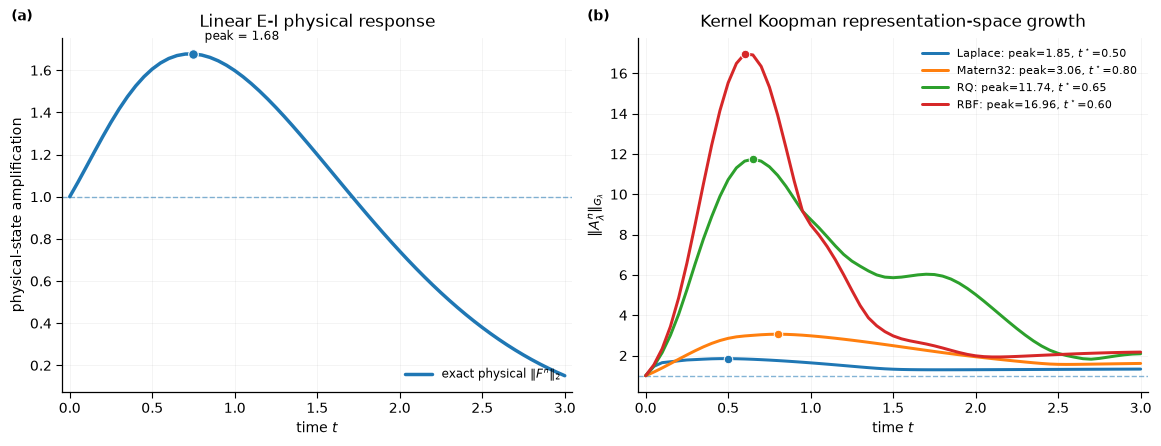

In [13]:
# Convert discrete Koopman steps to physical time
times = steps * DT

fig, axes = plt.subplots(
    1, 2,
    figsize=(11.5, 4.35),
    constrained_layout=True
)

# ============================================================
# Small helper: clean conference-style axes
# ============================================================

def polish_axis(ax):
    # Keep existing font configuration untouched
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.spines["left"].set_linewidth(0.9)
    ax.spines["bottom"].set_linewidth(0.9)

    ax.tick_params(
        axis="both",
        which="major",
        direction="out",
        length=4.0,
        width=0.8
    )

    ax.grid(
        True,
        axis="both",
        linewidth=0.6,
        alpha=0.16
    )

    ax.set_axisbelow(True)


# ============================================================
# (a) Exact physical gain
# ============================================================

ax = axes[0]

ax.plot(
    times,
    gain_discrete,
    linewidth=2.5,
    solid_capstyle="round",
    label=r"exact physical $\|F^n\|_2$",
    zorder=3
)

# Neutral amplification baseline
ax.axhline(
    1.0,
    linewidth=1.0,
    linestyle="--",
    alpha=0.55,
    zorder=1
)

# Peak point
ax.scatter(
    times[i_disc],
    gain_discrete[i_disc],
    s=48,
    marker="o",
    edgecolors="white",
    linewidths=0.8,
    zorder=5
)

# Small peak annotation
ax.annotate(
    rf"peak = {gain_discrete[i_disc]:.2f}",
    xy=(times[i_disc], gain_discrete[i_disc]),
    xytext=(8, 8),
    textcoords="offset points",
    fontsize=8.5,
    ha="left",
    va="bottom"
)

ax.set_xlabel("time $t$")
ax.set_ylabel("physical-state amplification")

ax.set_title(
    "Linear E-I physical response",
    pad=8
)

ax.legend(
    loc="lower right",
    frameon=False,
    fontsize=8.5,
    handlelength=2.3
)

polish_axis(ax)


# ============================================================
# (b) KEDMD representation-space gain
# ============================================================

ax = axes[1]

for kind in KERNELS:

    td = models[kind]["transient"]

    # Main curve
    line, = ax.plot(
        times,
        td["env"],
        linewidth=2.15,
        solid_capstyle="round",
        label=(
            f"{kind}: "
            f"peak={td['peak']:.2f}, "
            rf"$t^\star$={td['t_peak'] * DT:.2f}"
        ),
        zorder=3
    )

    # Put a marker exactly at the transient maximum.
    # Use the line's own automatically assigned color.
    peak_idx = int(td["t_peak"])

    ax.scatter(
        times[peak_idx],
        td["env"][peak_idx],
        s=38,
        marker="o",
        facecolor=line.get_color(),
        edgecolor="white",
        linewidth=0.7,
        zorder=5
    )


# Neutral amplification baseline
ax.axhline(
    1.0,
    linewidth=1.0,
    linestyle="--",
    alpha=0.55,
    zorder=1
)

ax.set_xlabel("time $t$")

ax.set_ylabel(
    r"$\|A_\lambda^n\|_{G_\lambda}$"
)

ax.set_title(
    "Kernel Koopman representation-space growth",
    pad=8
)

ax.legend(
    loc="upper right",
    frameon=False,
    fontsize=8.2,
    handlelength=2.3,
    labelspacing=0.45
)

polish_axis(ax)


# ============================================================
# Consistent horizontal margins
# ============================================================

for ax in axes:
    ax.margins(x=0.015)


# ============================================================
# Panel labels
# ============================================================

axes[0].text(
    -0.10,
    1.04,
    "(a)",
    transform=axes[0].transAxes,
    fontsize=10,
    fontweight="bold",
    va="bottom"
)

axes[1].text(
    -0.10,
    1.04,
    "(b)",
    transform=axes[1].transAxes,
    fontsize=10,
    fontweight="bold",
    va="bottom"
)


# ============================================================
# Save
# ============================================================

plt.savefig(
    os.path.join(
        OUTDIR,
        "EI_exact_vs_KEDMD_transient.pdf"
    ),
    dpi=500,
    bbox_inches="tight"
)

plt.show()

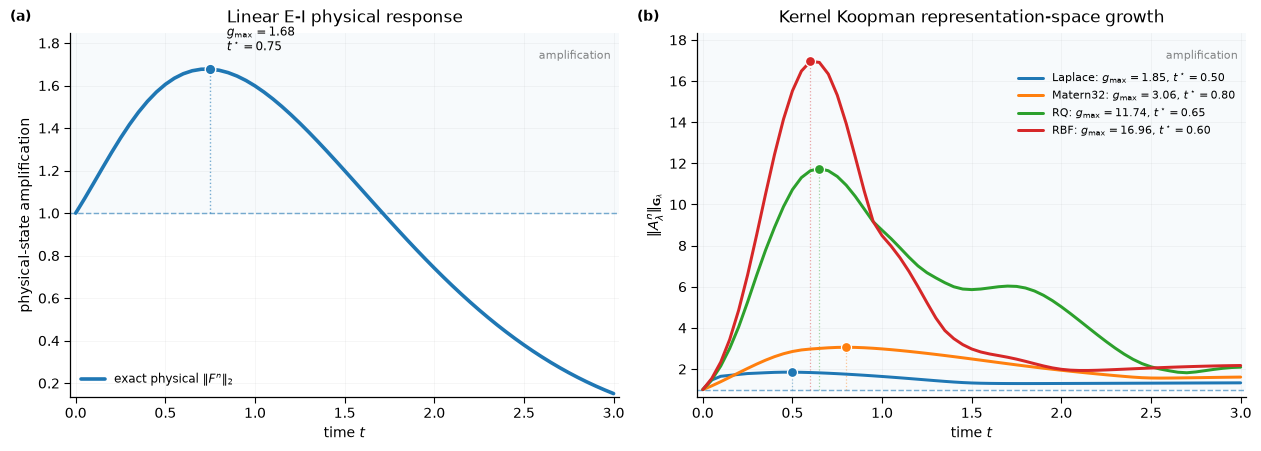

In [23]:
# Convert discrete Koopman steps to physical time
times = steps * DT

fig, axes = plt.subplots(
    1, 2,
    figsize=(12.5, 4.4),
    constrained_layout=True
)


# ============================================================
# Common visual treatment
# ============================================================

def clean_axis(ax):

    # Do NOT touch font settings
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.spines["left"].set_linewidth(0.9)
    ax.spines["bottom"].set_linewidth(0.9)

    ax.tick_params(
        direction="out",
        length=4,
        width=0.8
    )

    ax.grid(
        True,
        linewidth=0.55,
        alpha=0.15
    )

    ax.set_axisbelow(True)


# ============================================================
# LEFT: exact physical response
# ============================================================

ax = axes[0]

# ------------------------------------------------------------
# Amplification region: gain > 1
# ------------------------------------------------------------

y_top_left = max(gain_discrete) * 1.10

ax.axhspan(
    1.0,
    y_top_left,
    alpha=0.035,
    zorder=0
)

# Neutral gain boundary
ax.axhline(
    1.0,
    linestyle="--",
    linewidth=1.05,
    alpha=0.60,
    zorder=1
)


# Exact response
line_phys, = ax.plot(
    times,
    gain_discrete,
    linewidth=2.6,
    solid_capstyle="round",
    label=r"exact physical $\|F^n\|_2$",
    zorder=3
)


# ------------------------------------------------------------
# Peak geometry
# ------------------------------------------------------------

t_phys_star = times[i_disc]
g_phys_star = gain_discrete[i_disc]

# vertical peak stem
ax.vlines(
    t_phys_star,
    1.0,
    g_phys_star,
    linestyle=":",
    linewidth=1.0,
    color=line_phys.get_color(),
    alpha=0.60,
    zorder=2
)

# peak point
ax.scatter(
    t_phys_star,
    g_phys_star,
    s=58,
    facecolor=line_phys.get_color(),
    edgecolor="white",
    linewidth=1.0,
    zorder=5
)

# compact annotation
ax.annotate(
    rf"$g_{{\max}}={g_phys_star:.2f}$"
    "\n"
    rf"$t^\star={t_phys_star:.2f}$",
    xy=(t_phys_star, g_phys_star),
    xytext=(12, 10),
    textcoords="offset points",
    fontsize=8.5,
    va="bottom",
    ha="left"
)


ax.set_ylim(
    bottom=min(0.15, gain_discrete.min() * 0.90),
    top=y_top_left
)

ax.set_xlabel("time $t$")
ax.set_ylabel("physical-state amplification")

ax.set_title(
    "Linear E-I physical response",
    pad=8
)

ax.legend(
    loc="lower left",
    frameon=False,
    fontsize=8.5
)

# Very subtle semantic label
ax.text(
    0.985,
    0.955,
    "amplification",
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=8,
    alpha=0.48
)

clean_axis(ax)


# ============================================================
# RIGHT: KEDMD representation-space response
# ============================================================

ax = axes[1]

# Determine top once so shaded area covers actual range
global_peak = max(
    models[kind]["transient"]["peak"]
    for kind in KERNELS
)

y_top_right = global_peak * 1.08


# ------------------------------------------------------------
# Amplification region
# ------------------------------------------------------------

ax.axhspan(
    1.0,
    y_top_right,
    alpha=0.035,
    zorder=0
)

ax.axhline(
    1.0,
    linestyle="--",
    linewidth=1.05,
    alpha=0.60,
    zorder=1
)


# ------------------------------------------------------------
# Kernel curves + peak geometry
# ------------------------------------------------------------

for kind in KERNELS:

    td = models[kind]["transient"]

    peak_idx = int(td["t_peak"])

    t_star = times[peak_idx]
    g_star = td["env"][peak_idx]

    line, = ax.plot(
        times,
        td["env"],
        linewidth=2.15,
        solid_capstyle="round",
        label=(
            f"{kind}: "
            rf"$g_{{\max}}={g_star:.2f}$, "
            rf"$t^\star={t_star:.2f}$"
        ),
        zorder=3
    )

    kernel_color = line.get_color()

    # Vertical stem shows peak time explicitly
    ax.vlines(
        t_star,
        1.0,
        g_star,
        color=kernel_color,
        linestyle=":",
        linewidth=0.9,
        alpha=0.42,
        zorder=2
    )

    # Peak marker
    ax.scatter(
        t_star,
        g_star,
        s=52,
        facecolor=kernel_color,
        edgecolor="white",
        linewidth=0.9,
        zorder=5
    )


ax.set_ylim(
    bottom=0.65,
    top=y_top_right
)

ax.set_xlabel("time $t$")

ax.set_ylabel(
    r"$\|A_\lambda^n\|_{\mathbf{G}_\lambda}$"
)

ax.set_title(
    "Kernel Koopman representation-space growth",
    pad=8
)

ax.legend(
    loc="upper right",
    bbox_to_anchor=(1.00, 0.92),
    frameon=False,
    fontsize=8.0,
    handlelength=2.3,
    labelspacing=0.50
)

ax.text(
    0.985,
    0.955,
    "amplification",
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=8,
    alpha=0.48
)

clean_axis(ax)


# ============================================================
# Panel labels
# ============================================================

axes[0].text(
    -0.11,
    1.035,
    "(a)",
    transform=axes[0].transAxes,
    fontsize=10,
    fontweight="bold",
    ha="left"
)

axes[1].text(
    -0.11,
    1.035,
    "(b)",
    transform=axes[1].transAxes,
    fontsize=10,
    fontweight="bold",
    ha="left"
)


# Small margins
for ax in axes:
    ax.margins(x=0.01)


# ============================================================
# Save
# ============================================================

plt.savefig(
    os.path.join(
        OUTDIR,
        "EI_exact_vs_KEDMD_transient_polished.pdf"
    ),
    dpi=500,
    bbox_inches="tight"
)

plt.show()

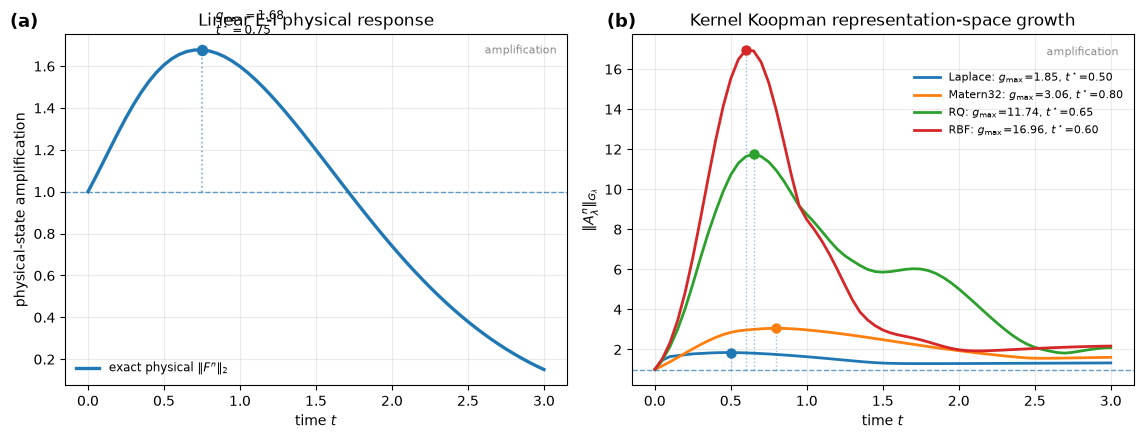

In [19]:
# Convert discrete Koopman steps to physical time
times = steps * DT

fig, axes = plt.subplots(
    1, 2,
    figsize=(11.5, 4.5)
)

# ============================================================
# (a) Exact physical gain
# ============================================================

ax = axes[0]

ax.plot(
    times,
    gain_discrete,
    linewidth=2.4,
    label=r"exact physical $\|F^n\|_2$",
)

ax.axhline(
    1.0,
    linewidth=1.0,
    linestyle="--",
    alpha=0.7
)

# peak marker
ax.scatter(
    [times[i_disc]],
    [gain_discrete[i_disc]],
    s=52,
    zorder=5
)

# vertical guide at peak
ax.vlines(
    times[i_disc],
    1.0,
    gain_discrete[i_disc],
    linestyles=":",
    linewidth=1.2,
    alpha=0.6
)

# peak annotation
ax.annotate(
    rf"$g_{{\max}}={gain_discrete[i_disc]:.2f}$" + "\n" +
    rf"$t^\star={times[i_disc]:.2f}$",
    xy=(times[i_disc], gain_discrete[i_disc]),
    xytext=(10, 8),
    textcoords="offset points",
    fontsize=8.5,
    ha="left",
    va="bottom"
)

ax.set_xlabel("time $t$")
ax.set_ylabel("physical-state amplification")
ax.set_title("Linear E-I physical response")
ax.grid(alpha=0.25)

# moved legend from lower right -> lower left
ax.legend(
    loc="lower left",
    frameon=False,
    fontsize=8.5
)

ax.text(
    0.98, 0.97,
    "amplification",
    transform=ax.transAxes,
    ha="right", va="top",
    fontsize=8,
    alpha=0.45
)

ax.text(
    -0.11, 1.02,
    "(a)",
    transform=ax.transAxes,
    fontsize=13,
    fontweight="bold"
)

# ============================================================
# (b) KEDMD representation-space gain
# ============================================================

ax = axes[1]

for kind in KERNELS:
    td = models[kind]["transient"]

    ax.plot(
        times,
        td["env"],
        linewidth=2.0,
        label=(
            f"{kind}: "
            f"$g_{{\\max}}$={td['peak']:.2f}, "
            f"$t^\\star$={td['t_peak'] * DT:.2f}"
        ),
    )

    # peak marker for each kernel
    ax.scatter(
        [td["t_peak"] * DT],
        [td["peak"]],
        s=42,
        zorder=5
    )

    # vertical guide
    ax.vlines(
        td["t_peak"] * DT,
        1.0,
        td["peak"],
        linestyles=":",
        linewidth=1.0,
        alpha=0.45
    )

ax.axhline(
    1.0,
    linewidth=1.0,
    linestyle="--",
    alpha=0.7
)

ax.set_xlabel("time $t$")
ax.set_ylabel(r"$\|A_\lambda^n\|_{G_\lambda}$")
ax.set_title("Kernel Koopman representation-space growth")
ax.grid(alpha=0.25)

# move legend slightly down so "amplification" remains visible
ax.legend(
    loc="upper right",
    bbox_to_anchor=(1.00, 0.92),
    frameon=False,
    fontsize=8.0,
    handlelength=2.3,
    labelspacing=0.50
)

ax.text(
    0.97, 0.965,
    "amplification",
    transform=ax.transAxes,
    ha="right", va="top",
    fontsize=8,
    alpha=0.45
)

ax.text(
    -0.05, 1.02,
    "(b)",
    transform=ax.transAxes,
    fontsize=13,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTDIR,
        "EI_exact_vs_KEDMD_transient_clean.pdf"
    ),
    dpi=500,
    bbox_inches="tight",
)

plt.savefig(
    os.path.join(
        OUTDIR,
        "EI_exact_vs_KEDMD_transient_clean.png"
    ),
    dpi=500,
    bbox_inches="tight",
)

plt.show()

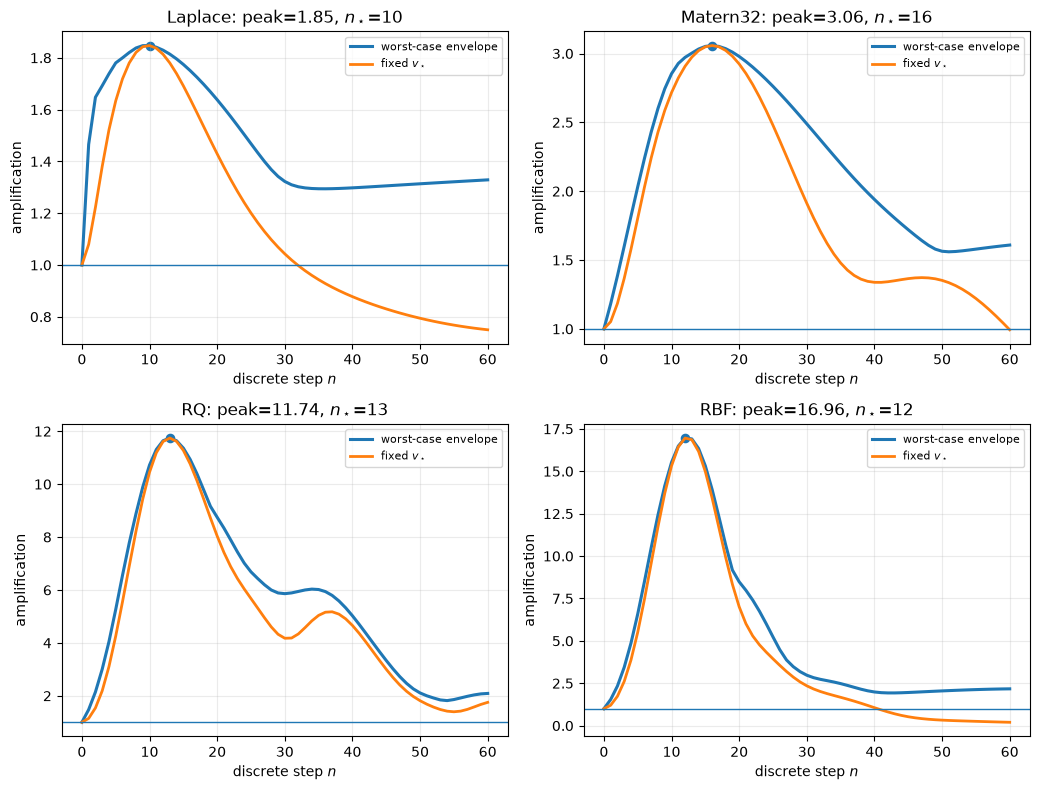

In [19]:

fig, axes = plt.subplots(2, 2, figsize=(10.5, 8.0))
axes = axes.ravel()

for ax, kind in zip(axes, KERNELS):
    td = models[kind]["transient"]

    ax.plot(steps, td["env"], linewidth=2.2, label="worst-case envelope")
    ax.plot(steps, td["fixed"], linewidth=2.0, label=r"fixed $v_\star$")
    ax.axhline(1.0, linewidth=1.0)
    ax.scatter([td["t_peak"]], [td["peak"]], s=35)

    ax.set_title(
        f"{kind}: peak={td['peak']:.2f}, "
        f"$n_\\star$={td['t_peak']}"
    )
    ax.set_xlabel("discrete step $n$")
    ax.set_ylabel("amplification")
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig(
    os.path.join(OUTDIR, "EI_fixed_direction_growth.png"),
    dpi=400,
    bbox_inches="tight",
)
plt.show()



### Interpretation checkpoint

The exact E–I system is stable because all eigenvalues of \(J\) have negative real part.

For the chosen parameters, the physical state dynamics have a **modest exact transient**.

The question is whether the kernelized Koopman representation produces a much larger finite-time envelope, and whether the hierarchy across kernels is accompanied by pseudospectral inflation.

Do not conclude anything from the transient plot alone; the pseudospectral calculation below is the next diagnostic.



## 6. Koopman surrogate pseudospectra and Kreiss estimates

For the normalized surrogate \(\widetilde A_\lambda\),

\[
\sigma_\varepsilon(\widetilde A_\lambda)
=
\left\{
z\in\mathbb C:
\|(zI-\widetilde A_\lambda)^{-1}\|_2>\varepsilon^{-1}
\right\}.
\]

At every complex grid point we compute the smallest singular value,

\[
\|(zI-\widetilde A_\lambda)^{-1}\|_2
=
\frac{1}{\sigma_{\min}(zI-\widetilde A_\lambda)}.
\]

The same grid is reused to estimate the discrete Kreiss constant,

\[
\widehat{\mathcal K}
=
\max_{|z|>1}
(|z|-1)
\|(zI-\widetilde A_\lambda)^{-1}\|_2.
\]

This is the slowest part of the notebook. In `FAST_MODE`, the default is an \(80\times80\) surrogate and a \(61\times61\) complex grid.


In [20]:

def resolvent_grid(
    Atilde,
    grid_lim=GRID_LIM,
    grid_n=GRID_N,
    eps_levels=EPS_LEVELS,
):
    xs = np.linspace(-grid_lim, grid_lim, grid_n)
    ys = np.linspace(-grid_lim, grid_lim, grid_n)

    R = np.empty((grid_n, grid_n), dtype=float)

    d = Atilde.shape[0]
    I = np.eye(d)

    kreiss_hat = 0.0
    kreiss_location = np.nan + 1j * np.nan

    for iy, yy in enumerate(ys):
        for ix, xx in enumerate(xs):
            z = xx + 1j * yy

            smin = svdvals(z * I - Atilde)[-1]
            resolvent = 1.0 / max(float(smin), 1e-14)

            R[iy, ix] = resolvent

            modulus = abs(z)
            if modulus > 1.0:
                value = (modulus - 1.0) * resolvent
                if value > kreiss_hat:
                    kreiss_hat = value
                    kreiss_location = z

    XX, YY = np.meshgrid(xs, ys)
    MOD = np.sqrt(XX**2 + YY**2)

    radii = {}
    boundary_warning = {}

    boundary = np.zeros_like(R, dtype=bool)
    boundary[0, :] = True
    boundary[-1, :] = True
    boundary[:, 0] = True
    boundary[:, -1] = True

    for eps in eps_levels:
        mask = R > (1.0 / eps)

        if np.any(mask):
            radii[eps] = float(np.max(MOD[mask]))
            boundary_warning[eps] = bool(np.any(mask & boundary))
        else:
            radii[eps] = np.nan
            boundary_warning[eps] = False

    return {
        "xs": xs,
        "ys": ys,
        "R": R,
        "log10_R": np.log10(np.maximum(R, 1e-14)),
        "kreiss_hat": float(kreiss_hat),
        "kreiss_location": kreiss_location,
        "radii": radii,
        "boundary_warning": boundary_warning,
    }


In [21]:

t0 = time.time()

for kind in KERNELS:
    print(f"Computing pseudospectrum for {kind} ...")

    models[kind]["pseudo"] = resolvent_grid(
        models[kind]["Atilde"],
        grid_lim=GRID_LIM,
        grid_n=GRID_N,
        eps_levels=EPS_LEVELS,
    )

print(f"\nTotal pseudospectral runtime: {time.time() - t0:.2f} s")


Computing pseudospectrum for Laplace ...
Computing pseudospectrum for Matern32 ...
Computing pseudospectrum for RQ ...
Computing pseudospectrum for RBF ...

Total pseudospectral runtime: 7.80 s


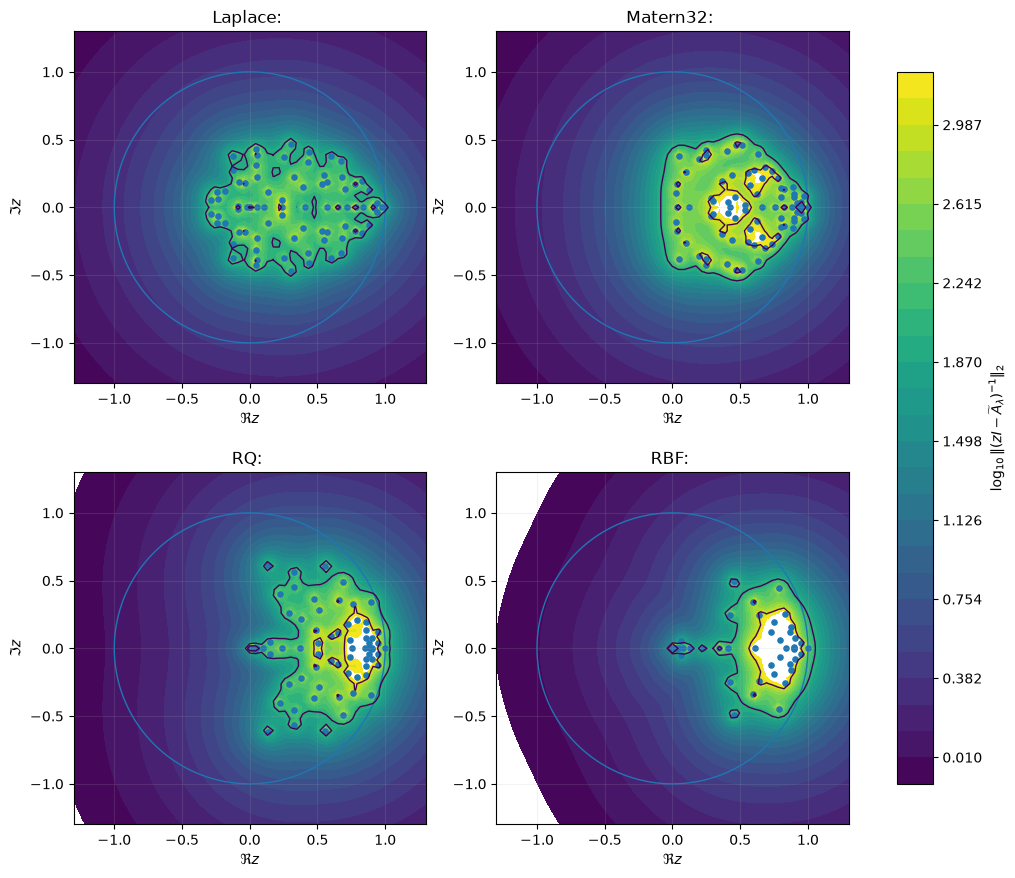

In [22]:

# Use a common log-resolvent range so the four panels are visually comparable.

all_logs = np.concatenate([
    models[k]["pseudo"]["log10_R"].ravel()
    for k in KERNELS
])

# Robust upper limit prevents a single grid point sitting nearly on an
# eigenvalue from dominating the entire color scale.
vmin = float(np.percentile(all_logs, 2.0))
vmax = float(np.percentile(all_logs, 99.0))
levels = np.linspace(vmin, vmax, 28)

fig, axes = plt.subplots(2, 2, figsize=(12.5, 10.5))
axes = axes.ravel()

mappable = None
theta = np.linspace(0.0, 2.0 * np.pi, 500)

for ax, kind in zip(axes, KERNELS):
    m = models[kind]
    ps = m["pseudo"]

    XX, YY = np.meshgrid(ps["xs"], ps["ys"])

    mappable = ax.contourf(
        XX,
        YY,
        ps["log10_R"],
        levels=levels,
    )

    eigs = np.linalg.eigvals(m["Atilde"])
    ax.scatter(np.real(eigs), np.imag(eigs), s=14)
    ax.plot(np.cos(theta), np.sin(theta), linewidth=1.0)

    # Explicit epsilon-pseudospectral contours.
    for eps in EPS_LEVELS:
        ax.contour(
            XX,
            YY,
            ps["log10_R"],
            levels=[np.log10(1.0 / eps)],
            linewidths=1.0,
        )

    ax.set_aspect("equal", adjustable="box")
    ax.set_xlim(-GRID_LIM, GRID_LIM)
    ax.set_ylim(-GRID_LIM, GRID_LIM)
    ax.set_xlabel(r"$\Re z$")
    ax.set_ylabel(r"$\Im z$")
    ax.set_title(
        f"{kind}: "
        #f"$\\widehat{{\\mathcal K}}$={ps['kreiss_hat']:.2f}"
    )
    ax.grid(alpha=0.15)

fig.colorbar(
    mappable,
    ax=axes.tolist(),
    shrink=0.88,
    label=r"$\log_{10}\|(zI-\widetilde A_\lambda)^{-1}\|_2$",
)

plt.savefig(
    os.path.join(OUTDIR, "EI_KEDMD_pseudospectra.png"),
    dpi=400,
    bbox_inches="tight",
)
plt.show()


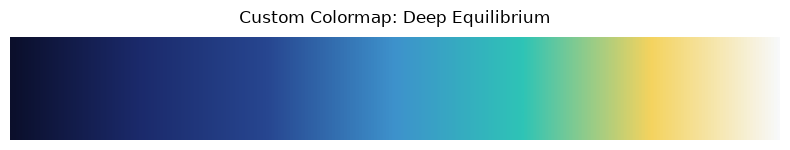

In [23]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# -------------------------------------------------
# My custom gradient: "Deep Equilibrium"
# -------------------------------------------------
deep_equilibrium_colors = [
    #"#26619C",  # lapis lazuli 
    #"#66023C",  # tyrian purple
    "#0b0f2b",  # midnight navy
    "#1b2a6b",  # deep indigo
    "#274690",  # royal blue
    "#3e92cc",  # soft blue
    "#2ec4b6",  # teal
    "#f4d35e",  # warm gold
    "#f8f9fa"   # ivory highlight
]

deep_equilibrium = LinearSegmentedColormap.from_list(
    "deep_equilibrium",
    deep_equilibrium_colors,
    N=256
)

# -------------------------------------------------
# Demo: show gradient
# -------------------------------------------------
gradient = np.linspace(0, 1, 512).reshape(1, -1)

plt.figure(figsize=(8, 1.6))
plt.imshow(gradient, aspect="auto", cmap=deep_equilibrium)
plt.axis("off")
plt.title("Custom Colormap: Deep Equilibrium", pad=10)
plt.tight_layout()
plt.show()

In [24]:
from matplotlib.colors import LinearSegmentedColormap

koopman_conf_cmap = LinearSegmentedColormap.from_list(
    "koopman_conf_cmap",
    [
        "#0b1021",  # deep midnight
        "#1b2a6b",  # indigo-blue
        "#2457a6",  # royal blue
        "#1f9e89",  # teal-green
        "#7ad151",  # soft yellow-green
        "#f6d746",  # warm gold
    ],
    N=256,
)

In [25]:
from matplotlib.colors import LinearSegmentedColormap

koopman_purple_cmap = LinearSegmentedColormap.from_list(
    "koopman_purple_cmap",
    [
        "#12001f",  # almost-black purple
        "#2d0a4e",  # deep plum
        "#5a189a",  # rich purple
        "#7b2cbf",  # vivid violet
        "#4361ee",  # indigo-blue
        "#00b4d8",  # cool cyan
        "#90e0ef",  # pale cyan
        "#ffd166",  # warm gold for strongest response
    ],
    N=256,
)

In [26]:
koopman_purple_luxe = LinearSegmentedColormap.from_list(
    "koopman_purple_luxe",
    [
        "#0d001a",  # black-purple
        "#240046",  # deep violet
        "#3c096c",  # royal purple
        "#5a189a",  # saturated purple
        "#7b2cbf",  # violet
        "#3a86ff",  # electric blue
        "#00b4d8",  # cyan
        "#72efdd",  # aqua
        "#ffb703",  # gold
    ],
    N=256,
)

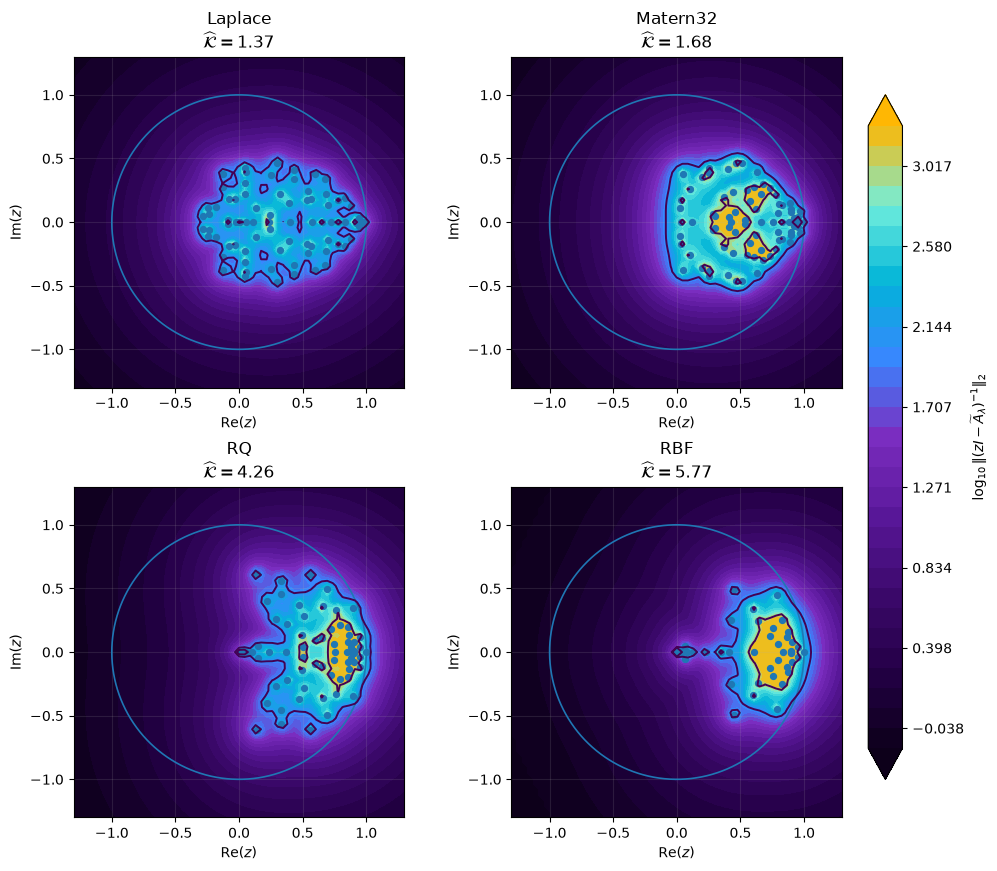

In [27]:
# ------------------------------------------------------------
# Publication-safe pseudospectral plot
# ------------------------------------------------------------

all_logs = np.concatenate([
    models[k]["pseudo"]["log10_R"].ravel()
    for k in KERNELS
])

# Common robust scale across ALL kernels
vmin = float(np.percentile(all_logs, 1.0))
vmax = float(np.percentile(all_logs, 99.0))

levels = np.linspace(vmin, vmax, 32)

fig, axes = plt.subplots(
    2, 2,
    figsize=(10.2, 8.6),
    constrained_layout=True
)
axes = axes.ravel()

theta = np.linspace(0.0, 2.0 * np.pi, 600)

mappable = None

for ax, kind in zip(axes, KERNELS):

    m = models[kind]
    ps = m["pseudo"]

    XX, YY = np.meshgrid(ps["xs"], ps["ys"])

    # IMPORTANT:
    # clip values to plotting range so there are no artificial white holes
    Zplot = np.clip(ps["log10_R"], vmin, vmax)

    mappable = ax.contourf(
        XX,
        YY,
        Zplot,
        levels=levels,
        extend="both",
        cmap=koopman_purple_luxe
    )

    # Koopman surrogate eigenvalues
    eigs = np.linalg.eigvals(m["Atilde"])

    ax.scatter(
        np.real(eigs),
        np.imag(eigs),
        s=18,
        zorder=5,
        label="eigenvalues",
    )

    # Unit circle
    ax.plot(
        np.cos(theta),
        np.sin(theta),
        linewidth=1.2,
        zorder=4
    )

    # epsilon-pseudospectral boundaries
    for eps in EPS_LEVELS:

        threshold = np.log10(1.0 / eps)

        # Only draw if threshold falls inside the numerical range
        if ps["log10_R"].min() <= threshold <= ps["log10_R"].max():
            ax.contour(
                XX,
                YY,
                ps["log10_R"],
                levels=[threshold],
                linewidths=1.4,
                zorder=6
            )

    ax.set_aspect("equal", adjustable="box")

    ax.set_xlim(-GRID_LIM, GRID_LIM)
    ax.set_ylim(-GRID_LIM, GRID_LIM)

    ax.set_xlabel(r"$\mathrm{Re}(z)$")
    ax.set_ylabel(r"$\mathrm{Im}(z)$")

    ax.set_title(
        f"{kind}\n"
        rf"$\widehat{{\mathcal{{K}}}}={ps['kreiss_hat']:.2f}$"
    )

    ax.grid(alpha=0.15)

cbar = fig.colorbar(
    mappable,
    ax=axes.tolist(),
    shrink=0.90,
    pad=0.03,
    extend="both"
)

cbar.set_label(
    r"$\log_{10}\|(zI-\widetilde A_\lambda)^{-1}\|_2$"
)

plt.savefig(
    os.path.join(
        OUTDIR,
        "EI_KEDMD_pseudospectra_clean.pdf"
    ),
    dpi=500,
    bbox_inches="tight"
)

plt.show()

In [28]:

pseudo_rows = []

for kind in KERNELS:
    m = models[kind]
    td = m["transient"]
    ps = m["pseudo"]

    row = {
        "kernel": kind,
        "gamma": m["gamma"],
        "rho_Atilde": td["rho"],
        "peak_G": td["peak"],
        "t_peak": td["t_peak"],
        "Kreiss_hat": ps["kreiss_hat"],
    }

    for eps in EPS_LEVELS:
        row[f"r_eps_{eps:.0e}"] = ps["radii"][eps]
        row[f"grid_boundary_hit_{eps:.0e}"] = ps["boundary_warning"][eps]

    pseudo_rows.append(row)

pseudospectral_table = pd.DataFrame(pseudo_rows)
display(pseudospectral_table)

pseudospectral_table.to_csv(
    os.path.join(OUTDIR, "EI_pseudospectral_summary.csv"),
    index=False,
)


,kernel,gamma,rho_Atilde,peak_G,t_peak,Kreiss_hat,r_eps_1e-02,grid_boundary_hit_1e-02,r_eps_1e-03,grid_boundary_hit_1e-03
0,Laplace,1.225703,1.000015,1.847468,10,1.369607,0.996667,False,0.910000,False
1,Matern32,0.977276,0.999975,3.057903,16,1.676068,1.000428,False,0.953333,False
2,RQ,0.977276,1.000005,11.742282,13,4.261013,1.014407,False,0.962156,False
3,RBF,0.977276,1.000006,16.958628,12,5.772601,1.043605,False,0.954318,False



### Important note about \(\rho(\widetilde A_\lambda)\approx 1\)

Do **not** compare the spectral radius of the finite KEDMD surrogate directly with the spectral radius of the physical \(2\times2\) state transition matrix.

The Koopman operator acts on observables and contains the constant observable as an eigenfunction with eigenvalue \(1\). A kernel surrogate may therefore naturally exhibit an eigenvalue very close to \(1\), even though the physical state perturbations decay.

The finite-time question is instead whether the normalized surrogate has a strongly inflated resolvent and large induced powers relative to the otherwise stable underlying neural dynamics.



## 7. Optional exact state-space pseudospectrum

This is a **reference diagnostic**, not an equality with the Koopman pseudospectrum.

The \(2\times2\) matrix \(F=e^{J\Delta t}\) acts on physical state perturbations, whereas \(\widetilde A_\lambda\) acts in the kernel-induced surrogate geometry.

Still, plotting the exact state-space resolvent gives useful context for how modest the ground-truth linear system is.


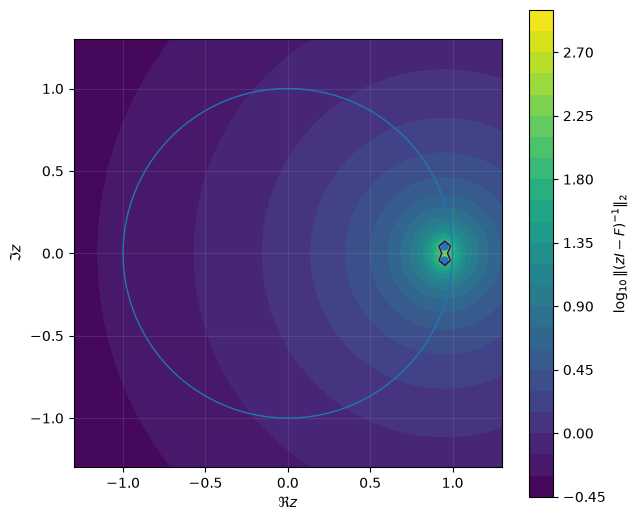

Exact physical-state grid Kreiss estimate = 1.2509377836224813
Exact physical-state pseudospectral radii = {0.01: 0.9543176736402937, 0.001: nan}


In [29]:

true_ps = resolvent_grid(
    F,
    grid_lim=GRID_LIM,
    grid_n=GRID_N,
    eps_levels=EPS_LEVELS,
)

XX, YY = np.meshgrid(true_ps["xs"], true_ps["ys"])

fig, ax = plt.subplots(figsize=(6.5, 5.5))

cf = ax.contourf(
    XX,
    YY,
    true_ps["log10_R"],
    levels=28,
)

ax.scatter(
    np.real(np.linalg.eigvals(F)),
    np.imag(np.linalg.eigvals(F)),
    s=25,
)

ax.plot(np.cos(theta), np.sin(theta), linewidth=1.0)

for eps in EPS_LEVELS:
    ax.contour(
        XX,
        YY,
        true_ps["log10_R"],
        levels=[np.log10(1.0 / eps)],
        linewidths=1.0,
    )

ax.set_aspect("equal", adjustable="box")
ax.set_xlim(-GRID_LIM, GRID_LIM)
ax.set_ylim(-GRID_LIM, GRID_LIM)
ax.set_xlabel(r"$\Re z$")
ax.set_ylabel(r"$\Im z$")
#ax.set_title(
#    "Exact physical-state map: "
#    + rf"$\widehat{{\mathcal K}}={true_ps['kreiss_hat']:.2f}$"
#)
ax.grid(alpha=0.15)

fig.colorbar(
    cf,
    ax=ax,
    label=r"$\log_{10}\|(zI-F)^{-1}\|_2$",
)

plt.tight_layout()
plt.savefig(
    os.path.join(OUTDIR, "EI_exact_state_pseudospectrum.png"),
    dpi=400,
    bbox_inches="tight",
)
plt.show()

print("Exact physical-state grid Kreiss estimate =", true_ps["kreiss_hat"])
print("Exact physical-state pseudospectral radii =", true_ps["radii"])



## 8. Optional regularization sensitivity

A reviewer will reasonably ask whether the kernel hierarchy is an artifact of one chosen \(\lambda\).

This inexpensive cell recomputes only the transient diagnostics for several regularization values. It does **not** recompute the expensive pseudospectral grids.


In [30]:

LAMBDA_SWEEP = [1e-4, 1e-5, 1e-6, 1e-7]

lambda_rows = []

for lam in LAMBDA_SWEEP:
    for kind in KERNELS:
        m = build_kedmd(X, Y, kind, lam=lam)
        td = transient_diagnostics(m["Atilde"], T=T_TRANSIENT)

        lambda_rows.append({
            "lambda": lam,
            "kernel": kind,
            "gamma": m["gamma"],
            "cond_Glambda": np.linalg.cond(m["Glam"]),
            "rho_Atilde": td["rho"],
            "peak_G": td["peak"],
            "t_peak": td["t_peak"],
        })

lambda_table = pd.DataFrame(lambda_rows)
display(lambda_table)

lambda_table.to_csv(
    os.path.join(OUTDIR, "EI_lambda_sensitivity.csv"),
    index=False,
)


,lambda,kernel,gamma,cond_Glambda,rho_Atilde,peak_G,t_peak
0,1.000000e-04,Laplace,1.225703,1.637853e+03,1.000017,1.845480,10
1,1.000000e-04,Matern32,0.977276,1.692983e+05,0.999962,2.958812,15
2,1.000000e-04,RQ,0.977276,5.438335e+05,0.999996,5.211016,12
3,1.000000e-04,RBF,0.977276,4.906974e+05,0.999849,6.233504,11
4,1.000000e-05,Laplace,1.225703,1.645157e+03,1.000015,1.847287,10
5,1.000000e-05,Matern32,0.977276,2.651881e+05,0.999974,3.045281,16
6,1.000000e-05,RQ,0.977276,5.438190e+06,0.999997,7.910468,12
7,1.000000e-05,RBF,0.977276,4.906965e+06,0.999957,9.831805,13
8,1.000000e-06,Laplace,1.225703,1.645891e+03,1.000015,1.847468,10
9,1.000000e-06,Matern32,0.977276,2.811101e+05,0.999975,3.057903,16


J eigenvalues:
[-1.+0.87178j -1.-0.87178j]

F eigenvalues:
[0.950326+0.04145j 0.950326-0.04145j]

rho(F) = 0.9512294245007141

Snapshot sanity:
X_MECH shape = (80, 2)
Y_MECH shape = (80, 2)
X_MECH finite = True
Y_MECH finite = True
unique X rows = 80

Kernel scales:
Laplace    gamma = 1.22570313
Matern32   gamma = 0.97727632
RQ         gamma = 0.97727632
RBF        gamma = 0.97727632

lambda = 1e-04
  building Laplace ...
    gamma=1.22570 | cond=1.638e+03 | peak_G=1.8455 | corr_peak=3.4019e+00
  building Matern32 ...
    gamma=0.97728 | cond=1.693e+05 | peak_G=2.9588 | corr_peak=3.7440e+00
  building RQ ...
    gamma=0.97728 | cond=5.438e+05 | peak_G=5.2110 | corr_peak=5.7478e+00
  building RBF ...
    gamma=0.97728 | cond=4.907e+05 | peak_G=6.2335 | corr_peak=6.9519e+00

lambda = 1e-05
  building Laplace ...
    gamma=1.22570 | cond=1.645e+03 | peak_G=1.8473 | corr_peak=3.4022e+00
  building Matern32 ...
    gamma=0.97728 | cond=2.652e+05 | peak_G=3.0453 | corr_peak=3.7508e+00
  buil

,lambda,kernel,gamma,cond_Glambda,rho_Atilde,opnorm_G,peak_G,t_peak,corr_C0,corr_peak,corr_t_peak,corr_peak_rel,corr_t_peak_rel,identity_error
0,1.000000e-04,Laplace,1.225703,1.637853e+03,1.000017,1.465212,1.845480,10,3.568219,3.401894,1,0.953387,1,2.030000e-14
1,1.000000e-04,Matern32,0.977276,1.692983e+05,0.999962,1.180579,2.958812,15,3.867656,3.743951,1,0.968016,1,8.170563e-13
2,1.000000e-04,RQ,0.977276,5.438335e+05,0.999996,1.315857,5.211016,12,5.880773,5.747850,1,0.977397,1,1.070285e-11
3,1.000000e-04,RBF,0.977276,4.906974e+05,0.999849,1.349500,6.233504,11,7.456853,6.951888,1,0.932282,1,1.678628e-11
4,1.000000e-05,Laplace,1.225703,1.645157e+03,1.000015,1.465956,1.847287,10,3.568458,3.402192,1,0.953407,1,2.010642e-14
5,1.000000e-05,Matern32,0.977276,2.651881e+05,0.999974,1.182273,3.045281,16,3.874723,3.750824,1,0.968024,1,1.116057e-12
6,1.000000e-05,RQ,0.977276,5.438190e+06,0.999997,1.399955,7.910468,12,6.223142,6.123931,1,0.984058,1,7.328638e-11
7,1.000000e-05,RBF,0.977276,4.906965e+06,0.999957,1.451162,9.831805,13,8.570114,8.366629,1,0.976256,1,1.358361e-10
8,1.000000e-06,Laplace,1.225703,1.645891e+03,1.000015,1.466030,1.847468,10,3.568482,3.402222,1,0.953409,1,1.952687e-14
9,1.000000e-06,Matern32,0.977276,2.811101e+05,0.999975,1.182474,3.057903,16,3.875491,3.751576,1,0.968026,1,1.009254e-12



Saved CSV: EI_kernel_koopman_results/EI_lambda_mechanistic_sweep.csv


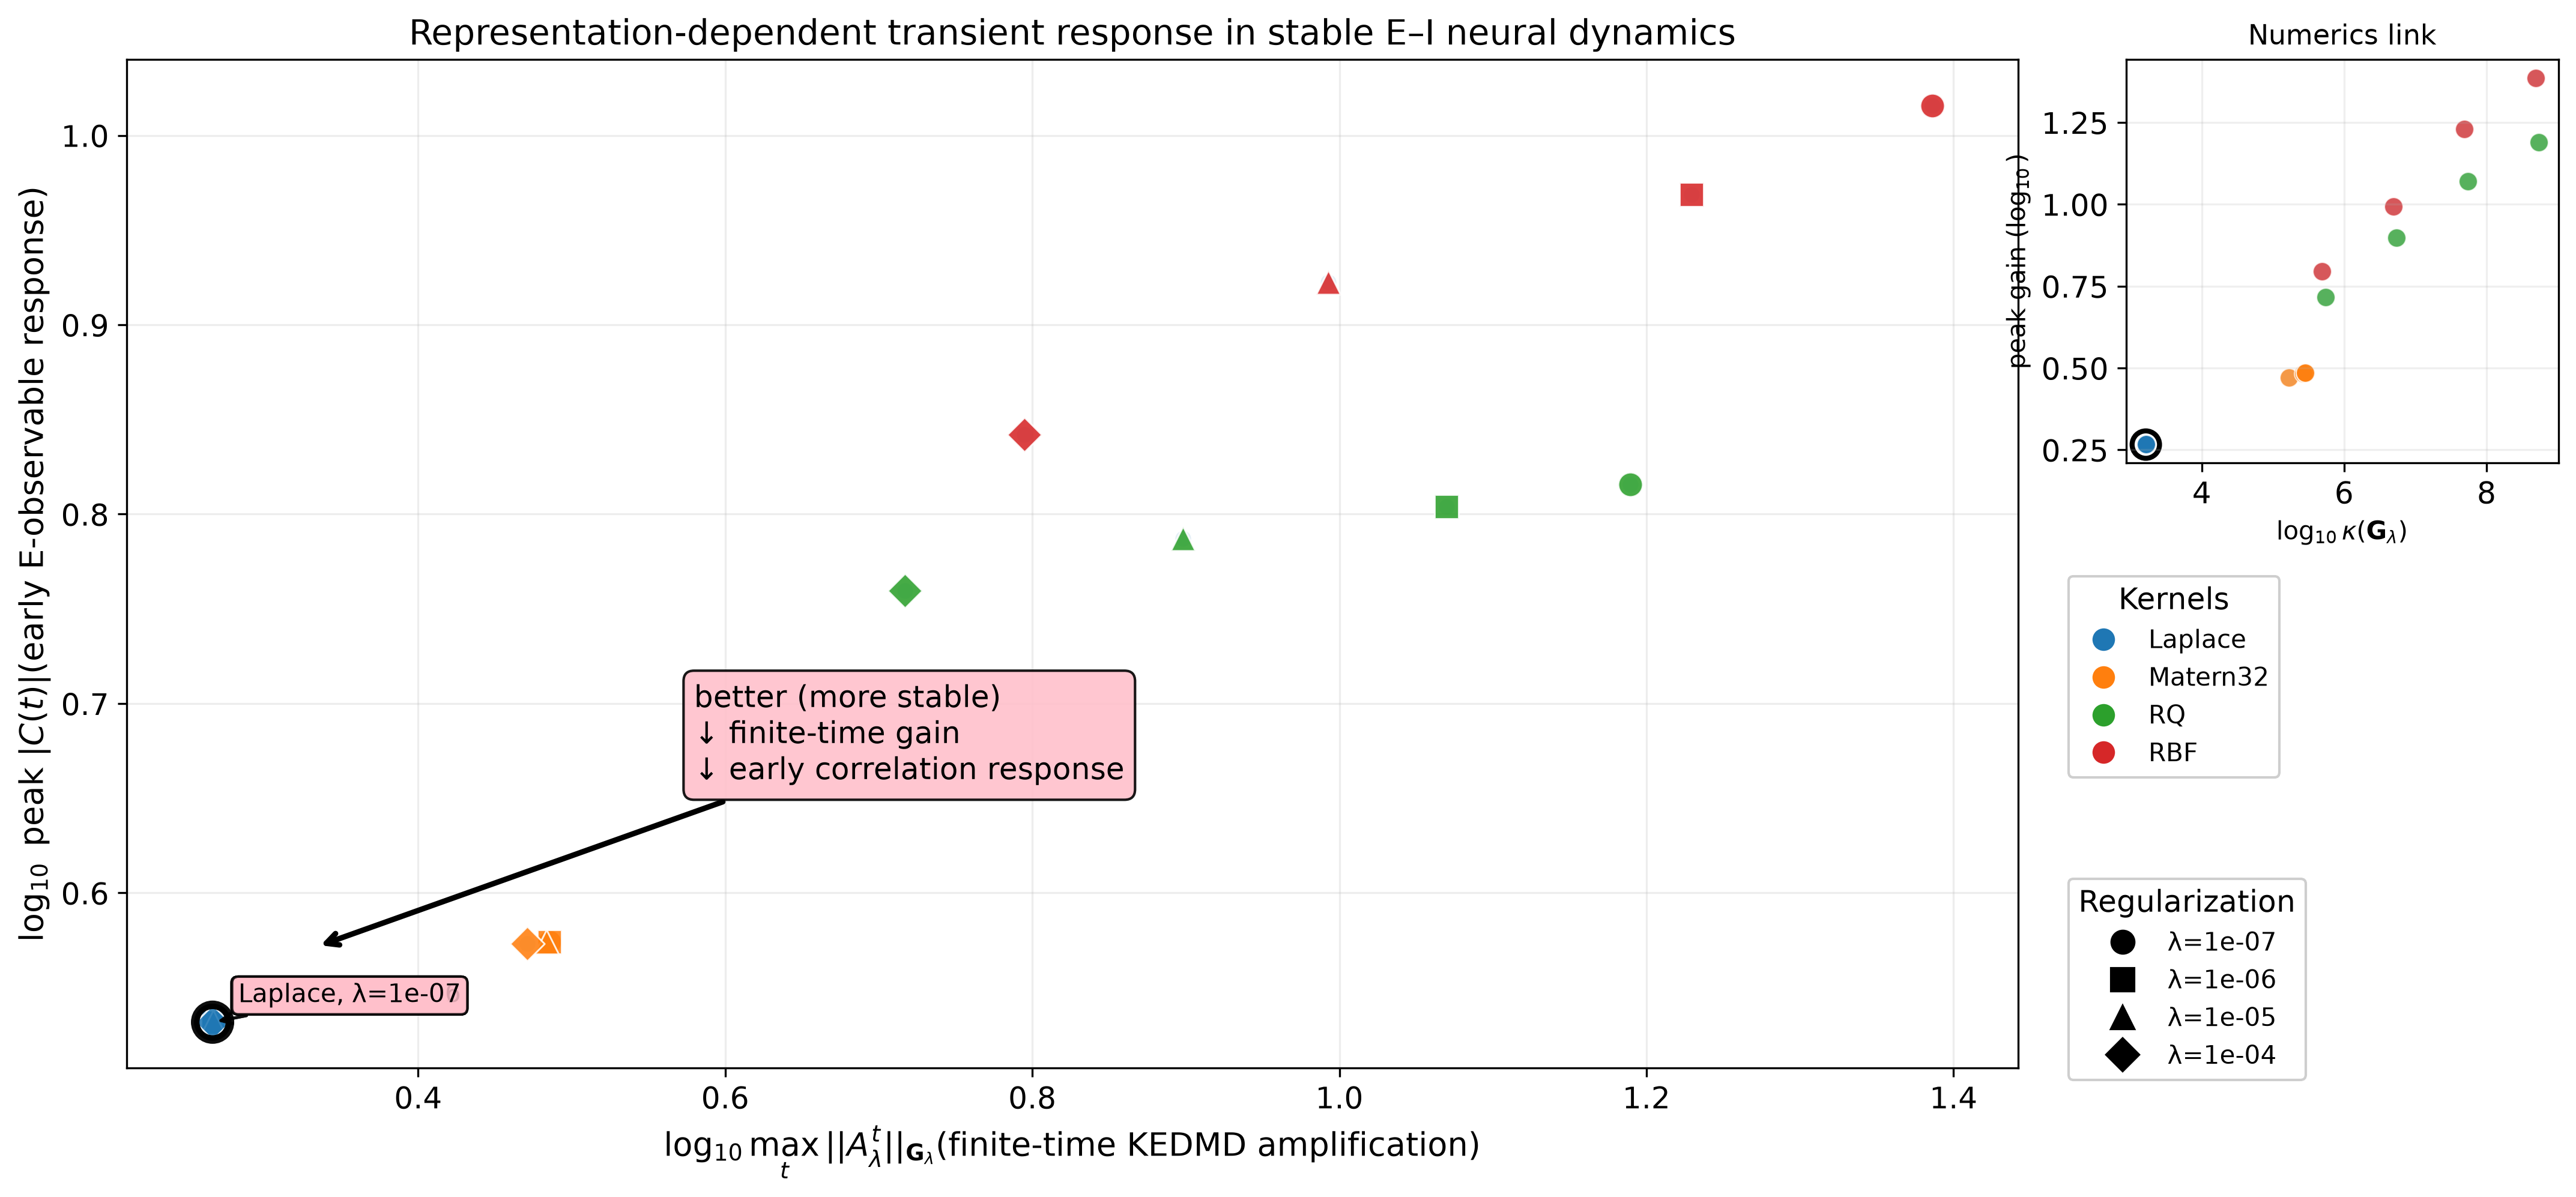


Saved figure:
EI_kernel_koopman_results/EI_neural_mechanistic_master.png
EI_kernel_koopman_results/EI_neural_mechanistic_master.pdf


In [31]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

# ============================================================
# SELF-CONTAINED MECHANISTIC INTERPRETABILITY EXPERIMENT
# Stable linear E-I neural dynamics
#
# Mechanism:
#
#   cond(G_lambda)
#        -->
#   finite-time KEDMD gain
#        -->
#   observable-correlation response
#
# This cell deliberately reconstructs X and Y locally so that
# corrupted/notebook-overwritten variables cannot contaminate it.
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.lines import Line2D
from scipy.linalg import expm, eigh, solve, svdvals
from scipy.spatial.distance import cdist


# ============================================================
# 0. CONFIGURATION
# ============================================================

SEED = 42
M_MECH = 80

DT = 0.05
T_TRANSIENT = 60

# old-style early-correlation horizon
CORR_HORIZON = 10

LAMBDA_SWEEP = [
    1e-4,
    1e-5,
    1e-6,
    1e-7,
]

KERNELS = [
    "Laplace",
    "Matern32",
    "RQ",
    "RBF",
]

# Neural observable:
# "E"   = excitatory deviation
# "I"   = inhibitory deviation
# "E-I" = difference
OBSERVABLE = "E"

# False = old-style raw |C(n)|
# True  = |C(n)|/|C(0)|
USE_RELATIVE_CORRELATION = False

OUTDIR_MECH = "EI_kernel_koopman_results"
os.makedirs(OUTDIR_MECH, exist_ok=True)

OUT_CSV = os.path.join(
    OUTDIR_MECH,
    "EI_lambda_mechanistic_sweep.csv"
)

OUT_PNG = os.path.join(
    OUTDIR_MECH,
    "EI_neural_mechanistic_master.png"
)

OUT_PDF = os.path.join(
    OUTDIR_MECH,
    "EI_neural_mechanistic_master.pdf"
)


# ============================================================
# 1. EXACT STABLE E-I DYNAMICS
# ============================================================

J_MECH = np.array(
    [
        [0.8, -4.0],
        [1.0, -2.8],
    ],
    dtype=float,
)

F_MECH = expm(
    J_MECH * DT
)

print("J eigenvalues:")
print(np.linalg.eigvals(J_MECH))

print("\nF eigenvalues:")
print(np.linalg.eigvals(F_MECH))

print(
    "\nrho(F) =",
    np.max(
        np.abs(
            np.linalg.eigvals(F_MECH)
        )
    )
)


# ============================================================
# 2. RECREATE THE ORIGINAL SNAPSHOT DATA LOCALLY
#
# Original notebook:
#
# X ~ Uniform([-1,1]^2)
# Y = F X
#
# ============================================================

rng_mech = np.random.default_rng(
    SEED
)

X_MECH = rng_mech.uniform(
    -1.0,
    1.0,
    size=(M_MECH, 2)
)

Y_MECH = X_MECH @ F_MECH.T


# ------------------------------------------------------------
# Hard sanity checks BEFORE any kernel calculation
# ------------------------------------------------------------

assert X_MECH.shape == (M_MECH, 2)
assert Y_MECH.shape == (M_MECH, 2)

assert np.all(
    np.isfinite(X_MECH)
)

assert np.all(
    np.isfinite(Y_MECH)
)

print("\nSnapshot sanity:")
print("X_MECH shape =", X_MECH.shape)
print("Y_MECH shape =", Y_MECH.shape)
print("X_MECH finite =", np.all(np.isfinite(X_MECH)))
print("Y_MECH finite =", np.all(np.isfinite(Y_MECH)))

print(
    "unique X rows =",
    np.unique(
        X_MECH,
        axis=0
    ).shape[0]
)


# ============================================================
# 3. KERNELS
# ============================================================

def pairwise_distance(
    A,
    B,
    metric="euclidean"
):

    A = np.asarray(
        A,
        dtype=float
    )

    B = np.asarray(
        B,
        dtype=float
    )

    if (
        A.ndim != 2
        or
        B.ndim != 2
    ):
        raise ValueError(
            "Kernel inputs must be 2-D arrays."
        )

    if (
        not np.all(np.isfinite(A))
        or
        not np.all(np.isfinite(B))
    ):
        raise ValueError(
            "Kernel inputs contain NaN or Inf."
        )

    return cdist(
        A,
        B,
        metric=metric
    )


def safe_median_scale(
    X,
    kind
):

    metric = (
        "cityblock"
        if kind == "Laplace"
        else "euclidean"
    )

    D = pairwise_distance(
        X,
        X,
        metric=metric
    )

    positive = D[
        np.isfinite(D)
        &
        (D > 0.0)
    ]

    # This explicitly catches the error you just saw.
    if positive.size == 0:
        raise ValueError(
            f"{kind}: no positive finite pairwise distances. "
            "The snapshot matrix is empty, degenerate, or corrupted."
        )

    gamma = float(
        np.median(
            positive
        )
    )

    if (
        not np.isfinite(gamma)
        or
        gamma <= 0.0
    ):
        raise ValueError(
            f"{kind}: invalid gamma={gamma}"
        )

    return gamma


def kernel_matrix(
    A,
    B,
    kind,
    gamma
):

    if (
        not np.isfinite(gamma)
        or
        gamma <= 0.0
    ):
        raise ValueError(
            f"Invalid gamma for {kind}: {gamma}"
        )

    if kind == "Laplace":

        R = pairwise_distance(
            A,
            B,
            metric="cityblock"
        )

        K = np.exp(
            -R / gamma
        )

    else:

        R = pairwise_distance(
            A,
            B,
            metric="euclidean"
        )

        if kind == "Matern32":

            q = (
                np.sqrt(3.0)
                * R
                / gamma
            )

            K = (
                (1.0 + q)
                *
                np.exp(-q)
            )

        elif kind == "RQ":

            K = (
                1.0
                +
                (R ** 2)
                /
                (2.0 * gamma ** 2)
            ) ** (-1.0)

        elif kind == "RBF":

            K = np.exp(
                -(R ** 2)
                /
                (2.0 * gamma ** 2)
            )

        else:
            raise ValueError(
                f"Unknown kernel: {kind}"
            )

    if not np.all(
        np.isfinite(K)
    ):
        raise ValueError(
            f"{kind}: kernel matrix contains NaN/Inf."
        )

    return K


# ------------------------------------------------------------
# Check scales now
# ------------------------------------------------------------

print("\nKernel scales:")

for kind in KERNELS:

    gamma_test = safe_median_scale(
        X_MECH,
        kind
    )

    print(
        f"{kind:10s} gamma = "
        f"{gamma_test:.8f}"
    )


# ============================================================
# 4. SPD SQUARE ROOTS
# ============================================================

def spd_sqrt_and_invsqrt(
    G,
    floor=1e-14
):

    Gs = 0.5 * (
        G + G.T
    )

    if not np.all(
        np.isfinite(Gs)
    ):
        raise ValueError(
            "G contains NaN/Inf before eigendecomposition."
        )

    evals, U = eigh(
        Gs
    )

    evals = np.maximum(
        evals,
        floor
    )

    Ghalf = (
        U
        * np.sqrt(evals)
    ) @ U.T

    Gmhalf = (
        U
        * (
            1.0
            /
            np.sqrt(evals)
        )
    ) @ U.T

    return (
        Ghalf,
        Gmhalf
    )


# ============================================================
# 5. SAFE KEDMD CONSTRUCTION
# ============================================================

def build_kedmd_mech(
    X,
    Y,
    kind,
    lam
):

    gamma = safe_median_scale(
        X,
        kind
    )

    GX = kernel_matrix(
        X,
        X,
        kind,
        gamma
    )

    AX = kernel_matrix(
        Y,
        X,
        kind,
        gamma
    )

    Glam = (
        GX
        +
        lam
        *
        np.eye(
            GX.shape[0]
        )
    )

    # --------------------------------------------------------
    # Explicit checks before solve
    # --------------------------------------------------------

    if not np.all(
        np.isfinite(Glam)
    ):
        raise ValueError(
            f"{kind}, lambda={lam}: "
            "G_lambda contains NaN/Inf."
        )

    if not np.all(
        np.isfinite(AX)
    ):
        raise ValueError(
            f"{kind}, lambda={lam}: "
            "A_X contains NaN/Inf."
        )

    # --------------------------------------------------------
    # Same KEDMD formula as your notebook
    # --------------------------------------------------------

    A = solve(
        Glam,
        AX,
        assume_a="pos",
        check_finite=True
    )

    Ghalf, Gmhalf = (
        spd_sqrt_and_invsqrt(
            Glam
        )
    )

    Atilde_similarity = (
        Ghalf
        @ A
        @ Gmhalf
    )

    Atilde = (
        Gmhalf
        @ AX
        @ Gmhalf
    )

    rel_identity_error = (
        np.linalg.norm(
            Atilde
            -
            Atilde_similarity,
            ord="fro"
        )
        /
        max(
            np.linalg.norm(
                Atilde,
                ord="fro"
            ),
            1e-16
        )
    )

    return {
        "kind": kind,
        "gamma": gamma,

        "GX": GX,
        "AX": AX,
        "Glam": Glam,

        "A": A,

        "Ghalf": Ghalf,
        "Gmhalf": Gmhalf,

        "Atilde": Atilde,

        "identity_error":
            rel_identity_error,
    }


# ============================================================
# 6. FINITE-TIME TRANSIENT DIAGNOSTICS
# ============================================================

def transient_diagnostics_mech(
    Atilde,
    T
):

    d = Atilde.shape[0]

    env = np.zeros(
        T + 1
    )

    env[0] = 1.0

    P = np.eye(
        d,
        dtype=Atilde.dtype
    )

    for n in range(
        1,
        T + 1
    ):

        P = P @ Atilde

        env[n] = float(
            svdvals(P)[0]
        )

    t_peak = int(
        np.argmax(
            env[1:]
        )
        + 1
    )

    peak = float(
        env[t_peak]
    )

    rho = float(
        np.max(
            np.abs(
                np.linalg.eigvals(
                    Atilde
                )
            )
        )
    )

    return {
        "env": env,
        "t_peak": t_peak,
        "peak": peak,
        "rho": rho,
    }


# ============================================================
# 7. NEURAL OBSERVABLE
# ============================================================

def observable_values(
    X,
    which
):

    if which == "E":

        # excitatory deviation delta E
        return (
            X[:, 0]
            .astype(float)
            .copy()
        )

    if which == "I":

        # inhibitory deviation delta I
        return (
            X[:, 1]
            .astype(float)
            .copy()
        )

    if which == "E-I":

        return (
            X[:, 0]
            -
            X[:, 1]
        ).astype(float)

    raise ValueError(
        "OBSERVABLE must be "
        "'E', 'I', or 'E-I'."
    )


# ============================================================
# 8. CORRELATION DIAGNOSTIC
#
# C_lambda(n)
# =
# v* G_lambda A_lambda^n v
#
# with v chosen from
#
# G_lambda v = f(X)
#
# ============================================================

def correlation_diagnostics_mech(
    model,
    X,
    observable,
    T
):

    Glam = model["Glam"]
    A = model["A"]

    fX = observable_values(
        X,
        observable
    )

    # --------------------------------------------------------
    # Coefficients representing the SAME physical observable
    # for each kernel/regularization geometry
    # --------------------------------------------------------

    v = solve(
        Glam,
        fX,
        assume_a="pos",
        check_finite=True
    )

    # --------------------------------------------------------
    # Initial correlation
    # --------------------------------------------------------

    C0_complex = np.vdot(
        v,
        Glam @ v
    )

    C0_abs = max(
        float(
            np.abs(
                C0_complex
            )
        ),
        1e-16
    )

    C = np.zeros(
        T + 1,
        dtype=np.complex128
    )

    C[0] = C0_complex

    P = np.eye(
        A.shape[0],
        dtype=A.dtype
    )

    for n in range(
        1,
        T + 1
    ):

        P = P @ A

        C[n] = np.vdot(
            v,
            Glam @ (
                P @ v
            )
        )

    C_abs = np.abs(C)

    C_rel = (
        C_abs
        /
        C0_abs
    )

    # exclude n=0 from peak search
    corr_t_peak = int(
        np.argmax(
            C_abs[1:]
        )
        + 1
    )

    corr_peak = float(
        C_abs[
            corr_t_peak
        ]
    )

    corr_t_peak_rel = int(
        np.argmax(
            C_rel[1:]
        )
        + 1
    )

    corr_peak_rel = float(
        C_rel[
            corr_t_peak_rel
        ]
    )

    return {
        "v": v,

        "C": C,
        "C_abs": C_abs,
        "C_rel": C_rel,

        "C0":
            float(
                np.real(
                    C0_complex
                )
            ),

        "corr_peak":
            corr_peak,

        "corr_t_peak":
            corr_t_peak,

        "corr_peak_rel":
            corr_peak_rel,

        "corr_t_peak_rel":
            corr_t_peak_rel,
    }


# ============================================================
# 9. RUN THE COMPLETE LAMBDA SWEEP
# ============================================================

rows = []

sweep_data = {}

for lam in LAMBDA_SWEEP:

    print(
        "\n===================================="
    )

    print(
        f"lambda = {lam:.0e}"
    )

    for kind in KERNELS:

        print(
            f"  building {kind} ..."
        )

        m = build_kedmd_mech(
            X_MECH,
            Y_MECH,
            kind,
            lam
        )

        td = transient_diagnostics_mech(
            m["Atilde"],
            T=T_TRANSIENT
        )

        cd = correlation_diagnostics_mech(
            m,
            X_MECH,
            observable=OBSERVABLE,
            T=CORR_HORIZON
        )

        # ----------------------------------------------------
        # One-step induced norm:
        #
        # ||A_lambda||_G
        # =
        # ||Atilde_lambda||_2
        # ----------------------------------------------------

        opnorm_G = float(
            svdvals(
                m["Atilde"]
            )[0]
        )

        cond_Glambda = float(
            np.linalg.cond(
                m["Glam"]
            )
        )

        row = {
            "lambda": lam,
            "kernel": kind,
            "gamma":
                m["gamma"],

            "cond_Glambda":
                cond_Glambda,

            "rho_Atilde":
                td["rho"],

            "opnorm_G":
                opnorm_G,

            "peak_G":
                td["peak"],

            "t_peak":
                td["t_peak"],

            "corr_C0":
                cd["C0"],

            "corr_peak":
                cd["corr_peak"],

            "corr_t_peak":
                cd["corr_t_peak"],

            "corr_peak_rel":
                cd["corr_peak_rel"],

            "corr_t_peak_rel":
                cd["corr_t_peak_rel"],

            "identity_error":
                m["identity_error"],
        }

        rows.append(
            row
        )

        sweep_data[
            (kind, lam)
        ] = {
            "model": m,
            "transient": td,
            "correlation": cd,
        }

        print(
            f"    gamma={m['gamma']:.5f}"
            f" | cond={cond_Glambda:.3e}"
            f" | peak_G={td['peak']:.4f}"
            f" | corr_peak={cd['corr_peak']:.4e}"
        )


# ============================================================
# 10. SAVE CSV
# ============================================================

df = pd.DataFrame(
    rows
)

print(
    "\n========== COMPLETE TABLE =========="
)

display(df)

df.to_csv(
    OUT_CSV,
    index=False
)

print(
    "\nSaved CSV:",
    OUT_CSV
)


# ============================================================
# 11. PARETO HELPERS
# ============================================================

def pareto_mask_min2(
    x,
    y
):

    x = np.asarray(x)
    y = np.asarray(y)

    n = len(x)

    keep = np.ones(
        n,
        dtype=bool
    )

    for i in range(n):

        dominated = (
            (x <= x[i])
            &
            (y <= y[i])
            &
            (
                (x < x[i])
                |
                (y < y[i])
            )
        )

        dominated[i] = False

        if np.any(
            dominated
        ):
            keep[i] = False

    return keep


def pareto_front_points(
    x,
    y
):

    mask = pareto_mask_min2(
        x,
        y
    )

    xf = np.asarray(x)[mask]
    yf = np.asarray(y)[mask]

    order = np.argsort(
        xf
    )

    return (
        xf[order],
        yf[order],
        mask
    )


# ============================================================
# 12. PREPARE MECHANISTIC QUANTITIES
# ============================================================

eps = 1e-16

df["logCond"] = np.log10(
    np.maximum(
        df["cond_Glambda"],
        eps
    )
)

# CURRENT neural-paper finite-time quantity
df["logGain"] = np.log10(
    np.maximum(
        df["peak_G"],
        eps
    )
)

if USE_RELATIVE_CORRELATION:

    df["corr_plot"] = (
        df["corr_peak_rel"]
    )

    y_label = (
        r"$\log_{10}$ peak $|C(t)| / |C(0)|$"
        "(early E-observable response)"
    )

else:

    df["corr_plot"] = (
        df["corr_peak"]
    )

    y_label = (
        r"$\log_{10}$ peak $|C(t)|$"
        "(early E-observable response)"
    )

df["logCorr"] = np.log10(
    np.maximum(
        df["corr_plot"],
        eps
    )
)


# ============================================================
# 13. PARETO FRONTS
# ============================================================

# numerical frontier:
# cond(G_lambda) vs finite-time gain
_, _, mask_num = (
    pareto_front_points(
        df["logCond"],
        df["logGain"]
    )
)

df["pareto_num"] = (
    mask_num
)

# dynamical frontier:
# finite-time gain vs correlation peak
x_pf, y_pf, mask_dyn = (
    pareto_front_points(
        df["logGain"],
        df["logCorr"]
    )
)

df["pareto_dyn"] = (
    mask_dyn
)


# ============================================================
# 14. FIGURE STYLE
#
# Same architecture as your original master figure.
# No mathtext font.
# ============================================================

plt.rcParams.update({

    "text.usetex": False,

    "font.family":
        "DejaVu Sans",

    "font.size":
        12,

    "axes.titlesize":
        14,

    "axes.labelsize":
        13,

    "legend.fontsize":
        10,

    "pdf.fonttype":
        42,

    "ps.fonttype":
        42,
})


# stable kernel order
kinds = KERNELS.copy()

cmap = plt.get_cmap(
    "tab10"
)

kind_color = {
    kind:
        cmap(i)
    for i, kind
    in enumerate(kinds)
}

lams = sorted(
    df["lambda"].unique()
)

marker_cycle = [
    "o",
    "s",
    "^",
    "D",
    "v",
    "P",
    "X",
    "*",
]

lam_marker = {
    lam:
        marker_cycle[
            i
            %
            len(marker_cycle)
        ]
    for i, lam
    in enumerate(lams)
}

S_MAIN = 95
S_RING = 210


# ============================================================
# 15. CREATE OLD-STYLE MASTER FIGURE
# ============================================================

fig = plt.figure(figsize=(15, 7),dpi=300)

# main panel
ax = fig.add_axes(
    [
        0.08,
        0.10,
        0.70,
        0.80
    ]
)

# conditioning inset
ax_in = fig.add_axes(
    [
        0.82,
        0.58,
        0.16,
        0.32
    ]
)


# ============================================================
# MAIN:
#
# finite-time Koopman amplification versus
# correlation response
# ============================================================

ax.scatter(
    df["logGain"],
    df["logCorr"],

    s=40,
    alpha=0.12,
    linewidths=0
)


for kind in kinds:

    dk = df[
        df["kernel"]
        ==
        kind
    ]

    for lam in lams:

        dkl = dk[
            np.isclose(
                dk["lambda"],
                lam
            )
        ]

        if dkl.empty:
            continue

        ax.scatter(
            dkl["logGain"],
            dkl["logCorr"],

            s=S_MAIN,

            marker=
                lam_marker[lam],

            alpha=0.88,

            edgecolors=
                "white",

            linewidths=
                0.7,

            c=[
                kind_color[
                    kind
                ]
            ],

            zorder=3
        )


# ------------------------------------------------------------
# dynamic Pareto line
# ------------------------------------------------------------

ax.plot(
    x_pf,
    y_pf,

    linewidth=2.2,
    alpha=0.95,

    color="black"
)

ax.scatter(
    x_pf,
    y_pf,

    s=160,

    facecolors="none",
    edgecolors="black",

    linewidths=2.2,

    zorder=6,

    label=(
        "Pareto: lower gain "
        "and lower early correlation"
    )
)


# ------------------------------------------------------------
# numerical Pareto rings
# ------------------------------------------------------------

dnum = df[
    df["pareto_num"]
]

ax.scatter(
    dnum["logGain"],
    dnum["logCorr"],

    s=S_RING,

    facecolors="none",
    edgecolors="black",

    linewidths=2.8,

    zorder=7,

    alpha=0.95,

    label=(
        "Pareto: lower cond(Gλ) "
        "and lower gain"
    )
)


# ------------------------------------------------------------
# annotate best few
# ------------------------------------------------------------

df_sorted = (
    df.sort_values(
        "logCorr"
    )
    .reset_index(
        drop=True
    )
)

topk = min(
    4,
    len(df_sorted)
)

for i in range(
    topk
):

    row = df_sorted.loc[
        i
    ]

    txt = (
        f"{row['kernel']}, "
        f"λ={row['lambda']:.0e}"
    )

    ax.annotate(
        txt,

        (
            row["logGain"],
            row["logCorr"]
        ),

        textcoords=
            "offset points",

        xytext=
            (10, 8),

        fontsize=
            10,

        bbox=dict(
            boxstyle=
                "round,pad=0.25",

            alpha=
                0.85,

            facecolor=
                "pink",

            edgecolor=
                "black",
        ),

        arrowprops=dict(
            arrowstyle=
                "->",

            lw=
                1.2,

            alpha=
                0.5
        ),

        zorder=8
    )


# ------------------------------------------------------------
# better direction
# ------------------------------------------------------------

xmin, xmax = (
    ax.get_xlim()
)

ymin, ymax = (
    ax.get_ylim()
)

ax.annotate(

    "better (more stable)\n"
    "↓ finite-time gain\n"
    "↓ early correlation response",

    xy=(
        xmin
        +
        0.10
        *
        (xmax-xmin),

        ymin
        +
        0.12
        *
        (ymax-ymin)
    ),

    xytext=(
        xmin
        +
        0.30
        *
        (xmax-xmin),

        ymin
        +
        0.33
        *
        (ymax-ymin)
    ),

    arrowprops=dict(
        arrowstyle=
            "->",

        lw=
            2.2
    ),

    fontsize=
        12,

    ha=
        "left",

    va=
        "center",

    bbox=dict(
        boxstyle=
            "round,pad=0.35",

        alpha=
            0.90,

        facecolor=
            "pink",

        edgecolor=
            "black",
    )
)


# ------------------------------------------------------------
# labels — plain text, no mathtext font
# ------------------------------------------------------------

ax.set_xlabel(
    r"$\log_{10} \max_t ||A_\lambda^t||_{\mathbf{G}_\lambda}$"
    "(finite-time KEDMD amplification)"
)

ax.set_ylabel(
    y_label
)

ax.set_title(
    "Representation-dependent transient response in stable E–I neural dynamics"
    #"ill-conditioned kernel geometry → large KEDMD gain "
    #"→ amplified observable response"
)

ax.grid(
    alpha=0.22
)


# ============================================================
# INSET:
#
# cond(G_lambda)
# versus
# finite-time gain
# ============================================================

ax_in.scatter(
    df["logCond"],
    df["logGain"],

    s=45,
    alpha=0.18,
    linewidths=0
)


for kind in kinds:

    dk = df[
        df["kernel"]
        ==
        kind
    ]

    ax_in.scatter(
        dk["logCond"],
        dk["logGain"],

        s=55,

        alpha=0.75,

        c=[
            kind_color[
                kind
            ]
        ],

        edgecolors=
            "white",

        linewidths=
            0.5
    )


ax_in.scatter(
    dnum["logCond"],
    dnum["logGain"],

    s=120,

    facecolors="none",
    edgecolors="black",

    linewidths=2.0
)


ax_in.set_title(
    "Numerics link",
    fontsize=11
)

ax_in.set_xlabel(
    r"$\log_{10} \kappa(\mathbf{G}_\lambda)$",
    fontsize=10
)

ax_in.set_ylabel(
    r"peak gain ($\log_{10}$)",
    fontsize=10
)

ax_in.grid(
    alpha=0.20
)


# ============================================================
# LEGENDS
# ============================================================

kernel_handles = [

    Line2D(
        [0],
        [0],

        marker="o",

        color="none",

        markerfacecolor=
            kind_color[kind],

        markeredgecolor=
            "white",

        markersize=
            10,

        label=
            kind
    )

    for kind
    in kinds
]


lam_handles = [

    Line2D(
        [0],
        [0],

        marker=
            lam_marker[lam],

        color=
            "black",

        linestyle=
            "None",

        markersize=
            9,

        label=
            f"λ={lam:.0e}"
    )

    for lam
    in lams
]


leg1 = ax.legend(

    handles=
        kernel_handles,

    title=
        "Kernels",

    loc=
        "upper left",

    bbox_to_anchor=
        (1.02, 0.5),

    framealpha=
        0.95
)

ax.add_artist(
    leg1
)


ax.legend(

    handles=
        lam_handles,

    title=
        "Regularization",

    loc=
        "upper left",

    bbox_to_anchor=
        (1.02, 0.2),

    framealpha=
        0.95
)


# ============================================================
# SAVE
# ============================================================

fig.savefig(
    OUT_PNG,
    dpi=400,
    bbox_inches="tight"
)

fig.savefig(
    OUT_PDF,
    bbox_inches="tight"
)

plt.show()


print(
    "\nSaved figure:"
)

print(
    OUT_PNG
)

print(
    OUT_PDF
)


Empirical Pareto set in (logGain, logCorr):
    kernel  lambda   peak_G  corr_peak   logGain   logCorr
0  Laplace  0.0001  1.84548   3.401894  0.266109  0.531721


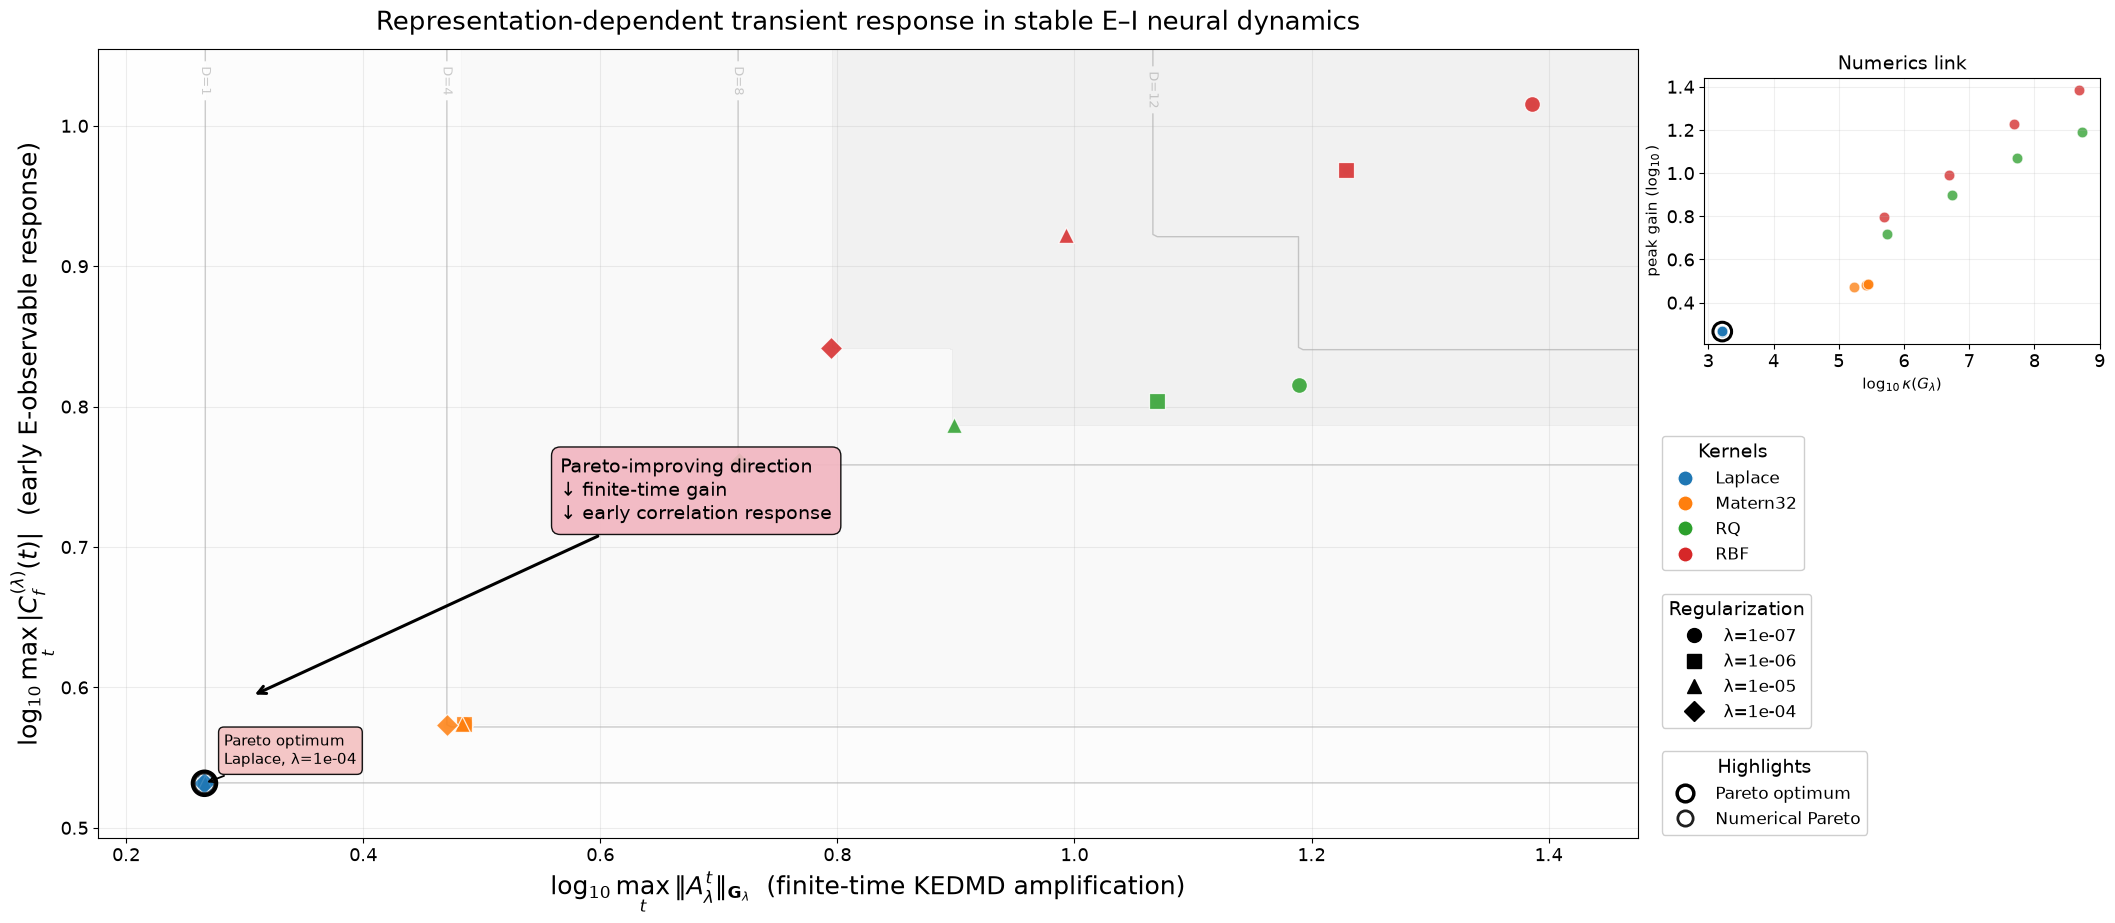

Saved: EI_kernel_koopman_results/EI_pareto_dominance_neurreps.png
Saved: EI_kernel_koopman_results/EI_pareto_dominance_neurreps.pdf


In [32]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ============================================================
# USER SETTINGS
# ============================================================
CSV_PATH = "EI_kernel_koopman_results/EI_lambda_mechanistic_sweep.csv"   # <- change if needed
OUT_PNG  = "EI_kernel_koopman_results/EI_pareto_dominance_neurreps.png"
OUT_PDF  = "EI_kernel_koopman_results/EI_pareto_dominance_neurreps.pdf"

# If your CSV uses slightly different column names, map them here.
# The script will auto-handle the common cases you showed earlier.
COLUMN_ALIASES = {
    "kernel": ["kernel", "kind", "Kernel"],
    "lambda": ["lambda", "lam", "Lambda"],
    "cond_G": ["cond_G", "cond_Glambda", "cond", "kappa_G", "kappaG"],
    "peak_G": ["peak_G", "peak_growth", "peak", "peak_transient_growth"],
    "corr_peak": ["corr_peak", "peak_corr", "corr_response_peak", "peak_C", "corrmax"],
}

# ============================================================
# SMALL HELPERS
# ============================================================
def first_existing_column(df, candidates):
    for c in candidates:
        if c in df.columns:
            return c
    return None


def resolve_columns(df, alias_dict):
    resolved = {}
    missing = []
    for target_name, candidates in alias_dict.items():
        found = first_existing_column(df, candidates)
        if found is None:
            missing.append((target_name, candidates))
        else:
            resolved[target_name] = found
    if missing:
        msg = ["Missing required columns after alias resolution:"]
        for t, cand in missing:
            msg.append(f"  - {t}: tried {cand}")
        msg.append(f"\nColumns found in CSV:\n{list(df.columns)}")
        raise ValueError("\n".join(msg))
    return resolved


def pareto_mask_minimize_2d(x, y):
    """
    Pareto mask for minimization in 2D.
    A point is kept if no other point is <= in both coords and < in at least one.
    """
    x = np.asarray(x)
    y = np.asarray(y)
    n = len(x)
    keep = np.ones(n, dtype=bool)

    for i in range(n):
        if not keep[i]:
            continue
        dominates_i = (x <= x[i]) & (y <= y[i]) & ((x < x[i]) | (y < y[i]))
        dominates_i[i] = False
        if np.any(dominates_i):
            keep[i] = False

    return keep


def dominance_depth_field(x_data, y_data, x_grid, y_grid):
    """
    D(x,y) = number of sampled configurations that dominate location (x,y),
    under minimization in both coordinates.
    """
    XX, YY = np.meshgrid(x_grid, y_grid)
    D = np.zeros_like(XX, dtype=float)

    for xi, yi in zip(x_data, y_data):
        D += ((xi <= XX) & (yi <= YY))

    return XX, YY, D


# ============================================================
# LOAD DATA
# ============================================================
df = pd.read_csv(CSV_PATH)

resolved = resolve_columns(df, COLUMN_ALIASES)

col_kernel   = resolved["kernel"]
col_lambda   = resolved["lambda"]
col_condG    = resolved["cond_G"]
col_peakG    = resolved["peak_G"]
col_corrpeak = resolved["corr_peak"]

# Keep only needed columns
plot_df = df[[col_kernel, col_lambda, col_condG, col_peakG, col_corrpeak]].copy()
plot_df.columns = ["kernel", "lambda", "cond_G", "peak_G", "corr_peak"]

# Sanitize numerics
for c in ["lambda", "cond_G", "peak_G", "corr_peak"]:
    plot_df[c] = pd.to_numeric(plot_df[c], errors="coerce")

plot_df = plot_df.replace([np.inf, -np.inf], np.nan).dropna().reset_index(drop=True)

if len(plot_df) == 0:
    raise ValueError("After cleaning, no valid rows remain in the CSV.")

# Log-objectives
eps = 1e-16
plot_df["logCond"] = np.log10(np.maximum(plot_df["cond_G"].values, eps))
plot_df["logGain"] = np.log10(np.maximum(plot_df["peak_G"].values, eps))
plot_df["logCorr"] = np.log10(np.maximum(plot_df["corr_peak"].values, eps))

# ============================================================
# PARETO STRUCTURE
# ============================================================
# Dynamic plane: minimize (logGain, logCorr)
plot_df["pareto_dyn"] = pareto_mask_minimize_2d(
    plot_df["logGain"].values,
    plot_df["logCorr"].values,
)

# Numerical plane: minimize (logCond, logGain)
plot_df["pareto_num"] = pareto_mask_minimize_2d(
    plot_df["logCond"].values,
    plot_df["logGain"].values,
)

pareto_dyn = plot_df[plot_df["pareto_dyn"]].copy().sort_values("logGain")
pareto_num = plot_df[plot_df["pareto_num"]].copy().sort_values("logCond")

print("\nEmpirical Pareto set in (logGain, logCorr):")
print(pareto_dyn[["kernel", "lambda", "peak_G", "corr_peak", "logGain", "logCorr"]])

# ============================================================
# STYLING
# ============================================================
# Kernel order
kernel_order = ["Laplace", "Matern32", "RQ", "RBF"]
kernel_present = [k for k in kernel_order if k in plot_df["kernel"].unique()]
# Include unexpected names at end if present
for k in plot_df["kernel"].unique():
    if k not in kernel_present:
        kernel_present.append(k)

# Colors (kept close to your recent style)
kernel_color = {
    "Laplace":  "#1f77b4",  # blue
    "Matern32": "#ff7f0e",  # orange
    "RQ":       "#2ca02c",  # green
    "RBF":      "#d62728",  # red
}

# Marker per lambda
lambda_order = sorted(plot_df["lambda"].unique())
marker_cycle = ["o", "s", "^", "D", "v", "P", "X", "*", "<", ">"]
lambda_marker = {lam: marker_cycle[i % len(marker_cycle)] for i, lam in enumerate(lambda_order)}

# ============================================================
# FIGURE LAYOUT
# ============================================================
plt.rcParams.update({
    "font.size": 13,
    "axes.titlesize": 19,
    "axes.labelsize": 18,
    "legend.fontsize": 11,
    "xtick.labelsize": 13,
    "ytick.labelsize": 13,
})

fig = plt.figure(figsize=(22, 9.5))
ax = fig.add_axes([0.07, 0.10, 0.70, 0.83])     # main panel
ax_in = fig.add_axes([0.80, 0.62, 0.18, 0.28])  # inset

# ============================================================
# DOMINANCE-DEPTH CONTOURS ON MAIN PANEL
# ============================================================
x_data = plot_df["logGain"].to_numpy()
y_data = plot_df["logCorr"].to_numpy()

x_span = x_data.max() - x_data.min()
y_span = y_data.max() - y_data.min()

x_grid = np.linspace(
    x_data.min() - 0.08 * max(x_span, 1e-6),
    x_data.max() + 0.08 * max(x_span, 1e-6),
    350
)
y_grid = np.linspace(
    y_data.min() - 0.08 * max(y_span, 1e-6),
    y_data.max() + 0.08 * max(y_span, 1e-6),
    350
)

XX, YY, D = dominance_depth_field(x_data, y_data, x_grid, y_grid)

# subtle filled contours
fill_levels = [-0.5, 0.5, 2.5, 5.5, 9.5, 20.5]
ax.contourf(
    XX, YY, D,
    levels=fill_levels,
    cmap="Greys",
    alpha=0.08,
    zorder=0
)

# contour lines
line_levels = [1, 4, 8, 12]
CS = ax.contour(
    XX, YY, D,
    levels=line_levels,
    colors=["#7f7f7f"] * len(line_levels),
    linewidths=1.0,
    alpha=0.40,
    zorder=1
)

ax.clabel(
    CS,
    inline=True,
    fontsize=9,
    fmt={1: "D=1", 4: "D=4", 8: "D=8", 12: "D=12"}
)

# ============================================================
# MAIN BACKGROUND CLOUD
# ============================================================
ax.scatter(
    plot_df["logGain"],
    plot_df["logCorr"],
    s=36,
    c="lightgray",
    alpha=0.25,
    linewidths=0,
    zorder=2
)

# ============================================================
# MAIN SCATTER BY KERNEL / LAMBDA
# ============================================================
for ker in kernel_present:
    dker = plot_df[plot_df["kernel"] == ker]
    for lam in lambda_order:
        dsub = dker[np.isclose(dker["lambda"], lam)]
        if dsub.empty:
            continue

        ax.scatter(
            dsub["logGain"],
            dsub["logCorr"],
            s=130,
            marker=lambda_marker[lam],
            c=kernel_color.get(ker, "black"),
            alpha=0.85,
            edgecolors="white",
            linewidths=0.9,
            zorder=4
        )

# ============================================================
# EMPIRICAL PARETO SET
# ============================================================
if len(pareto_dyn) > 1:
    ax.plot(
        pareto_dyn["logGain"],
        pareto_dyn["logCorr"],
        color="black",
        linewidth=2.3,
        alpha=0.95,
        zorder=6
    )

ax.scatter(
    pareto_dyn["logGain"],
    pareto_dyn["logCorr"],
    s=290,
    facecolors="none",
    edgecolors="black",
    linewidths=2.8,
    zorder=7,
)

# numerical Pareto rings
ax.scatter(
    pareto_num["logGain"],
    pareto_num["logCorr"],
    s=220,
    facecolors="none",
    edgecolors="#1f1f1f",
    linewidths=2.0,
    zorder=6,
    alpha=0.9
)

# ============================================================
# LABEL TRUE PARETO POINT(S)
# ============================================================
for _, row in pareto_dyn.iterrows():
    label_txt = f"Pareto optimum\n{row['kernel']}, λ={row['lambda']:.0e}"
    ax.annotate(
        label_txt,
        (row["logGain"], row["logCorr"]),
        xytext=(14, 14),
        textcoords="offset points",
        fontsize=11,
        bbox=dict(
            boxstyle="round,pad=0.35",
            facecolor="#f4c2c2",
            edgecolor="black",
            alpha=0.92,
        ),
        arrowprops=dict(
            arrowstyle="->",
            lw=1.3,
            color="black",
        ),
        zorder=10
    )

# ============================================================
# "BETTER DIRECTION" ANNOTATION
# ============================================================
xlo, xhi = ax.get_xlim()
ylo, yhi = ax.get_ylim()

ax.annotate(
    "Pareto-improving direction\n↓ finite-time gain\n↓ early correlation response",
    xy=(xlo + 0.10*(xhi-xlo), ylo + 0.18*(yhi-ylo)),
    xytext=(xlo + 0.30*(xhi-xlo), ylo + 0.44*(yhi-ylo)),
    fontsize=14,
    ha="left",
    va="center",
    bbox=dict(
        boxstyle="round,pad=0.45",
        facecolor="#f2b6c1",
        edgecolor="black",
        alpha=0.92,
    ),
    arrowprops=dict(
        arrowstyle="->",
        lw=2.2,
        color="black",
    ),
    zorder=9
)

# ============================================================
# AXES LABELS / TITLE
# ============================================================
ax.set_xlabel(r"$\log_{10}\max_t \|A_\lambda^t\|_{\mathbf{G}_\lambda}$  (finite-time KEDMD amplification)")
ax.set_ylabel(r"$\log_{10}\max_t |C_f^{(\lambda)}(t)|$  (early E-observable response)")
ax.set_title(
    "Representation-dependent transient response in stable E–I neural dynamics",
    pad=14
)
ax.grid(alpha=0.22)

# ============================================================
# INSET: NUMERICS LINK
# ============================================================
ax_in.scatter(
    plot_df["logCond"],
    plot_df["logGain"],
    s=55,
    c="lightgray",
    alpha=0.22,
    linewidths=0
)

for ker in kernel_present:
    dker = plot_df[plot_df["kernel"] == ker]
    ax_in.scatter(
        dker["logCond"],
        dker["logGain"],
        s=58,
        c=kernel_color.get(ker, "black"),
        alpha=0.75,
        edgecolors="white",
        linewidths=0.5
    )

ax_in.scatter(
    pareto_num["logCond"],
    pareto_num["logGain"],
    s=180,
    facecolors="none",
    edgecolors="black",
    linewidths=2.2,
    zorder=5
)

ax_in.set_title("Numerics link", fontsize=14)
ax_in.set_xlabel(r"$\log_{10}\kappa(G_\lambda)$", fontsize=11)
ax_in.set_ylabel(r"peak gain $(\log_{10})$", fontsize=11)
ax_in.grid(alpha=0.20)

# ============================================================
# LEGENDS
# ============================================================
kernel_handles = []
for ker in kernel_present:
    kernel_handles.append(
        Line2D(
            [0], [0],
            marker="o",
            linestyle="None",
            markerfacecolor=kernel_color.get(ker, "black"),
            markeredgecolor="white",
            markersize=11,
            label=ker
        )
    )

lambda_handles = []
for lam in lambda_order:
    lambda_handles.append(
        Line2D(
            [0], [0],
            marker=lambda_marker[lam],
            linestyle="None",
            color="black",
            markersize=10,
            label=f"λ={lam:.0e}"
        )
    )

special_handles = [
    Line2D([0], [0], marker="o", linestyle="None",
           markerfacecolor="none", markeredgecolor="black",
           markeredgewidth=2.5, markersize=12,
           label="Pareto optimum"),
    Line2D([0], [0], marker="o", linestyle="None",
           markerfacecolor="none", markeredgecolor="#1f1f1f",
           markeredgewidth=2.0, markersize=11,
           label="Numerical Pareto"),
]

leg1 = ax.legend(
    handles=kernel_handles,
    title="Kernels",
    loc="upper left",
    bbox_to_anchor=(1.01, 0.52),
    framealpha=0.95,
    title_fontsize=14,
    fontsize=12
)
ax.add_artist(leg1)

leg2 = ax.legend(
    handles=lambda_handles,
    title="Regularization",
    loc="upper left",
    bbox_to_anchor=(1.01, 0.32),
    framealpha=0.95,
    title_fontsize=14,
    fontsize=12
)
ax.add_artist(leg2)

leg3 = ax.legend(
    handles=special_handles,
    title="Highlights",
    loc="upper left",
    bbox_to_anchor=(1.01, 0.12),
    framealpha=0.95,
    title_fontsize=14,
    fontsize=12
)

# ============================================================
# SAVE
# ============================================================
plt.savefig(OUT_PNG, dpi=400, bbox_inches="tight")
plt.savefig(OUT_PDF, bbox_inches="tight")
plt.show()

print(f"Saved: {OUT_PNG}")
print(f"Saved: {OUT_PDF}")

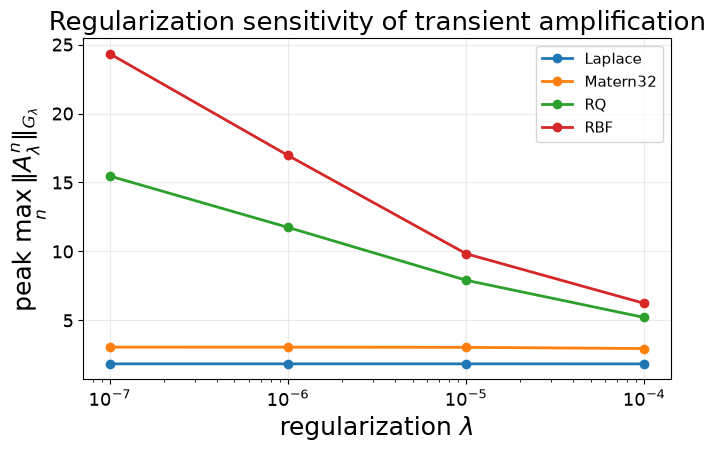

In [33]:

fig, ax = plt.subplots(figsize=(7.0, 4.7))

for kind in KERNELS:
    d = lambda_table[lambda_table["kernel"] == kind].sort_values("lambda")
    ax.plot(
        d["lambda"],
        d["peak_G"],
        marker="o",
        linewidth=2.0,
        label=kind,
    )

ax.set_xscale("log")
ax.set_xlabel(r"regularization $\lambda$")
ax.set_ylabel(r"peak $\max_n\|A_\lambda^n\|_{G_\lambda}$")
ax.set_title("Regularization sensitivity of transient amplification")
ax.grid(alpha=0.25)
ax.legend()

plt.tight_layout()
plt.savefig(
    os.path.join(OUTDIR, "EI_lambda_sensitivity.pdf"),
    dpi=400,
    bbox_inches="tight",
)
plt.show()



# What would count as a useful result?

For this first neuroscience control, the strongest pattern would be:

1. the exact E–I system is asymptotically stable;
2. its true physical transient gain is known exactly and is modest;
3. all KEDMD surrogates fit the same underlying one-step map;
4. kernel choice produces a clear hierarchy in
   \(\max_n\|A_\lambda^n\|_{G_\lambda}\);
5. kernels with larger transient envelopes also show broader resolvent/pseudospectral inflation and larger grid-based Kreiss estimates;
6. the hierarchy remains qualitatively visible under reasonable \(\lambda\)-variation.

With the default parameters, a particularly interesting outcome would be for RQ/RBF to exhibit much larger RKHS transient amplification than Laplace/Matérn while the underlying E–I system itself has only modest finite-time gain.

That would support the precise statement:

> Even for a fully known, stable linear neural-population model, kernel-induced Koopman representation geometry can substantially alter the finite-time behavior of the learned surrogate.

This first experiment is a **controlled ground-truth demonstration**.  
The next nonlinear system should then be Wilson–Cowan, where the same pipeline can be reused with only the data-generation cell replaced.


In [34]:
# ============================================================
# Kreiss grid-resolution convergence experiment
# ============================================================
#
# IMPORTANT:
#   - Do NOT retrain KEDMD.
#   - Do NOT modify Atilde, lambda, gamma, or the snapshots.
#   - We vary ONLY the complex-grid resolution.
#
# Run this cell after the existing models and pseudospectra
# have already been constructed.
# ============================================================

import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.linalg import svdvals


# ------------------------------------------------------------
# CHANGE THESE TWO LINES FOR EACH NOTEBOOK
# ------------------------------------------------------------

SYSTEM_NAME = "Linear E-I"
FILE_PREFIX = "EI"

# Wilson-Cowan:
# SYSTEM_NAME = "Wilson-Cowan"
# FILE_PREFIX = "WC"

# FitzHugh-Nagumo:
# SYSTEM_NAME = "FitzHugh-Nagumo"
# FILE_PREFIX = "FHN"


# ------------------------------------------------------------
# Fixed computational domain
# ------------------------------------------------------------

GRID_LIM_CONV = 1.30

# Nested grids:
# 31 -> 61 -> 121
#
# Keeping 61 is important because it is the grid used for the
# current Table-1 Kreiss values.
GRID_SIZES = [31, 61, 121]


# ============================================================
# Kreiss-only grid calculation
# ============================================================

def kreiss_grid_only(
    Atilde,
    grid_lim=1.30,
    grid_n=61,
):
    """
    Grid-based estimate of the discrete Kreiss constant

        K_hat = max_{z in G, |z| > 1}
                (|z|-1) ||(zI-Atilde)^(-1)||_2.

    This function evaluates only points outside the unit disk,
    because interior points do not enter the Kreiss objective.

    The learned Atilde is kept fixed.
    """

    xs = np.linspace(
        -grid_lim,
        grid_lim,
        grid_n,
    )

    ys = np.linspace(
        -grid_lim,
        grid_lim,
        grid_n,
    )

    d = Atilde.shape[0]

    Iden = np.eye(
        d,
        dtype=complex,
    )

    kreiss_hat = 0.0

    kreiss_location = (
        np.nan + 1j * np.nan
    )

    evaluated_points = 0

    dx = xs[1] - xs[0]
    dy = ys[1] - ys[0]

    for yy in ys:

        for xx in xs:

            z = xx + 1j * yy

            modulus = abs(z)

            # Kreiss objective only requires |z| > 1
            if modulus <= 1.0:
                continue

            evaluated_points += 1

            smin = svdvals(
                z * Iden - Atilde,
                check_finite=False,
            )[-1]

            resolvent = (
                1.0
                / max(
                    float(smin),
                    1e-14,
                )
            )

            value = (
                (modulus - 1.0)
                * resolvent
            )

            if value > kreiss_hat:

                kreiss_hat = value
                kreiss_location = z

    # --------------------------------------------------------
    # Did the maximizer land close to the OUTER box boundary?
    # --------------------------------------------------------

    boundary_tol_x = 0.51 * abs(dx)
    boundary_tol_y = 0.51 * abs(dy)

    outer_boundary_hit = bool(
        (
            abs(kreiss_location.real)
            >= grid_lim - boundary_tol_x
        )
        or
        (
            abs(kreiss_location.imag)
            >= grid_lim - boundary_tol_y
        )
    )

    return {
        "kreiss_hat": float(kreiss_hat),
        "z_star": kreiss_location,
        "abs_z_star": float(
            abs(kreiss_location)
        ),
        "grid_spacing_x": float(dx),
        "grid_spacing_y": float(dy),
        "evaluated_points": int(
            evaluated_points
        ),
        "outer_boundary_hit": (
            outer_boundary_hit
        ),
    }


# ============================================================
# Run grid convergence
# ============================================================

rows = []

total_start = time.time()


for kind in KERNELS:

    Atilde_fixed = models[kind]["Atilde"]

    print("\n" + "=" * 70)
    print(
        f"{SYSTEM_NAME} | {kind}"
    )
    print("=" * 70)

    previous_K = None

    for grid_n in GRID_SIZES:

        start = time.time()

        result = kreiss_grid_only(
            Atilde_fixed,
            grid_lim=GRID_LIM_CONV,
            grid_n=grid_n,
        )

        runtime = (
            time.time() - start
        )

        Khat = result["kreiss_hat"]

        if previous_K is None:

            relative_change = np.nan

        else:

            relative_change = (
                abs(Khat - previous_K)
                / max(abs(Khat), 1e-14)
            )

        rows.append({
            "system": SYSTEM_NAME,
            "kernel": kind,
            "grid_n": grid_n,
            "grid_points_total": (
                grid_n * grid_n
            ),
            "evaluated_exterior_points":
                result[
                    "evaluated_points"
                ],
            "grid_lim": GRID_LIM_CONV,
            "grid_spacing":
                result[
                    "grid_spacing_x"
                ],
            "kreiss_hat": Khat,
            "z_star_real":
                result["z_star"].real,
            "z_star_imag":
                result["z_star"].imag,
            "abs_z_star":
                result["abs_z_star"],
            "outer_boundary_hit":
                result[
                    "outer_boundary_hit"
                ],
            "relative_change_from_previous":
                relative_change,
            "runtime_seconds":
                runtime,
        })

        print(
            f"grid={grid_n:3d} x {grid_n:3d} | "
            f"Khat={Khat:.8f} | "
            f"z*={result['z_star']:.5f} | "
            f"|z*|={result['abs_z_star']:.6f} | "
            f"boundary={result['outer_boundary_hit']} | "
            f"time={runtime:.2f} s"
        )

        previous_K = Khat


total_runtime = (
    time.time() - total_start
)

print(
    "\nTotal grid-convergence runtime = "
    f"{total_runtime:.2f} s"
)


# ============================================================
# Save complete results
# ============================================================

kreiss_conv = pd.DataFrame(rows)

csv_path = os.path.join(
    OUTDIR,
    f"{FILE_PREFIX}_kreiss_grid_convergence.csv",
)

kreiss_conv.to_csv(
    csv_path,
    index=False,
)

print(
    "\nSaved:",
    csv_path,
)

display(kreiss_conv)


Linear E-I | Laplace
grid= 31 x  31 | Khat=1.36960716 | z*=1.12667+0.00000j | |z*|=1.126667 | boundary=False | time=0.29 s
grid= 61 x  61 | Khat=1.36960716 | z*=1.12667+0.00000j | |z*|=1.126667 | boundary=False | time=1.05 s
grid=121 x 121 | Khat=1.37079396 | z*=1.10500+0.00000j | |z*|=1.105000 | boundary=False | time=3.99 s

Linear E-I | Matern32
grid= 31 x  31 | Khat=1.61841254 | z*=1.12667+0.00000j | |z*|=1.126667 | boundary=False | time=0.28 s
grid= 61 x  61 | Khat=1.67606761 | z*=1.08333-0.04333j | |z*|=1.084200 | boundary=False | time=1.04 s
grid=121 x 121 | Khat=1.67606761 | z*=1.08333-0.04333j | |z*|=1.084200 | boundary=False | time=3.98 s

Linear E-I | RQ
grid= 31 x  31 | Khat=3.98276432 | z*=1.12667+0.00000j | |z*|=1.126667 | boundary=False | time=0.28 s
grid= 61 x  61 | Khat=4.26101258 | z*=1.08333-0.08667j | |z*|=1.086794 | boundary=False | time=1.05 s
grid=121 x 121 | Khat=4.30642885 | z*=1.06167-0.10833j | |z*|=1.067180 | boundary=False | time=4.09 s

Linear E-I | RBF
gr

,system,kernel,grid_n,grid_points_total,evaluated_exterior_points,grid_lim,grid_spacing,kreiss_hat,z_star_real,z_star_imag,abs_z_star,outer_boundary_hit,relative_change_from_previous,runtime_seconds
0,Linear E-I,Laplace,31,961,540,1.3,0.086667,1.369607,1.126667,0.000000,1.126667,False,NaN,0.288680
1,Linear E-I,Laplace,61,3721,2052,1.3,0.043333,1.369607,1.126667,0.000000,1.126667,False,0.000000,1.053321
2,Linear E-I,Laplace,121,14641,7936,1.3,0.021667,1.370794,1.105000,0.000000,1.105000,False,0.000866,3.993577
3,Linear E-I,Matern32,31,961,540,1.3,0.086667,1.618413,1.126667,0.000000,1.126667,False,NaN,0.276555
4,Linear E-I,Matern32,61,3721,2052,1.3,0.043333,1.676068,1.083333,-0.043333,1.084200,False,0.034399,1.037228
5,Linear E-I,Matern32,121,14641,7936,1.3,0.021667,1.676068,1.083333,-0.043333,1.084200,False,0.000000,3.977826
6,Linear E-I,RQ,31,961,540,1.3,0.086667,3.982764,1.126667,0.000000,1.126667,False,NaN,0.279727
7,Linear E-I,RQ,61,3721,2052,1.3,0.043333,4.261013,1.083333,-0.086667,1.086794,False,0.065301,1.054118
8,Linear E-I,RQ,121,14641,7936,1.3,0.021667,4.306429,1.061667,-0.108333,1.067180,False,0.010546,4.086044
9,Linear E-I,RBF,31,961,540,1.3,0.086667,5.527323,1.126667,0.000000,1.126667,False,NaN,0.290857


In [35]:
# ============================================================
# Compact convergence table
# ============================================================

kreiss_pivot = kreiss_conv.pivot(
    index="grid_n",
    columns="kernel",
    values="kreiss_hat",
)

print(
    f"\n{SYSTEM_NAME}: Kreiss grid convergence"
)

display(
    kreiss_pivot.round(6)
)


Linear E-I: Kreiss grid convergence


kernel,Laplace,Matern32,RBF,RQ
grid_n,,,,
31,1.369607,1.618413,5.527323,3.982764
61,1.369607,1.676068,5.772601,4.261013
121,1.370794,1.676068,5.772601,4.306429


In [36]:
# ============================================================
# Relative change: 61^2 -> 121^2
# ============================================================

comparison_rows = []

for kind in KERNELS:

    sub = kreiss_conv[
        kreiss_conv["kernel"] == kind
    ].set_index("grid_n")

    K61 = float(
        sub.loc[61, "kreiss_hat"]
    )

    K121 = float(
        sub.loc[121, "kreiss_hat"]
    )

    percent_change = (
        100.0
        * abs(K121 - K61)
        / max(abs(K121), 1e-14)
    )

    comparison_rows.append({
        "system": SYSTEM_NAME,
        "kernel": kind,
        "K_61": K61,
        "K_121": K121,
        "percent_change_61_to_121":
            percent_change,
        "ordering_stable":
            True,   # updated below
    })


comparison_df = pd.DataFrame(
    comparison_rows
)


# Check whether kernel ordering is unchanged
order_61 = list(
    kreiss_conv[
        kreiss_conv["grid_n"] == 61
    ]
    .sort_values("kreiss_hat")["kernel"]
)

order_121 = list(
    kreiss_conv[
        kreiss_conv["grid_n"] == 121
    ]
    .sort_values("kreiss_hat")["kernel"]
)

same_order = (
    order_61 == order_121
)

comparison_df[
    "ordering_stable"
] = same_order


print(
    "\nOrdering at 61x61 :",
    " < ".join(order_61),
)

print(
    "Ordering at 121x121:",
    " < ".join(order_121),
)

print(
    "Ordering preserved:",
    same_order,
)

display(
    comparison_df.round(6)
)


comparison_df.to_csv(
    os.path.join(
        OUTDIR,
        f"{FILE_PREFIX}_kreiss_grid_61_vs_121.csv",
    ),
    index=False,
)


Ordering at 61x61 : Laplace < Matern32 < RQ < RBF
Ordering at 121x121: Laplace < Matern32 < RQ < RBF
Ordering preserved: True


,system,kernel,K_61,K_121,percent_change_61_to_121,ordering_stable
0,Linear E-I,Laplace,1.369607,1.370794,0.086577,True
1,Linear E-I,Matern32,1.676068,1.676068,0.000000,True
2,Linear E-I,RQ,4.261013,4.306429,1.054616,True
3,Linear E-I,RBF,5.772601,5.772601,0.000000,True


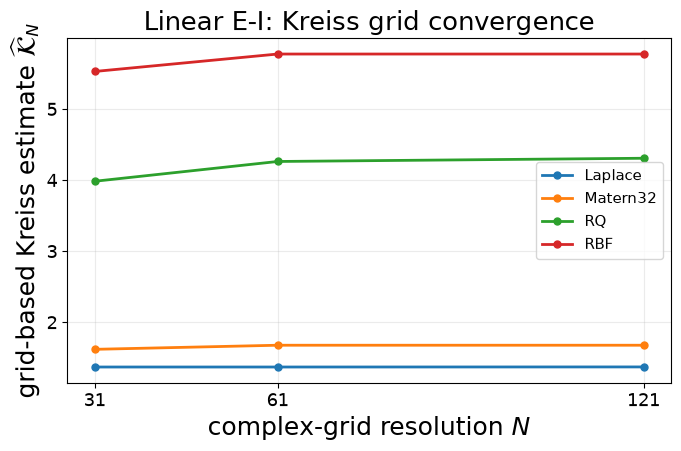

Saved: EI_kernel_koopman_results/EI_kreiss_grid_convergence.pdf


In [37]:
# ============================================================
# Kreiss grid-convergence figure
# ============================================================

fig, ax = plt.subplots(
    figsize=(7.0, 4.7)
)

for kind in KERNELS:

    sub = (
        kreiss_conv[
            kreiss_conv["kernel"] == kind
        ]
        .sort_values("grid_n")
    )

    ax.plot(
        sub["grid_n"],
        sub["kreiss_hat"],
        marker="o",
        linewidth=2.0,
        markersize=5,
        label=kind,
    )


ax.set_xlabel(
    "complex-grid resolution $N$"
)

ax.set_ylabel(
    r"grid-based Kreiss estimate "
    r"$\widehat{\mathcal{K}}_N$"
)

ax.set_title(
    f"{SYSTEM_NAME}: Kreiss grid convergence"
)

ax.set_xticks(
    GRID_SIZES
)

ax.grid(
    alpha=0.25
)

ax.legend(
    frameon=True
)

plt.tight_layout()

figure_path = os.path.join(
    OUTDIR,
    f"{FILE_PREFIX}_kreiss_grid_convergence.pdf",
)

plt.savefig(
    figure_path,
    dpi=500,
    bbox_inches="tight",
)

plt.show()

print(
    "Saved:",
    figure_path,
)

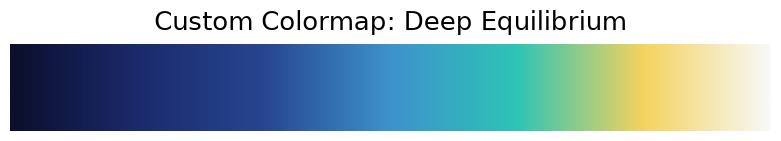

In [38]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# -------------------------------------------------
# My custom gradient: "Deep Equilibrium"
# -------------------------------------------------
deep_equilibrium_colors = [
    #"#26619C",  # lapis lazuli 
    #"#66023C",  # tyrian purple
    "#0b0f2b",  # midnight navy
    "#1b2a6b",  # deep indigo
    "#274690",  # royal blue
    "#3e92cc",  # soft blue
    "#2ec4b6",  # teal
    "#f4d35e",  # warm gold
    "#f8f9fa"   # ivory highlight
]

deep_equilibrium = LinearSegmentedColormap.from_list(
    "deep_equilibrium",
    deep_equilibrium_colors,
    N=256
)

# -------------------------------------------------
# Demo: show gradient
# -------------------------------------------------
gradient = np.linspace(0, 1, 512).reshape(1, -1)

plt.figure(figsize=(8, 1.6))
plt.imshow(gradient, aspect="auto", cmap=deep_equilibrium)
plt.axis("off")
plt.title("Custom Colormap: Deep Equilibrium", pad=10)
plt.tight_layout()
plt.show()

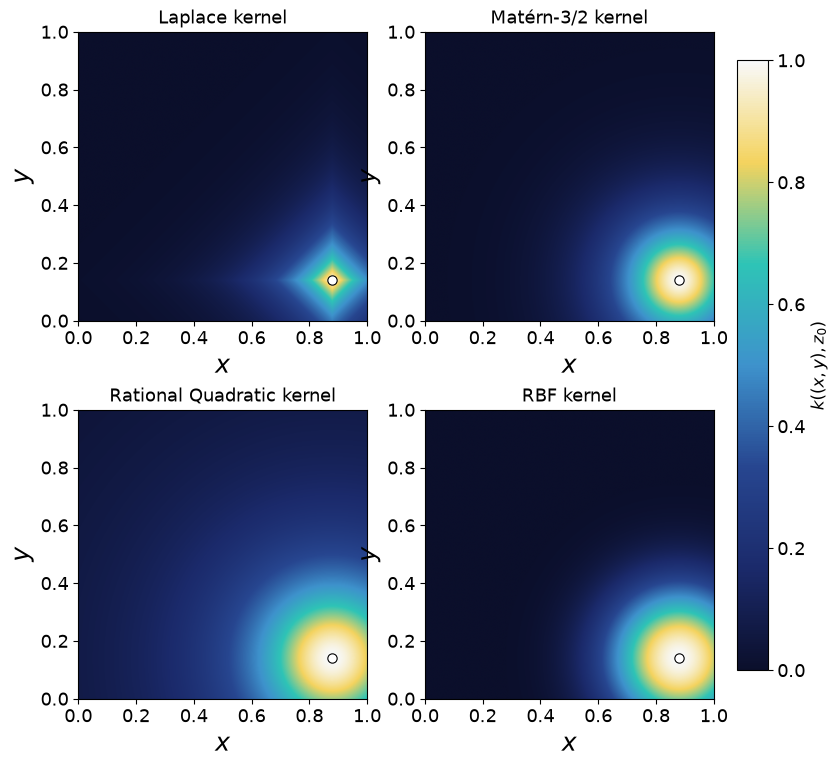

In [39]:
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Grid on [0,1]^2
# ------------------------------------------------------------
n = 500
x = np.linspace(0, 1, n)
y = np.linspace(0, 1, n)
X, Y = np.meshgrid(x, y)

# Anchor point chosen near the boundary
x0, y0 = 0.88, 0.14

# Kernel parameters
sigma = 0.18
alpha = 1.0   # shape parameter for Rational Quadratic

# ------------------------------------------------------------
# Kernel sections k((x,y), z0)
# ------------------------------------------------------------
def rbf_section(X, Y, x0, y0, sigma):
    d2 = (X - x0)**2 + (Y - y0)**2
    return np.exp(-d2 / (2 * sigma**2))

def laplace_section(X, Y, x0, y0, sigma):
    d1 = np.abs(X - x0) + np.abs(Y - y0)
    return np.exp(-d1 / sigma)

def matern32_section(X, Y, x0, y0, sigma):
    r = np.sqrt((X - x0)**2 + (Y - y0)**2)
    z = np.sqrt(3.0) * r / sigma
    return (1.0 + z) * np.exp(-z)

def rq_section(X, Y, x0, y0, sigma, alpha=1.0):
    d2 = (X - x0)**2 + (Y - y0)**2
    return (1.0 + d2 / (2.0 * alpha * sigma**2))**(-alpha)

Z_rbf = rbf_section(X, Y, x0, y0, sigma)
Z_lap = laplace_section(X, Y, x0, y0, sigma)
Z_mat = matern32_section(X, Y, x0, y0, sigma)
Z_rq  = rq_section(X, Y, x0, y0, sigma, alpha=alpha)

# Common color scale for comparison
vmin, vmax = 0.0, 1.0

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------
plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["ps.fonttype"] = 42

fig, axes = plt.subplots(2, 2, figsize=(10, 9))

panels = [
    (Z_lap, "Laplace kernel"),
    (Z_mat, "Matérn-3/2 kernel"),
    (Z_rq,  "Rational Quadratic kernel"),
    (Z_rbf, "RBF kernel"),
]

for ax, (Z, title) in zip(axes.ravel(), panels):
    im = ax.imshow(
        Z,
        extent=[0, 1, 0, 1],
        origin="lower",
        vmin=vmin,
        vmax=vmax,
        aspect="equal",
        cmap=deep_equilibrium,   # replace if needed by a standard cmap like "viridis"
    )
    ax.scatter([x0], [y0], s=45, c="white", edgecolors="black", linewidths=0.8)
    ax.set_title(title, fontsize=13)
    ax.set_xlabel(r"$x$")
    ax.set_ylabel(r"$y$")

cbar = fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.88, pad=0.03)
cbar.set_label(r"$k((x,y),z_0)$", fontsize=12)

#fig.suptitle(
#    rf"Representative kernel sections on $[0,1]^2$ with anchor $z_0=({x0:.2f},{y0:.2f})$",
#    fontsize=16,
#    y=0.95
#)

fig.savefig("kernel_geometry_gallery.pdf", bbox_inches="tight", dpi=1000)
fig.savefig("kernel_geometry_gallery.png", dpi=1000, bbox_inches="tight")
plt.show()

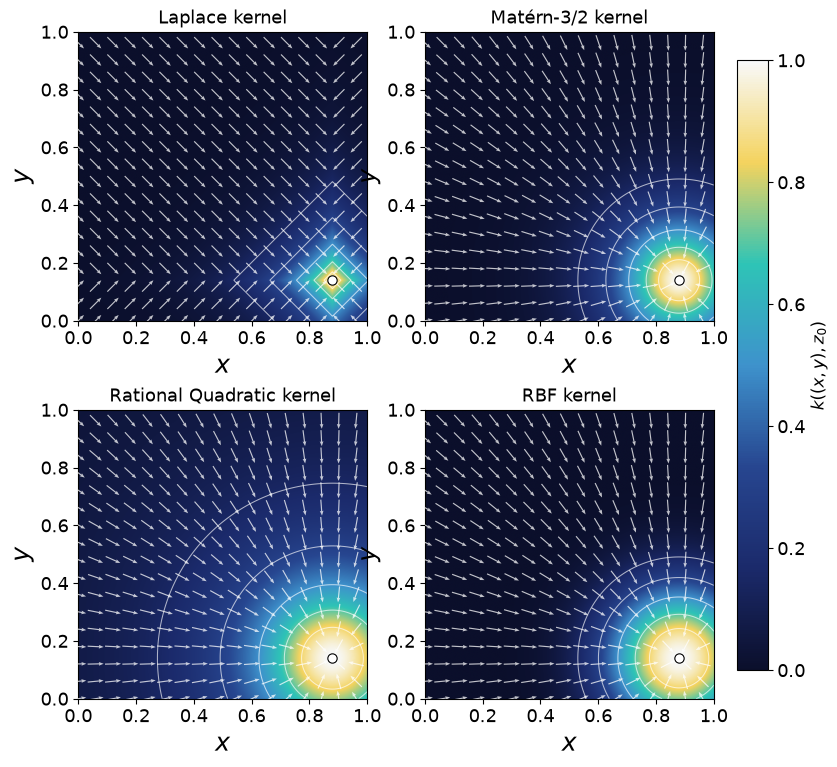

In [40]:
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Grid on [0,1]^2
# ------------------------------------------------------------
n = 500
x = np.linspace(0, 1, n)
y = np.linspace(0, 1, n)
X, Y = np.meshgrid(x, y)

# Anchor point chosen near the boundary
x0, y0 = 0.88, 0.14

# Kernel parameters
sigma = 0.18
alpha = 1.0   # shape parameter for Rational Quadratic

# ------------------------------------------------------------
# Kernel sections k((x,y), z0)
# ------------------------------------------------------------
def rbf_section(X, Y, x0, y0, sigma):
    d2 = (X - x0)**2 + (Y - y0)**2
    return np.exp(-d2 / (2 * sigma**2))

def laplace_section(X, Y, x0, y0, sigma):
    d1 = np.abs(X - x0) + np.abs(Y - y0)
    return np.exp(-d1 / sigma)

def matern32_section(X, Y, x0, y0, sigma):
    r = np.sqrt((X - x0)**2 + (Y - y0)**2)
    z = np.sqrt(3.0) * r / sigma
    return (1.0 + z) * np.exp(-z)

def rq_section(X, Y, x0, y0, sigma, alpha=1.0):
    d2 = (X - x0)**2 + (Y - y0)**2
    return (1.0 + d2 / (2.0 * alpha * sigma**2))**(-alpha)

Z_rbf = rbf_section(X, Y, x0, y0, sigma)
Z_lap = laplace_section(X, Y, x0, y0, sigma)
Z_mat = matern32_section(X, Y, x0, y0, sigma)
Z_rq  = rq_section(X, Y, x0, y0, sigma, alpha=alpha)

# Common color scale for comparison
vmin, vmax = 0.0, 1.0

# ------------------------------------------------------------
# Helper: compute normalized gradient field for quiver arrows
# ------------------------------------------------------------
def normalized_gradient(Z, x, y, stride=30, eps=1e-12):
    """
    Returns downsampled grid and normalized gradient vectors.
    Arrows point in the direction of steepest ascent of Z.
    """
    # np.gradient: first axis = y, second axis = x
    dZ_dy, dZ_dx = np.gradient(Z, y, x)

    # Downsample for quiver
    Xq = X[::stride, ::stride]
    Yq = Y[::stride, ::stride]
    Uq = dZ_dx[::stride, ::stride]
    Vq = dZ_dy[::stride, ::stride]

    mag = np.sqrt(Uq**2 + Vq**2)
    Uq = Uq / (mag + eps)
    Vq = Vq / (mag + eps)

    return Xq, Yq, Uq, Vq, mag

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------
plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["ps.fonttype"] = 42

fig, axes = plt.subplots(2, 2, figsize=(10, 9))

panels = [
    (Z_lap, "Laplace kernel"),
    (Z_mat, "Matérn-3/2 kernel"),
    (Z_rq,  "Rational Quadratic kernel"),
    (Z_rbf, "RBF kernel"),
]

# Use your custom colormap if defined; otherwise fallback safely
try:
    cmap_to_use = deep_equilibrium
except NameError:
    cmap_to_use = "viridis"

for ax, (Z, title) in zip(axes.ravel(), panels):
    im = ax.imshow(
        Z,
        extent=[0, 1, 0, 1],
        origin="lower",
        vmin=vmin,
        vmax=vmax,
        aspect="equal",
        cmap=cmap_to_use,
    )

    # Anchor point
    ax.scatter([x0], [y0], s=45, c="white", edgecolors="black", linewidths=0.8, zorder=5)

    # Contours to emphasize level-set geometry
    contour_levels = [0.15, 0.30, 0.50, 0.70, 0.85]
    ax.contour(
        X, Y, Z,
        levels=contour_levels,
        colors="white",
        linewidths=0.75,
        alpha=0.65
    )

    # Directional vectors from gradient field
    Xq, Yq, Uq, Vq, mag = normalized_gradient(Z, x, y, stride=30)

    ax.quiver(
        Xq, Yq, Uq, Vq,
        color="white",
        alpha=0.75,
        pivot="mid",
        scale=18,          # larger -> shorter arrows
        width=0.004,
        headwidth=3.2,
        headlength=4.2,
        headaxislength=3.8,
        zorder=4
    )

    ax.set_title(title, fontsize=13)
    ax.set_xlabel(r"$x$")
    ax.set_ylabel(r"$y$")

cbar = fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.88, pad=0.03)
cbar.set_label(r"$k((x,y),z_0)$", fontsize=12)

fig.savefig("kernel_geometry_gallery_with_vectors.pdf", bbox_inches="tight", dpi=1000)
fig.savefig("kernel_geometry_gallery_with_vectors.png", dpi=1000, bbox_inches="tight")
plt.show()

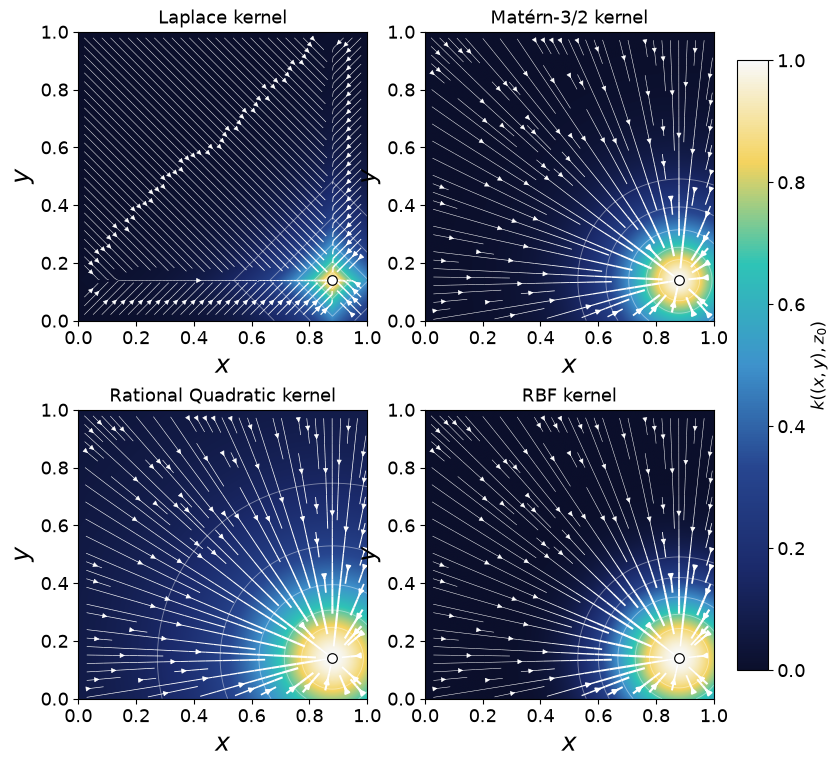

In [41]:
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Grid on [0,1]^2
# ------------------------------------------------------------
n = 500

x = np.linspace(0, 1, n)
y = np.linspace(0, 1, n)

X, Y = np.meshgrid(x, y)

# Anchor
x0, y0 = 0.88, 0.14

# Kernel parameters
sigma = 0.18
alpha = 1.0


# ------------------------------------------------------------
# Kernel sections
# ------------------------------------------------------------
def rbf_section(X, Y, x0, y0, sigma):

    d2 = (X - x0)**2 + (Y - y0)**2

    return np.exp(
        -d2 / (2.0 * sigma**2)
    )


def laplace_section(X, Y, x0, y0, sigma):

    d1 = (
        np.abs(X - x0)
        +
        np.abs(Y - y0)
    )

    return np.exp(
        -d1 / sigma
    )


def matern32_section(X, Y, x0, y0, sigma):

    r = np.sqrt(
        (X - x0)**2
        +
        (Y - y0)**2
    )

    q = np.sqrt(3.0) * r / sigma

    return (
        (1.0 + q)
        *
        np.exp(-q)
    )


def rq_section(
    X, Y,
    x0, y0,
    sigma,
    alpha=1.0
):

    d2 = (
        (X - x0)**2
        +
        (Y - y0)**2
    )

    return (
        1.0
        +
        d2 /
        (2.0 * alpha * sigma**2)
    )**(-alpha)


Z_lap = laplace_section(
    X, Y, x0, y0, sigma
)

Z_mat = matern32_section(
    X, Y, x0, y0, sigma
)

Z_rq = rq_section(
    X, Y, x0, y0,
    sigma,
    alpha=alpha
)

Z_rbf = rbf_section(
    X, Y, x0, y0, sigma
)


# ------------------------------------------------------------
# Streamline field
# ------------------------------------------------------------
def kernel_stream_field(Z, x, y, eps=1e-12):

    # Gradient:
    # axis 0 corresponds to y
    # axis 1 corresponds to x
    dZ_dy, dZ_dx = np.gradient(
        Z,
        y,
        x
    )

    magnitude = np.sqrt(
        dZ_dx**2
        +
        dZ_dy**2
    )

    # Normalize direction.
    # Streamline geometry then represents direction
    # independently of gradient magnitude.
    U = dZ_dx / (magnitude + eps)
    V = dZ_dy / (magnitude + eps)

    # Relative magnitude used only for line thickness
    mmax = np.nanmax(magnitude)

    if mmax > 0:
        magnitude_rel = magnitude / mmax
    else:
        magnitude_rel = magnitude

    return U, V, magnitude_rel


# ------------------------------------------------------------
# Plot settings
# ------------------------------------------------------------
plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["ps.fonttype"] = 42

fig, axes = plt.subplots(
    2, 2,
    figsize=(10, 9)
)

panels = [
    (Z_lap, "Laplace kernel"),
    (Z_mat, "Matérn-3/2 kernel"),
    (Z_rq,  "Rational Quadratic kernel"),
    (Z_rbf, "RBF kernel"),
]


# Use your existing custom map if available
try:
    cmap_to_use = deep_equilibrium
except NameError:
    cmap_to_use = "viridis"


# ------------------------------------------------------------
# Draw panels
# ------------------------------------------------------------
for ax, (Z, title) in zip(
    axes.ravel(),
    panels
):

    # --------------------------------------------------------
    # Kernel field
    # --------------------------------------------------------
    im = ax.imshow(
        Z,
        extent=[0, 1, 0, 1],
        origin="lower",
        vmin=0.0,
        vmax=1.0,
        aspect="equal",
        cmap=cmap_to_use,
        interpolation="bilinear"
    )

    # --------------------------------------------------------
    # Level sets
    # --------------------------------------------------------
    levels = [
        0.15,
        0.30,
        0.50,
        0.70,
        0.85
    ]

    ax.contour(
        X,
        Y,
        Z,
        levels=levels,
        colors="white",
        linewidths=0.65,
        alpha=0.42
    )

    # --------------------------------------------------------
    # Kernel-gradient stream field
    # --------------------------------------------------------
    U, V, Mrel = kernel_stream_field(
        Z,
        x,
        y
    )

    # Thickness carries gradient magnitude
    linewidth = (
        0.35
        +
        1.25 * Mrel
    )

    ax.streamplot(
        x,
        y,
        U,
        V,

        density=1.15,

        color="white",

        linewidth=linewidth,

        arrowsize=0.75,

        arrowstyle="-|>",

        minlength=0.08,

        maxlength=3.0,

        integration_direction="forward",

        zorder=3
    )

    # --------------------------------------------------------
    # Anchor
    # --------------------------------------------------------
    ax.scatter(
        [x0],
        [y0],
        s=48,
        c="white",
        edgecolors="black",
        linewidths=0.85,
        zorder=6
    )

    # --------------------------------------------------------
    # Labels
    # --------------------------------------------------------
    ax.set_title(
        title,
        fontsize=13
    )

    ax.set_xlabel(
        r"$x$"
    )

    ax.set_ylabel(
        r"$y$"
    )

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)


# ------------------------------------------------------------
# Shared colorbar
# ------------------------------------------------------------
cbar = fig.colorbar(
    im,
    ax=axes.ravel().tolist(),
    shrink=0.88,
    pad=0.03
)

cbar.set_label(
    r"$k((x,y),z_0)$",
    fontsize=12
)


# ------------------------------------------------------------
# Save
# ------------------------------------------------------------
fig.savefig(
    "kernel_geometry_streamlines.pdf",
    bbox_inches="tight",
    dpi=1000
)

fig.savefig(
    "kernel_geometry_streamlines.png",
    dpi=1000,
    bbox_inches="tight"
)

plt.show()

Common maximum gradient magnitude: 7.83403215771848


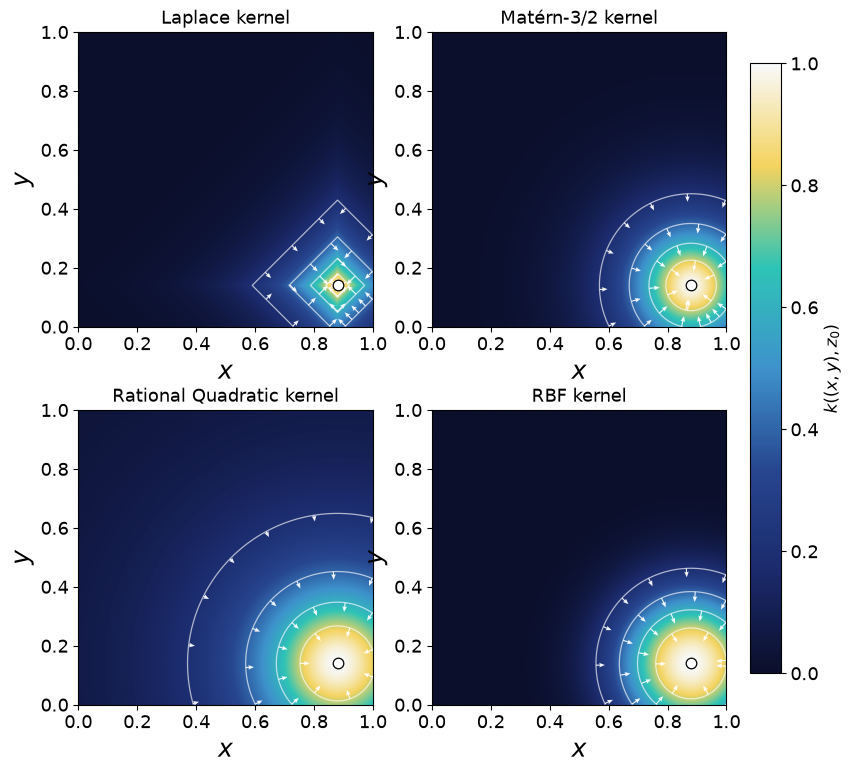

In [42]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 1. Grid on [0,1]^2
# ============================================================

n = 500

x = np.linspace(0.0, 1.0, n)
y = np.linspace(0.0, 1.0, n)

X, Y = np.meshgrid(x, y)

# Anchor point
x0, y0 = 0.88, 0.14

# Kernel parameters
sigma = 0.18
alpha = 1.0


# ============================================================
# 2. Kernel sections
# ============================================================

def rbf_section(X, Y, x0, y0, sigma):

    d2 = (X - x0)**2 + (Y - y0)**2

    return np.exp(
        -d2 / (2.0 * sigma**2)
    )


def laplace_section(X, Y, x0, y0, sigma):

    d1 = (
        np.abs(X - x0)
        +
        np.abs(Y - y0)
    )

    return np.exp(
        -d1 / sigma
    )


def matern32_section(X, Y, x0, y0, sigma):

    r = np.sqrt(
        (X - x0)**2
        +
        (Y - y0)**2
    )

    q = np.sqrt(3.0) * r / sigma

    return (
        (1.0 + q)
        *
        np.exp(-q)
    )


def rq_section(
    X, Y,
    x0, y0,
    sigma,
    alpha=1.0
):

    d2 = (
        (X - x0)**2
        +
        (Y - y0)**2
    )

    base = (
        1.0
        +
        d2 / (2.0 * alpha * sigma**2)
    )

    return base**(-alpha)


# ============================================================
# 3. Analytic kernel gradients
#
#    ∇k gives the direction of steepest increase
#    in kernel similarity.
# ============================================================

def grad_rbf(X, Y, x0, y0, sigma):

    dx = X - x0
    dy = Y - y0

    Z = rbf_section(
        X, Y, x0, y0, sigma
    )

    gx = -(dx / sigma**2) * Z
    gy = -(dy / sigma**2) * Z

    return gx, gy


def grad_laplace(X, Y, x0, y0, sigma):

    dx = X - x0
    dy = Y - y0

    Z = laplace_section(
        X, Y, x0, y0, sigma
    )

    gx = (
        -(np.sign(dx) / sigma)
        * Z
    )

    gy = (
        -(np.sign(dy) / sigma)
        * Z
    )

    # Laplace section is not differentiable exactly
    # along x=x0 or y=y0.
    gx[np.abs(dx) < 1e-12] = 0.0
    gy[np.abs(dy) < 1e-12] = 0.0

    return gx, gy


def grad_matern32(
    X, Y,
    x0, y0,
    sigma
):

    dx = X - x0
    dy = Y - y0

    r = np.sqrt(
        dx**2 + dy**2
    )

    q = (
        np.sqrt(3.0)
        * r / sigma
    )

    # d/dr [(1+q)e^{-q}]
    # = -(3r/sigma^2)e^{-q}
    #
    # Multiplying by (dx/r,dy/r)
    # gives:
    factor = (
        -(3.0 / sigma**2)
        * np.exp(-q)
    )

    gx = factor * dx
    gy = factor * dy

    gx[r < 1e-14] = 0.0
    gy[r < 1e-14] = 0.0

    return gx, gy


def grad_rq(
    X, Y,
    x0, y0,
    sigma,
    alpha=1.0
):

    dx = X - x0
    dy = Y - y0

    d2 = (
        dx**2
        +
        dy**2
    )

    base = (
        1.0
        +
        d2 /
        (2.0 * alpha * sigma**2)
    )

    gx = (
        -(dx / sigma**2)
        *
        base**(-alpha - 1.0)
    )

    gy = (
        -(dy / sigma**2)
        *
        base**(-alpha - 1.0)
    )

    return gx, gy


# ============================================================
# 4. Evaluate kernel sections
# ============================================================

Z_lap = laplace_section(
    X, Y, x0, y0, sigma
)

Z_mat = matern32_section(
    X, Y, x0, y0, sigma
)

Z_rq = rq_section(
    X, Y, x0, y0,
    sigma,
    alpha=alpha
)

Z_rbf = rbf_section(
    X, Y, x0, y0, sigma
)


# ============================================================
# 5. Evaluate gradient fields
# ============================================================

G_lap = grad_laplace(
    X, Y, x0, y0, sigma
)

G_mat = grad_matern32(
    X, Y, x0, y0, sigma
)

G_rq = grad_rq(
    X, Y, x0, y0,
    sigma,
    alpha=alpha
)

G_rbf = grad_rbf(
    X, Y, x0, y0, sigma
)


# ============================================================
# 6. Bilinear interpolation helper
#
#    Used to evaluate ∇k at the contour vertices.
# ============================================================

def interp_bilinear(
    F,
    xgrid,
    ygrid,
    xp,
    yp
):

    xp = np.asarray(xp)
    yp = np.asarray(yp)

    nx = len(xgrid)
    ny = len(ygrid)

    ix = np.clip(
        np.searchsorted(xgrid, xp) - 1,
        0,
        nx - 2
    )

    iy = np.clip(
        np.searchsorted(ygrid, yp) - 1,
        0,
        ny - 2
    )

    x1 = xgrid[ix]
    x2 = xgrid[ix + 1]

    y1 = ygrid[iy]
    y2 = ygrid[iy + 1]

    Q11 = F[iy, ix]
    Q21 = F[iy, ix + 1]
    Q12 = F[iy + 1, ix]
    Q22 = F[iy + 1, ix + 1]

    wx = (
        (xp - x1)
        /
        (x2 - x1 + 1e-15)
    )

    wy = (
        (yp - y1)
        /
        (y2 - y1 + 1e-15)
    )

    value = (
        (1.0 - wx) * (1.0 - wy) * Q11
        +
        wx * (1.0 - wy) * Q21
        +
        (1.0 - wx) * wy * Q12
        +
        wx * wy * Q22
    )

    return value


# ============================================================
# 7. Common gradient normalization
#
#    IMPORTANT:
#    One common maximum is used across all kernels.
#    Therefore arrow lengths retain cross-kernel meaning.
# ============================================================

all_gradient_magnitudes = []

for Gx, Gy in [
    G_lap,
    G_mat,
    G_rq,
    G_rbf
]:

    Gmag = np.sqrt(
        Gx**2 + Gy**2
    )

    all_gradient_magnitudes.append(
        Gmag
    )

GLOBAL_GMAX = max(
    np.nanmax(G)
    for G in all_gradient_magnitudes
)

print(
    "Common maximum gradient magnitude:",
    GLOBAL_GMAX
)


# ============================================================
# 8. Contour-normal arrow helper
#
#    Compatible with current Matplotlib:
#    uses QuadContourSet.allsegs
# ============================================================

def add_contour_normals(
    ax,
    X, Y, Z,
    Gx, Gy,
    levels,
    xgrid,
    ygrid,
    global_gmax,
    n_arrows_per_segment=7,
    arrow_min=0.010,
    arrow_max=0.050,
    contour_color="white",
    arrow_color="white",
    contour_lw=0.9,
    contour_alpha=0.65,
    arrow_alpha=0.95,
):

    # --------------------------------------------------------
    # Draw level sets
    # --------------------------------------------------------
    cs = ax.contour(
        X,
        Y,
        Z,
        levels=levels,
        colors=contour_color,
        linewidths=contour_lw,
        alpha=contour_alpha,
        zorder=3
    )

    # --------------------------------------------------------
    # Current Matplotlib-compatible iteration
    #
    # cs.allsegs[level_index]
    # gives a list of contour segments.
    #
    # Each segment is an N x 2 array:
    # [[x1,y1], [x2,y2], ...]
    # --------------------------------------------------------
    for segments_at_level in cs.allsegs:

        for verts in segments_at_level:

            if verts is None:
                continue

            if len(verts) < 15:
                continue

            # ------------------------------------------------
            # Sample positions approximately uniformly
            # along the contour segment.
            # ------------------------------------------------
            n_use = min(
                n_arrows_per_segment,
                max(
                    2,
                    len(verts) // 18
                )
            )

            indices = np.linspace(
                2,
                len(verts) - 3,
                n_use,
                dtype=int
            )

            points = verts[indices]

            px = points[:, 0]
            py = points[:, 1]

            # ------------------------------------------------
            # Keep visible points only
            # ------------------------------------------------
            inside = (
                (px >= xgrid[0])
                &
                (px <= xgrid[-1])
                &
                (py >= ygrid[0])
                &
                (py <= ygrid[-1])
            )

            px = px[inside]
            py = py[inside]

            if len(px) == 0:
                continue

            # ------------------------------------------------
            # Evaluate gradient on contour
            # ------------------------------------------------
            gx = interp_bilinear(
                Gx,
                xgrid,
                ygrid,
                px,
                py
            )

            gy = interp_bilinear(
                Gy,
                xgrid,
                ygrid,
                px,
                py
            )

            gm = np.sqrt(
                gx**2
                +
                gy**2
            )

            valid = (
                np.isfinite(gm)
                &
                (gm > 1e-12)
            )

            if not np.any(valid):
                continue

            px = px[valid]
            py = py[valid]

            gx = gx[valid]
            gy = gy[valid]
            gm = gm[valid]

            # ------------------------------------------------
            # Unit gradient direction
            # ------------------------------------------------
            ux = gx / gm
            uy = gy / gm

            # ------------------------------------------------
            # Relative gradient strength
            #
            # Common normalization across kernels.
            # ------------------------------------------------
            strength = np.clip(
                gm / global_gmax,
                0.0,
                1.0
            )

            # Slight square-root compression prevents
            # weaker gradients from disappearing entirely.
            strength_display = np.sqrt(
                strength
            )

            arrow_length = (
                arrow_min
                +
                (arrow_max - arrow_min)
                * strength_display
            )

            U = arrow_length * ux
            V = arrow_length * uy

            # ------------------------------------------------
            # Draw one meaningful direction only:
            #
            # +∇k points toward increasing kernel similarity.
            # ------------------------------------------------
            ax.quiver(
                px,
                py,
                U,
                V,

                angles="xy",
                scale_units="xy",
                scale=1.0,

                pivot="tail",

                color=arrow_color,

                width=0.0037,

                headwidth=4.2,
                headlength=5.2,
                headaxislength=4.5,

                alpha=arrow_alpha,

                zorder=5
            )

    return cs


# ============================================================
# 9. Plot settings
# ============================================================

plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["ps.fonttype"] = 42

# No font family is changed.

fig, axes = plt.subplots(
    2,
    2,
    figsize=(10.2, 9.0)
)


# ------------------------------------------------------------
# Use your existing custom colormap if available.
# Otherwise use viridis.
# ------------------------------------------------------------

try:
    cmap_use = deep_equilibrium
except NameError:
    cmap_use = "viridis"


panels = [
    (
        Z_lap,
        G_lap,
        "Laplace kernel"
    ),
    (
        Z_mat,
        G_mat,
        "Matérn-3/2 kernel"
    ),
    (
        Z_rq,
        G_rq,
        "Rational Quadratic kernel"
    ),
    (
        Z_rbf,
        G_rbf,
        "RBF kernel"
    ),
]


# Four clean similarity levels
levels = [
    0.20,
    0.40,
    0.60,
    0.80
]

vmin = 0.0
vmax = 1.0


# ============================================================
# 10. Draw panels
# ============================================================

for ax, panel in zip(
    axes.ravel(),
    panels
):

    Z, gradient, title = panel

    Gx, Gy = gradient

    # --------------------------------------------------------
    # Kernel magnitude
    # --------------------------------------------------------
    im = ax.imshow(
        Z,

        extent=[
            0.0,
            1.0,
            0.0,
            1.0
        ],

        origin="lower",

        vmin=vmin,
        vmax=vmax,

        cmap=cmap_use,

        aspect="equal",

        interpolation="bilinear",

        zorder=1
    )

    # --------------------------------------------------------
    # Contours + sparse gradient normals
    # --------------------------------------------------------
    add_contour_normals(
        ax,

        X,
        Y,
        Z,

        Gx,
        Gy,

        levels,

        x,
        y,

        global_gmax=GLOBAL_GMAX,

        n_arrows_per_segment=7,

        arrow_min=0.010,
        arrow_max=0.050,

        contour_color="white",
        arrow_color="white",

        contour_lw=0.9,
        contour_alpha=0.65,

        arrow_alpha=0.95,
    )

    # --------------------------------------------------------
    # Anchor point
    # --------------------------------------------------------
    ax.scatter(
        [x0],
        [y0],

        s=58,

        facecolor="white",
        edgecolor="black",

        linewidth=0.9,

        zorder=8
    )

    # --------------------------------------------------------
    # Labels
    # --------------------------------------------------------
    ax.set_title(
        title,
        fontsize=13
    )

    ax.set_xlabel(
        r"$x$"
    )

    ax.set_ylabel(
        r"$y$"
    )

    ax.set_xlim(
        0.0,
        1.0
    )

    ax.set_ylim(
        0.0,
        1.0
    )


# ============================================================
# 11. Shared colorbar
# ============================================================

cbar = fig.colorbar(
    im,

    ax=axes.ravel().tolist(),

    shrink=0.88,

    pad=0.03
)

cbar.set_label(
    r"$k((x,y),z_0)$",
    fontsize=12
)


# ============================================================
# 12. Optional figure title
# ============================================================

# fig.suptitle(
#     rf"Kernel geometry around $z_0=({x0:.2f},{y0:.2f})$",
#     fontsize=15,
#     y=0.97
# )


# ============================================================
# 13. Save
# ============================================================

fig.savefig(
    "kernel_geometry_gallery_normals.pdf",
    bbox_inches="tight",
    dpi=1000
)

fig.savefig(
    "kernel_geometry_gallery_normals.png",
    bbox_inches="tight",
    dpi=1000
)

plt.show()

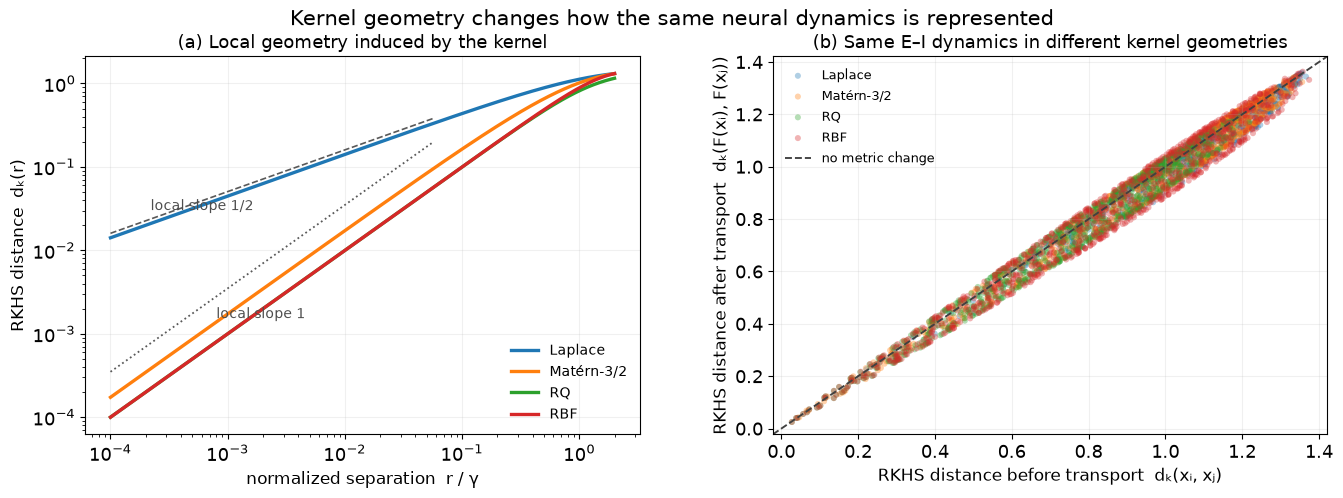

Saved:
teaser_kernel_geometry/kernel_geometry_transport_teaser.png
teaser_kernel_geometry/kernel_geometry_transport_teaser.pdf


In [43]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm
from pathlib import Path


# ============================================================
# Configuration
# ============================================================

SEED = 42
M = 80
DT = 0.05

OUTDIR = Path("teaser_kernel_geometry")
OUTDIR.mkdir(parents=True, exist_ok=True)

PNG_OUT = OUTDIR / "kernel_geometry_transport_teaser.png"
PDF_OUT = OUTDIR / "kernel_geometry_transport_teaser.pdf"

rng = np.random.default_rng(SEED)


# ============================================================
# Kernel definitions
# ============================================================

def pairwise_l2(X, Y=None):
    if Y is None:
        Y = X

    diff = X[:, None, :] - Y[None, :, :]
    return np.sqrt(np.sum(diff**2, axis=-1))


def pairwise_l1(X, Y=None):
    if Y is None:
        Y = X

    diff = X[:, None, :] - Y[None, :, :]
    return np.sum(np.abs(diff), axis=-1)


def kernel_matrix(X, Y, kind, gamma):
    if kind == "Laplace":
        r = pairwise_l1(X, Y)
        return np.exp(-r / gamma)

    r = pairwise_l2(X, Y)

    if kind == "Matern32":
        q = np.sqrt(3.0) * r / gamma
        return (1.0 + q) * np.exp(-q)

    if kind == "RQ":
        return 1.0 / (1.0 + r**2 / (2.0 * gamma**2))

    if kind == "RBF":
        return np.exp(-r**2 / (2.0 * gamma**2))

    raise ValueError(f"Unknown kernel: {kind}")


def median_kernel_scale(X, kind):
    if kind == "Laplace":
        D = pairwise_l1(X)
    else:
        D = pairwise_l2(X)

    iu = np.triu_indices_from(D, k=1)
    vals = D[iu]
    vals = vals[vals > 0]

    return np.median(vals)


# ============================================================
# RKHS distance from a Gram matrix
#
# d_k(x_i,x_j)^2
# = k(x_i,x_i) + k(x_j,x_j) - 2 k(x_i,x_j)
# ============================================================

def rkhs_distance_matrix(K):
    diag = np.diag(K)

    D2 = (
        diag[:, None]
        + diag[None, :]
        - 2.0 * K
    )

    D2 = np.maximum(D2, 0.0)

    return np.sqrt(D2)


# ============================================================
# Stable E-I neural benchmark
# ============================================================

J = np.array([
    [0.8, -4.0],
    [1.0, -2.8]
])

F = expm(J * DT)

X = rng.uniform(-1.0, 1.0, size=(M, 2))
Y = X @ F.T


# ============================================================
# Plot appearance
#
# IMPORTANT:
# No font configuration is changed here.
# ============================================================

kernel_order = [
    "Laplace",
    "Matern32",
    "RQ",
    "RBF",
]

kernel_colors = {
    "Laplace": "#1f77b4",
    "Matern32": "#ff7f0e",
    "RQ": "#2ca02c",
    "RBF": "#d62728",
}


fig, (ax1, ax2) = plt.subplots(
    1,
    2,
    figsize=(13.8, 5.25),
    constrained_layout=False
)

plt.subplots_adjust(
    left=0.075,
    right=0.975,
    bottom=0.16,
    top=0.88,
    wspace=0.24
)


# ============================================================
# PANEL A
# Local RKHS geometry
# ============================================================

q = np.logspace(-4, np.log10(2.0), 700)

k_lap = np.exp(-q)

k_mat = (
    1.0 + np.sqrt(3.0) * q
) * np.exp(-np.sqrt(3.0) * q)

k_rq = 1.0 / (1.0 + q**2 / 2.0)

k_rbf = np.exp(-q**2 / 2.0)

local_kernels = {
    "Laplace": k_lap,
    "Matern32": k_mat,
    "RQ": k_rq,
    "RBF": k_rbf,
}

for kind in kernel_order:
    kval = local_kernels[kind]

    # For normalized kernels k(x,x)=1:
    # d_k^2 = 2(1-k)
    dk = np.sqrt(
        np.maximum(2.0 * (1.0 - kval), 1e-16)
    )

    label = {
        "Laplace": "Laplace",
        "Matern32": "Matérn-3/2",
        "RQ": "RQ",
        "RBF": "RBF",
    }[kind]

    ax1.loglog(
        q,
        dk,
        lw=2.4,
        color=kernel_colors[kind],
        label=label
    )


# local asymptotic guide curves
q_ref = np.logspace(-4, -1.25, 120)

# slope 1/2 guide
c_half = 0.16 / np.sqrt(1e-2)
ax1.loglog(
    q_ref,
    c_half * np.sqrt(q_ref),
    linestyle="--",
    linewidth=1.2,
    color="0.35"
)

ax1.text(
    2.2e-4,
    c_half * np.sqrt(2.2e-4) * 1.28,
    "local slope 1/2",
    fontsize=10,
    color="0.30"
)

# slope 1 guide
c_one = 0.035 / 1e-2
ax1.loglog(
    q_ref,
    c_one * q_ref,
    linestyle=":",
    linewidth=1.3,
    color="0.35"
)

ax1.text(
    8e-4,
    c_one * 8e-4 * 0.55,
    "local slope 1",
    fontsize=10,
    color="0.30"
)

ax1.set_xlabel("normalized separation  r / γ", fontsize=12)
ax1.set_ylabel("RKHS distance  dₖ(r)", fontsize=12)

ax1.set_title(
    "(a) Local geometry induced by the kernel",
    fontsize=13
)

ax1.grid(
    True,
    which="major",
    alpha=0.18,
    linewidth=0.8
)

ax1.legend(
    frameon=False,
    fontsize=10,
    loc="lower right"
)


# ============================================================
# PANEL B
# Same physical dynamics viewed through four RKHS geometries
# ============================================================

pair_i, pair_j = np.triu_indices(M, k=1)

# use the same subset of pairs for every kernel
N_SHOW = min(900, len(pair_i))

choice = rng.choice(
    len(pair_i),
    size=N_SHOW,
    replace=False
)

ii = pair_i[choice]
jj = pair_j[choice]


all_dx = []
all_dy = []

for kind in kernel_order:

    gamma = median_kernel_scale(X, kind)

    GX = kernel_matrix(
        X, X, kind, gamma
    )

    GY = kernel_matrix(
        Y, Y, kind, gamma
    )

    DX = rkhs_distance_matrix(GX)
    DY = rkhs_distance_matrix(GY)

    xvals = DX[ii, jj]
    yvals = DY[ii, jj]

    all_dx.append(xvals)
    all_dy.append(yvals)

    label = {
        "Laplace": "Laplace",
        "Matern32": "Matérn-3/2",
        "RQ": "RQ",
        "RBF": "RBF",
    }[kind]

    ax2.scatter(
        xvals,
        yvals,
        s=19,
        alpha=0.35,
        color=kernel_colors[kind],
        edgecolors="none",
        label=label
    )


all_dx = np.concatenate(all_dx)
all_dy = np.concatenate(all_dy)

lo = min(all_dx.min(), all_dy.min())
hi = max(all_dx.max(), all_dy.max())

pad = 0.035 * (hi - lo)

lo -= pad
hi += pad

ax2.plot(
    [lo, hi],
    [lo, hi],
    linestyle="--",
    linewidth=1.35,
    color="0.25",
    label="no metric change"
)

ax2.set_xlim(lo, hi)
ax2.set_ylim(lo, hi)

ax2.set_xlabel(
    "RKHS distance before transport  dₖ(xᵢ, xⱼ)",
    fontsize=12
)

ax2.set_ylabel(
    "RKHS distance after transport  dₖ(F(xᵢ), F(xⱼ))",
    fontsize=12
)

ax2.set_title(
    "(b) Same E–I dynamics in different kernel geometries",
    fontsize=13
)

ax2.grid(
    True,
    alpha=0.18,
    linewidth=0.8
)

ax2.legend(
    frameon=False,
    fontsize=9.5,
    loc="upper left"
)


# ============================================================
# Small common interpretation
# ============================================================

fig.suptitle(
    "Kernel geometry changes how the same neural dynamics is represented",
    fontsize=15,
    y=0.97
)


# ============================================================
# Save
# ============================================================

fig.savefig(
    PNG_OUT,
    dpi=450,
    bbox_inches="tight"
)

fig.savefig(
    PDF_OUT,
    bbox_inches="tight"
)

plt.show()

print("Saved:")
print(PNG_OUT)
print(PDF_OUT)

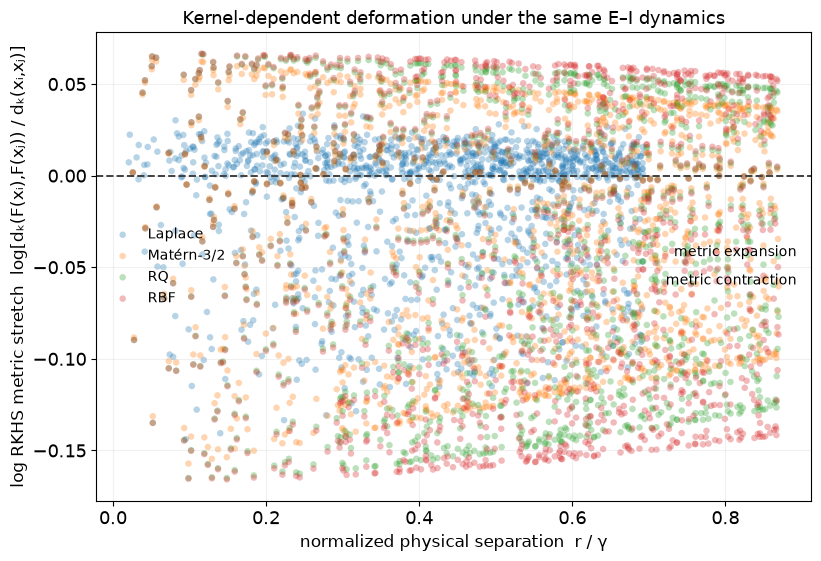

In [44]:
# ============================================================
# Improved transport visualization
#
# Plot the RELATIVE RKHS metric deformation rather than
# d_k(X) versus d_k(F(X)).
# ============================================================

fig, ax = plt.subplots(figsize=(8.4, 5.8))

pair_i, pair_j = np.triu_indices(M, k=1)

# Euclidean separation of the original states
R_phys = np.linalg.norm(
    X[pair_i] - X[pair_j],
    axis=1
)

# Focus especially on local-to-intermediate pairs.
# You can increase this quantile later.
local_cutoff = np.quantile(R_phys, 0.40)
keep = R_phys <= local_cutoff

ii = pair_i[keep]
jj = pair_j[keep]

rplot = R_phys[keep]


for kind in kernel_order:

    gamma = median_kernel_scale(X, kind)

    GX = kernel_matrix(
        X, X, kind, gamma
    )

    GY = kernel_matrix(
        Y, Y, kind, gamma
    )

    DX = rkhs_distance_matrix(GX)
    DY = rkhs_distance_matrix(GY)

    d_before = DX[ii, jj]
    d_after  = DY[ii, jj]

    valid = d_before > 1e-12

    # logarithmic finite metric stretch
    log_stretch = np.log(
        d_after[valid] / d_before[valid]
    )

    label = {
        "Laplace": "Laplace",
        "Matern32": "Matérn-3/2",
        "RQ": "RQ",
        "RBF": "RBF",
    }[kind]

    ax.scatter(
        rplot[valid] / gamma,
        log_stretch,
        s=22,
        alpha=0.32,
        color=kernel_colors[kind],
        edgecolors="none",
        label=label
    )


# Zero = no change in RKHS distance
ax.axhline(
    0.0,
    linestyle="--",
    linewidth=1.4,
    color="0.25"
)

ax.text(
    0.98,
    0.515,
    "metric expansion",
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    fontsize=10
)

ax.text(
    0.98,
    0.485,
    "metric contraction",
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=10
)

ax.set_xlabel(
    "normalized physical separation  r / γ",
    fontsize=12
)

ax.set_ylabel(
    "log RKHS metric stretch  log[dₖ(F(xᵢ),F(xⱼ)) / dₖ(xᵢ,xⱼ)]",
    fontsize=12
)

ax.set_title(
    "Kernel-dependent deformation under the same E–I dynamics",
    fontsize=13
)

ax.grid(
    True,
    alpha=0.18,
    linewidth=0.8
)

ax.legend(
    frameon=False,
    fontsize=10
)

plt.tight_layout()

plt.savefig(
    OUTDIR / "EI_kernel_metric_stretch.png",
    dpi=450,
    bbox_inches="tight"
)

plt.savefig(
    OUTDIR / "EI_kernel_metric_stretch.pdf",
    bbox_inches="tight"
)

plt.show()

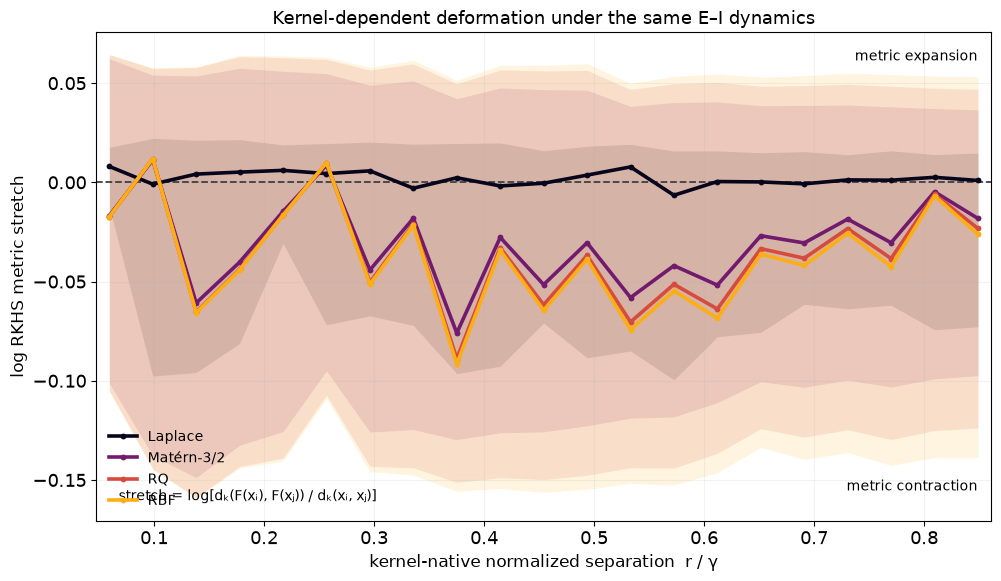

Saved:
teaser_kernel_geometry/EI_kernel_metric_stretch_viridis.png
teaser_kernel_geometry/EI_kernel_metric_stretch_viridis.pdf

Kernel scales:
Laplace    gamma = 1.225703
Matern32   gamma = 0.977276
RQ         gamma = 0.977276
RBF        gamma = 0.977276


In [45]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm
from pathlib import Path


# ============================================================
# Configuration
# ============================================================

SEED = 42
M = 80
DT = 0.05

OUTDIR = Path("teaser_kernel_geometry")
OUTDIR.mkdir(parents=True, exist_ok=True)

PNG_OUT = OUTDIR / "EI_kernel_metric_stretch_viridis.png"
PDF_OUT = OUTDIR / "EI_kernel_metric_stretch_viridis.pdf"

rng = np.random.default_rng(SEED)


# ============================================================
# Pairwise distances
# ============================================================

def pairwise_l2(X, Y=None):
    if Y is None:
        Y = X
    diff = X[:, None, :] - Y[None, :, :]
    return np.sqrt(np.sum(diff**2, axis=-1))


def pairwise_l1(X, Y=None):
    if Y is None:
        Y = X
    diff = X[:, None, :] - Y[None, :, :]
    return np.sum(np.abs(diff), axis=-1)


# ============================================================
# Kernel matrices
# ============================================================

def kernel_matrix(X, Y, kind, gamma):

    if kind == "Laplace":
        r = pairwise_l1(X, Y)
        return np.exp(-r / gamma)

    r = pairwise_l2(X, Y)

    if kind == "Matern32":
        q = np.sqrt(3.0) * r / gamma
        return (1.0 + q) * np.exp(-q)

    if kind == "RQ":
        return 1.0 / (1.0 + r**2 / (2.0 * gamma**2))

    if kind == "RBF":
        return np.exp(-r**2 / (2.0 * gamma**2))

    raise ValueError(f"Unknown kernel: {kind}")


def median_kernel_scale(X, kind):

    if kind == "Laplace":
        D = pairwise_l1(X)
    else:
        D = pairwise_l2(X)

    iu = np.triu_indices_from(D, k=1)

    vals = D[iu]
    vals = vals[vals > 0]

    return np.median(vals)


# ============================================================
# RKHS metric
# ============================================================

def rkhs_distance_matrix(K):

    diag = np.diag(K)

    D2 = (
        diag[:, None]
        + diag[None, :]
        - 2.0 * K
    )

    D2 = np.maximum(D2, 0.0)

    return np.sqrt(D2)


# ============================================================
# E-I dynamics
# ============================================================

J = np.array([
    [0.8, -4.0],
    [1.0, -2.8]
])

F = expm(J * DT)

X = rng.uniform(
    -1.0,
    1.0,
    size=(M, 2)
)

Y = X @ F.T


# ============================================================
# Kernel setup
# ============================================================

kernel_order = [
    "Laplace",
    "Matern32",
    "RQ",
    "RBF"
]

kernel_labels = {
    "Laplace": "Laplace",
    "Matern32": "Matérn-3/2",
    "RQ": "RQ",
    "RBF": "RBF"
}


# ============================================================
# Viridis palette
#
# No font settings are changed.
# ============================================================

cmap = plt.colormaps["inferno"]

kernel_colors = {
    "Laplace":   cmap(0.05),
    "Matern32":  cmap(0.32),
    "RQ":        cmap(0.58),
    "RBF":       cmap(0.82),
}


# ============================================================
# Binning helper
# ============================================================

def binned_statistics(x, y, bins):

    centers = 0.5 * (bins[:-1] + bins[1:])

    med = np.full(len(centers), np.nan)
    q10 = np.full(len(centers), np.nan)
    q90 = np.full(len(centers), np.nan)
    counts = np.zeros(len(centers), dtype=int)

    for b in range(len(centers)):

        if b == len(centers) - 1:
            mask = (x >= bins[b]) & (x <= bins[b + 1])
        else:
            mask = (x >= bins[b]) & (x < bins[b + 1])

        vals = y[mask]
        vals = vals[np.isfinite(vals)]

        counts[b] = len(vals)

        if len(vals) >= 5:
            med[b] = np.median(vals)
            q10[b] = np.quantile(vals, 0.10)
            q90[b] = np.quantile(vals, 0.90)

    return centers, med, q10, q90, counts


# ============================================================
# Collect deformation statistics
# ============================================================

pair_i, pair_j = np.triu_indices(M, k=1)

results = {}

for kind in kernel_order:

    gamma = median_kernel_scale(X, kind)

    GX = kernel_matrix(
        X, X,
        kind,
        gamma
    )

    GY = kernel_matrix(
        Y, Y,
        kind,
        gamma
    )

    DX = rkhs_distance_matrix(GX)
    DY = rkhs_distance_matrix(GY)

    d_before = DX[pair_i, pair_j]
    d_after  = DY[pair_i, pair_j]

    # --------------------------------------------------------
    # Kernel-native physical separation
    # --------------------------------------------------------

    if kind == "Laplace":

        physical_sep = np.sum(
            np.abs(
                X[pair_i] - X[pair_j]
            ),
            axis=1
        )

    else:

        physical_sep = np.linalg.norm(
            X[pair_i] - X[pair_j],
            axis=1
        )

    q = physical_sep / gamma

    valid = (
        (d_before > 1e-12)
        & np.isfinite(d_before)
        & np.isfinite(d_after)
        & np.isfinite(q)
    )

    q = q[valid]

    log_stretch = np.log(
        d_after[valid] /
        d_before[valid]
    )

    results[kind] = {
        "gamma": gamma,
        "q": q,
        "stretch": log_stretch,
    }


# ============================================================
# Use common local range
# ============================================================

# Focus on the local/intermediate geometry.
# 40th percentile of the pooled native separation.
all_q = np.concatenate(
    [results[k]["q"] for k in kernel_order]
)

q_max = np.quantile(all_q, 0.40)

NBINS = 22

bins = np.linspace(
    0.0,
    q_max,
    NBINS + 1
)


# ============================================================
# Plot
# ============================================================

fig, ax = plt.subplots(
    figsize=(10.2, 6)
)


for kind in kernel_order:

    q = results[kind]["q"]
    stretch = results[kind]["stretch"]

    local = q <= q_max

    q_local = q[local]
    s_local = stretch[local]

    centers, med, q10, q90, counts = binned_statistics(
        q_local,
        s_local,
        bins
    )

    valid_bin = (
        np.isfinite(med)
        & np.isfinite(q10)
        & np.isfinite(q90)
    )

    c = kernel_colors[kind]

    # --------------------------------------------------------
    # 10–90% envelope
    # --------------------------------------------------------

    ax.fill_between(
        centers[valid_bin],
        q10[valid_bin],
        q90[valid_bin],
        color=c,
        alpha=0.13,
        linewidth=0
    )

    # --------------------------------------------------------
    # Median
    # --------------------------------------------------------

    ax.plot(
        centers[valid_bin],
        med[valid_bin],
        color=c,
        linewidth=2.6,
        marker="o",
        markersize=4.2,
        markeredgewidth=0,
        label=kernel_labels[kind],
        zorder=4
    )


# ============================================================
# No-change line
# ============================================================

ax.axhline(
    0.0,
    linestyle="--",
    linewidth=1.3,
    color="0.25",
    zorder=2
)


# ============================================================
# Expansion / contraction labels
# ============================================================

ylim = ax.get_ylim()

ax.text(
    0.985,
    0.965,
    "metric expansion",
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=10
)

ax.text(
    0.985,
    0.055,
    "metric contraction",
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    fontsize=10
)


# ============================================================
# Labels
# ============================================================

ax.set_xlabel(
    "kernel-native normalized separation  r / γ",
    fontsize=12
)

ax.set_ylabel(
    "log RKHS metric stretch",
    fontsize=12
)

ax.set_title(
    "Kernel-dependent deformation under the same E–I dynamics",
    fontsize=13
)


# ============================================================
# Small mathematical definition
# ============================================================

ax.text(
    0.025,
    0.035,
    "stretch = log[dₖ(F(xᵢ), F(xⱼ)) / dₖ(xᵢ, xⱼ)]",
    transform=ax.transAxes,
    ha="left",
    va="bottom",
    fontsize=10
)


# ============================================================
# Cosmetics
# ============================================================

ax.grid(
    True,
    alpha=0.16,
    linewidth=0.8
)

ax.legend(
    frameon=False,
    fontsize=10,
    loc="lower left"
)

ax.margins(x=0.015)

plt.tight_layout()


# ============================================================
# Save
# ============================================================

fig.savefig(
    PNG_OUT,
    dpi=450,
    bbox_inches="tight"
)

fig.savefig(
    PDF_OUT,
    bbox_inches="tight"
)

plt.show()

print("Saved:")
print(PNG_OUT)
print(PDF_OUT)

print("\nKernel scales:")
for kind in kernel_order:
    print(
        f"{kind:10s} "
        f"gamma = {results[kind]['gamma']:.6f}"
    )

findfont: Failed to find font weight semibold, now using 700.
findfont: Failed to find font weight semibold, now using 700.
findfont: Failed to find font weight semibold, now using 700.
findfont: Failed to find font weight semibold, now using 700.


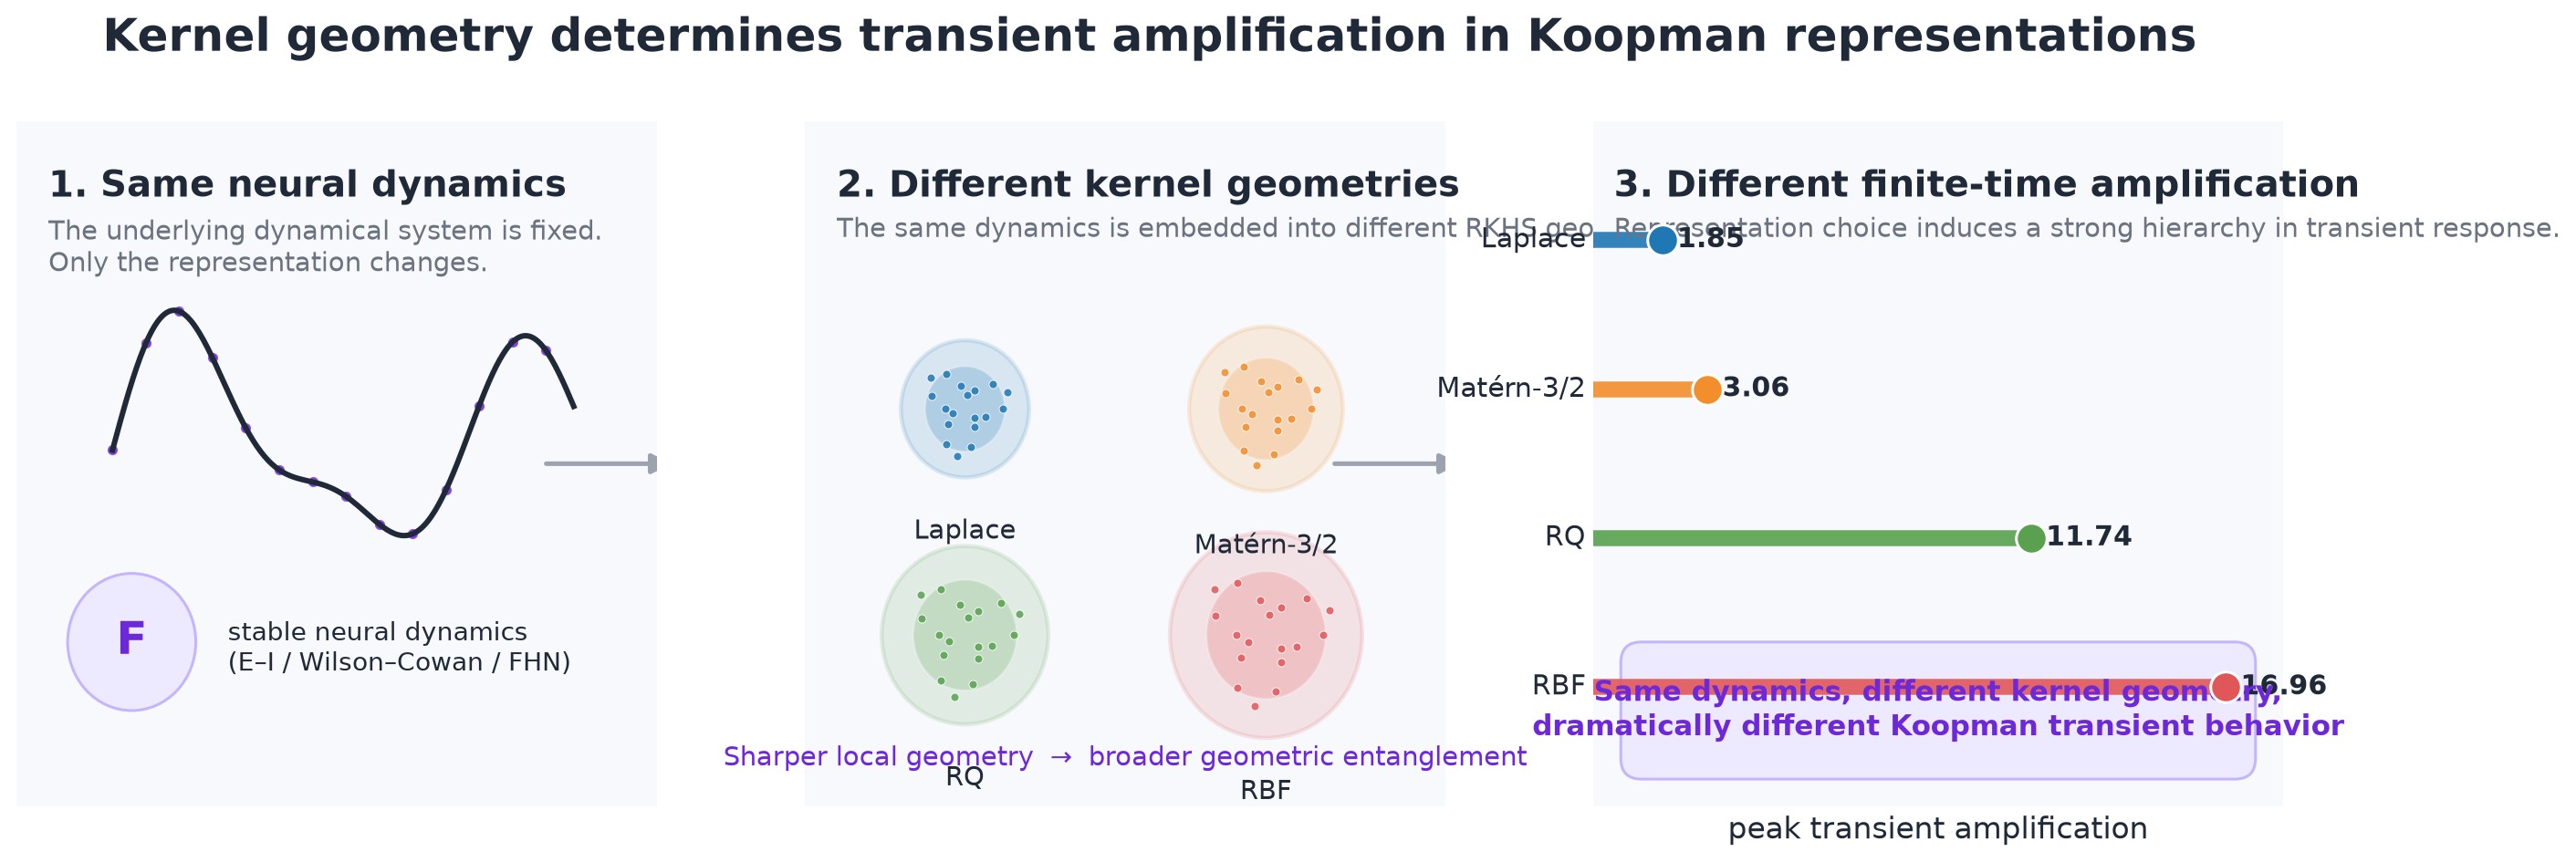

In [46]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Circle, FancyArrowPatch
from matplotlib.lines import Line2D

# -----------------------------
# Global style
# -----------------------------
plt.rcParams.update({
    "font.size": 12,
    "axes.titlesize": 16,
    "axes.labelsize": 13,
    "legend.fontsize": 11,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
})

# -----------------------------
# Colors
# -----------------------------
COLORS = {
    "laplace":  "#1f77b4",   # blue
    "matern":   "#f28e2b",   # orange
    "rq":       "#59a14f",   # green
    "rbf":      "#e15759",   # red
    "dark":     "#1f2937",
    "gray":     "#6b7280",
    "light":    "#f5f7fb",
    "soft":     "#e9eef7",
    "accent":   "#6d28d9",   # purple
}

# -----------------------------
# Example values (replace later if desired)
# E-I transient peaks from your experiment
# -----------------------------
kernel_names = ["Laplace", "Matérn-3/2", "RQ", "RBF"]
peak_vals = [1.85, 3.06, 11.74, 16.96]
peak_colors = [COLORS["laplace"], COLORS["matern"], COLORS["rq"], COLORS["rbf"]]

# -----------------------------
# Figure canvas
# -----------------------------
fig = plt.figure(figsize=(15, 5.8), dpi=180)
fig.suptitle(
    "Kernel geometry determines transient amplification in Koopman representations",
    fontsize=20,
    fontweight="semibold",
    y=0.98,
    color=COLORS["dark"]
)

# panel positions
ax1 = fig.add_axes([0.04, 0.15, 0.26, 0.72])
ax2 = fig.add_axes([0.36, 0.15, 0.26, 0.72])
ax3 = fig.add_axes([0.68, 0.15, 0.28, 0.72])

# -----------------------------
# Helper: rounded background
# -----------------------------
def rounded_panel(ax, fc="#f5f7fb", ec="#d7deea"):
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_frame_on(False)
    box = FancyBboxPatch(
        (0, 0), 1, 1,
        boxstyle="round,pad=0.02,rounding_size=0.04",
        transform=ax.transAxes,
        linewidth=1.2,
        edgecolor=ec,
        facecolor=fc,
        zorder=-10
    )
    ax.add_patch(box)

# -----------------------------
# PANEL 1: Same dynamics
# -----------------------------
rounded_panel(ax1, fc="#f7f9fc")
ax1.set_xlim(0, 1)
ax1.set_ylim(0, 1)

ax1.text(0.05, 0.93, "1. Same neural dynamics", fontsize=16,
         fontweight="semibold", color=COLORS["dark"], va="top")

ax1.text(0.05, 0.86,
         "The underlying dynamical system is fixed.\nOnly the representation changes.",
         fontsize=11.5, color=COLORS["gray"], va="top")

# a stylized trajectory
t = np.linspace(0, 7.2, 250)
x = 0.15 + 0.72*(t / t.max())
y = 0.52 + 0.18*np.sin(1.2*t)*np.exp(-0.08*t) + 0.06*np.sin(2.2*t)

ax1.plot(x, y, color=COLORS["dark"], lw=2.4)
ax1.scatter(x[::18], y[::18], s=12, color=COLORS["accent"], alpha=0.75)

# small state-space badge
circ = Circle((0.18, 0.24), 0.10, facecolor="#ede9fe", edgecolor="#c4b5fd", lw=1.2)
ax1.add_patch(circ)
ax1.text(0.18, 0.24, "F", ha="center", va="center", fontsize=20,
         fontweight="bold", color=COLORS["accent"])

ax1.text(0.33, 0.23, "stable neural dynamics\n(E–I / Wilson–Cowan / FHN)",
         fontsize=11, color=COLORS["dark"], va="center")

# arrow
arr = FancyArrowPatch((0.82, 0.50), (1.03, 0.50),
                      transform=ax1.transAxes, arrowstyle='-|>',
                      mutation_scale=18, lw=2, color="#9ca3af")
ax1.add_artist(arr)

# -----------------------------
# PANEL 2: Representation lenses
# -----------------------------
rounded_panel(ax2, fc="#f7f9fc")
ax2.set_xlim(0, 1)
ax2.set_ylim(0, 1)

ax2.text(0.05, 0.93, "2. Different kernel geometries", fontsize=16,
         fontweight="semibold", color=COLORS["dark"], va="top")

ax2.text(0.05, 0.86,
         "The same dynamics is embedded into different RKHS geometries.",
         fontsize=11.5, color=COLORS["gray"], va="top")

# four mini “lenses”
centers = [(0.25, 0.58), (0.72, 0.58), (0.25, 0.25), (0.72, 0.25)]
labels  = ["Laplace", "Matérn-3/2", "RQ", "RBF"]
cols    = [COLORS["laplace"], COLORS["matern"], COLORS["rq"], COLORS["rbf"]]
radii   = [0.10, 0.12, 0.13, 0.15]

for (cx, cy), lab, col, rr in zip(centers, labels, cols, radii):
    # outer lens
    lens = Circle((cx, cy), rr, facecolor=col, edgecolor=col, alpha=0.14, lw=1.8)
    ax2.add_patch(lens)
    # inner lens
    lens2 = Circle((cx, cy), 0.62*rr, facecolor=col, edgecolor="white", alpha=0.22, lw=1.0)
    ax2.add_patch(lens2)

    # stylized local geometry points
    theta = np.linspace(0, 2*np.pi, 18, endpoint=False)
    r = 0.45*rr + 0.25*rr*np.sin(3*theta + 0.6)
    px = cx + r*np.cos(theta)
    py = cy + r*np.sin(theta)
    ax2.scatter(px, py, s=13, color=col, alpha=0.85, edgecolors="white", linewidths=0.4)

    ax2.text(cx, cy - rr - 0.06, lab, ha="center", va="top",
             fontsize=11.5, color=COLORS["dark"])

ax2.text(0.50, 0.07,
         "Sharper local geometry  →  broader geometric entanglement",
         ha="center", va="center", fontsize=11.5, color=COLORS["accent"])

arr2 = FancyArrowPatch((0.82, 0.50), (1.03, 0.50),
                       transform=ax2.transAxes, arrowstyle='-|>',
                       mutation_scale=18, lw=2, color="#9ca3af")
ax2.add_artist(arr2)

# -----------------------------
# PANEL 3: Outcome / ranking
# -----------------------------
rounded_panel(ax3, fc="#f7f9fc")
ax3.set_xlim(0, 18.5)
ax3.set_ylim(-0.8, 3.8)

ax3.text(0.03, 0.93, "3. Different finite-time amplification", fontsize=16,
         fontweight="semibold", color=COLORS["dark"], va="top", transform=ax3.transAxes)

ax3.text(0.03, 0.86,
         "Representation choice induces a strong hierarchy in transient response.",
         fontsize=11.5, color=COLORS["gray"], va="top", transform=ax3.transAxes)

# ranked lollipop / horizontal bars
ypos = np.array([3, 2, 1, 0])
for y, val, name, col in zip(ypos, peak_vals, kernel_names, peak_colors):
    ax3.plot([0, val], [y, y], lw=7, color=col, alpha=0.90, solid_capstyle="round")
    ax3.scatter([val], [y], s=180, color=col, edgecolors="white", linewidths=1.2, zorder=5)
    ax3.text(-0.2, y, name, ha="right", va="center", fontsize=12, color=COLORS["dark"])
    ax3.text(val + 0.4, y, f"{val:.2f}", ha="left", va="center",
             fontsize=12, color=COLORS["dark"], fontweight="semibold")

ax3.set_yticks([])
ax3.set_xlabel("peak transient amplification", fontsize=13, color=COLORS["dark"])
ax3.grid(axis="x", alpha=0.18)

# conclusion badge
badge = FancyBboxPatch(
    (0.06, 0.06), 0.88, 0.16,
    boxstyle="round,pad=0.02,rounding_size=0.03",
    transform=ax3.transAxes,
    facecolor="#ede9fe",
    edgecolor="#c4b5fd",
    linewidth=1.2
)
ax3.add_patch(badge)

ax3.text(0.50, 0.14,
         "Same dynamics, different kernel geometry,\ndramatically different Koopman transient behavior",
         ha="center", va="center", transform=ax3.transAxes,
         fontsize=12.5, color=COLORS["accent"], fontweight="semibold")

# polish spines
for ax in [ax1, ax2, ax3]:
    for spine in ax.spines.values():
        spine.set_visible(False)

plt.show()

In [47]:
# ================================================================
# E-I FINITE-TRANSPORT / KEDMD GEOMETRY AUDIT
#
# Computes for Laplace, Matern-3/2, RQ, RBF:
#
#   ||T_{F,X}||
#   chi_{k,lambda}(F;X)
#   ||Atilde_lambda||_2
#   rho(Atilde_lambda)
#   g_max = max_t ||A_lambda^t||_{G_lambda}
#
# and verifies:
#
#   ||Atilde_lambda||_2 <= chi_{k,lambda}
#
#   ||A_lambda^t||_{G_lambda}
#       = ||Atilde_lambda^t||_2
#
# ================================================================

import numpy as np
import pandas as pd

from scipy.linalg import (
    expm,
    eigh,
    eigvalsh,
    eigvals,
)

from scipy.spatial.distance import cdist


# ================================================================
# 0. EXPERIMENT SETTINGS
# ================================================================

SEED = 42
M = 80

DT = 0.05

# E-I figure extends to physical time 3.0
T_FINAL = 3.0
N_STEPS = int(round(T_FINAL / DT))

# ------------------------------------------------
# IMPORTANT:
# Current working regularization.
#
# Earlier pilot convention:
# lambda = 1e-6
#
# If the old generating script reveals a different
# lambda, change ONLY this line.
# ------------------------------------------------

LAMBDA = 1e-6


# ------------------------------------------------
# Kernel bandwidth convention
#
# "metric_matched":
#   Laplace gamma = median pairwise L1 distance
#   other kernels gamma = median pairwise L2 distance
#
# "common_l2":
#   all four kernels use the same median L2 scale
# ------------------------------------------------

BANDWIDTH_MODE = "metric_matched"

# Rational quadratic shape parameter
RQ_ALPHA = 1.0


# ------------------------------------------------
# Numerical threshold for deciding whether the
# unregularized G_X problem is reliably resolved.
# ------------------------------------------------

SPD_REL_TOL = 1e-13


# ================================================================
# 1. STABLE LINEAR E-I SYSTEM
# ================================================================

J = np.array(
    [
        [0.8, -4.0],
        [1.0, -2.8],
    ],
    dtype=float,
)

F = expm(J * DT)

print("=" * 72)
print("STABLE LINEAR E-I SYSTEM")
print("=" * 72)

print("\nJ =")
print(J)

print("\nF_dt = exp(J dt) =")
print(F)

print("\ncontinuous-time eigenvalues(J) =")
print(np.linalg.eigvals(J))

print("\ndiscrete-time eigenvalues(F) =")
print(np.linalg.eigvals(F))


# ================================================================
# 2. SNAPSHOT PAIRS
#
# X = {x_i}
# Y = {F(x_i)}
# ================================================================

rng = np.random.default_rng(SEED)

X = rng.uniform(
    low=-1.0,
    high=1.0,
    size=(M, 2),
)

# Row-vector convention:
#
# y_i = F x_i
#
# Therefore for samples stored as rows:
#
# Y = X F^T
#
Y = X @ F.T

assert X.shape == (M, 2)
assert Y.shape == (M, 2)


# ================================================================
# 3. MEDIAN BANDWIDTHS
# ================================================================

DX_L1 = cdist(
    X,
    X,
    metric="cityblock",
)

DX_L2 = cdist(
    X,
    X,
    metric="euclidean",
)

iu = np.triu_indices(
    M,
    k=1,
)

gamma_L1 = np.median(
    DX_L1[iu]
)

gamma_L2 = np.median(
    DX_L2[iu]
)

if BANDWIDTH_MODE == "metric_matched":

    gammas = {
        "Laplace": gamma_L1,
        "Matern32": gamma_L2,
        "RQ": gamma_L2,
        "RBF": gamma_L2,
    }

elif BANDWIDTH_MODE == "common_l2":

    gammas = {
        "Laplace": gamma_L2,
        "Matern32": gamma_L2,
        "RQ": gamma_L2,
        "RBF": gamma_L2,
    }

else:

    raise ValueError(
        "BANDWIDTH_MODE must be "
        "'metric_matched' or 'common_l2'."
    )


print("\n" + "=" * 72)
print("SAMPLING / BANDWIDTH SETTINGS")
print("=" * 72)

print(f"M                 = {M}")
print(f"seed              = {SEED}")
print(f"lambda            = {LAMBDA:.3e}")
print(f"dt                = {DT}")
print(f"N_STEPS           = {N_STEPS}")
print(f"T_FINAL           = {T_FINAL}")
print(f"bandwidth mode    = {BANDWIDTH_MODE}")
print(f"median L1 gamma   = {gamma_L1:.12g}")
print(f"median L2 gamma   = {gamma_L2:.12g}")


# ================================================================
# 4. KERNEL FUNCTIONS
# ================================================================

def kernel_matrix(A, B, kernel, gamma, alpha=1.0):
    """
    Return K(A,B) with entries

        K_ij = k(A_i, B_j).
    """

    if kernel == "Laplace":

        D = cdist(
            A,
            B,
            metric="cityblock",
        )

        return np.exp(
            -D / gamma
        )

    elif kernel == "Matern32":

        D = cdist(
            A,
            B,
            metric="euclidean",
        )

        q = (
            np.sqrt(3.0)
            * D
            / gamma
        )

        return (
            (1.0 + q)
            * np.exp(-q)
        )

    elif kernel == "RQ":

        D = cdist(
            A,
            B,
            metric="euclidean",
        )

        return (
            1.0
            +
            D**2
            /
            (
                2.0
                * alpha
                * gamma**2
            )
        ) ** (-alpha)

    elif kernel == "RBF":

        D = cdist(
            A,
            B,
            metric="euclidean",
        )

        return np.exp(
            -D**2
            /
            (2.0 * gamma**2)
        )

    else:

        raise ValueError(
            f"Unknown kernel: {kernel}"
        )


# ================================================================
# 5. BASIC MATRIX UTILITIES
# ================================================================

def symmetrize(A):

    return 0.5 * (
        A + A.conj().T
    )


def spectral_sqrt_and_invsqrt(G):
    """
    Compute G^{1/2} and G^{-1/2}
    for a Hermitian positive-definite matrix.
    """

    w, Q = eigh(
        symmetrize(G)
    )

    if np.min(w) <= 0:

        raise np.linalg.LinAlgError(
            "Matrix is not numerically positive definite."
        )

    Ghalf = (
        Q
        @ np.diag(np.sqrt(w))
        @ Q.conj().T
    )

    Gmhalf = (
        Q
        @ np.diag(1.0 / np.sqrt(w))
        @ Q.conj().T
    )

    return (
        Ghalf,
        Gmhalf,
        w,
    )


# ================================================================
# 6. UNREGULARIZED FINITE TRANSPORT
#
# ||T||^2
# =
# lambda_max(G_Y c = mu G_X c)
# ================================================================

def finite_transport_norm(GX, GY):
    """
    Compute ||T_{F,X}|| from

        GY c = mu GX c,

    provided GX is numerically sufficiently
    positive definite.

    Returns:
        Tnorm
        mu_max
        generalized-eigen residual
        status
    """

    GX = symmetrize(GX)
    GY = symmetrize(GY)

    wx = eigvalsh(GX)

    gx_max = np.max(wx)
    gx_min = np.min(wx)

    threshold = (
        SPD_REL_TOL
        * max(gx_max, 1.0)
    )

    if gx_min <= threshold:

        return (
            np.nan,
            np.nan,
            np.nan,
            "UNRESOLVED"
        )

    mu, C = eigh(
        GY,
        GX,
    )

    mu_max = np.real(
        mu[-1]
    )

    cmax = C[:, -1]

    # Numerical roundoff can create tiny
    # negative values around zero.
    mu_max = max(
        mu_max,
        0.0,
    )

    Tnorm = np.sqrt(
        mu_max
    )

    numerator = np.linalg.norm(
        GY @ cmax
        -
        mu_max * GX @ cmax
    )

    denominator = (
        np.linalg.norm(
            GY @ cmax
        )
        +
        abs(mu_max)
        * np.linalg.norm(
            GX @ cmax
        )
        +
        np.finfo(float).eps
    )

    residual = (
        numerator
        / denominator
    )

    return (
        Tnorm,
        mu_max,
        residual,
        "OK"
    )


# ================================================================
# 7. REGULARIZED FINITE-TRANSPORT FACTOR
#
# chi^2
# =
# lambda_max(
#     G_lambda^{-1/2}
#     G_Y
#     G_lambda^{-1/2}
# )
#
# equivalently:
#
# G_Y c = mu G_lambda c
# ================================================================

def regularized_transport_factor(
    Glambda,
    GY
):

    Glambda = symmetrize(
        Glambda
    )

    GY = symmetrize(
        GY
    )

    mu, C = eigh(
        GY,
        Glambda,
    )

    mu_max = np.real(
        mu[-1]
    )

    mu_max = max(
        mu_max,
        0.0,
    )

    cmax = C[:, -1]

    chi = np.sqrt(
        mu_max
    )

    numerator = np.linalg.norm(
        GY @ cmax
        -
        mu_max
        * Glambda @ cmax
    )

    denominator = (
        np.linalg.norm(
            GY @ cmax
        )
        +
        abs(mu_max)
        * np.linalg.norm(
            Glambda @ cmax
        )
        +
        np.finfo(float).eps
    )

    residual = (
        numerator
        / denominator
    )

    return (
        chi,
        mu_max,
        residual,
    )


# ================================================================
# 8. FINITE-TIME GAIN
# ================================================================

def transient_gain_curve(
    Atilde,
    n_steps
):

    gains = np.zeros(
        n_steps + 1
    )

    # t = 0
    P = np.eye(
        Atilde.shape[0],
        dtype=Atilde.dtype,
    )

    gains[0] = 1.0

    for n in range(
        1,
        n_steps + 1
    ):

        P = P @ Atilde

        gains[n] = np.linalg.norm(
            P,
            ord=2,
        )

    return gains


# ================================================================
# 9. DIRECT WEIGHTED-NORM CHECK
#
# ||A^t||_G
# =
# ||G^{1/2} A^t G^{-1/2}||_2
# ================================================================

def weighted_power_norm(
    A,
    Ghalf,
    Gmhalf,
    n
):

    An = np.linalg.matrix_power(
        A,
        n,
    )

    B = (
        Ghalf
        @ An
        @ Gmhalf
    )

    return np.linalg.norm(
        B,
        ord=2,
    )


# ================================================================
# 10. REFERENCE VALUES CURRENTLY REPORTED IN PAPER
# ================================================================

REFERENCE_PEAK = {
    "Laplace": 1.847,
    "Matern32": 3.058,
    "RQ": 11.742,
    "RBF": 16.959,
}

REFERENCE_TSTAR = {
    "Laplace": 0.50,
    "Matern32": 0.80,
    "RQ": 0.65,
    "RBF": 0.60,
}


# ================================================================
# 11. RUN THE FOUR KERNELS
# ================================================================

kernel_names = [
    "Laplace",
    "Matern32",
    "RQ",
    "RBF",
]

rows = []

gain_curves = {}


for kernel in kernel_names:

    print("\n")
    print("=" * 72)
    print(kernel.upper())
    print("=" * 72)

    gamma = gammas[kernel]

    print(
        f"gamma = {gamma:.12g}"
    )

    # ------------------------------------------------------------
    # Gram / cross-Gram matrices
    #
    # GX_ij = k(x_i,x_j)
    #
    # GY_ij = k(F(x_i),F(x_j))
    #
    # AX_ij = k(F(x_i),x_j)
    #
    # Thus:
    #
    # AX = Phi_Y^* Phi_X
    # ------------------------------------------------------------

    GX = kernel_matrix(
        X,
        X,
        kernel,
        gamma,
        alpha=RQ_ALPHA,
    )

    GY = kernel_matrix(
        Y,
        Y,
        kernel,
        gamma,
        alpha=RQ_ALPHA,
    )

    AX = kernel_matrix(
        Y,
        X,
        kernel,
        gamma,
        alpha=RQ_ALPHA,
    )

    GX = symmetrize(
        GX
    )

    GY = symmetrize(
        GY
    )

    # ------------------------------------------------------------
    # Gram diagnostics
    # ------------------------------------------------------------

    eig_GX = eigvalsh(
        GX
    )

    eig_GY = eigvalsh(
        GY
    )

    gx_min = np.min(
        eig_GX
    )

    gx_max = np.max(
        eig_GX
    )

    gy_min = np.min(
        eig_GY
    )

    # Use SVD condition number.
    cond_GX = np.linalg.cond(
        GX
    )

    print(
        f"lambda_min(GX)  = {gx_min:.6e}"
    )

    print(
        f"lambda_max(GX)  = {gx_max:.6e}"
    )

    print(
        f"cond_2(GX)      = {cond_GX:.6e}"
    )

    print(
        f"lambda_min(GY)  = {gy_min:.6e}"
    )

    # ------------------------------------------------------------
    # ||T_{F,X}||
    # ------------------------------------------------------------

    (
        Tnorm,
        T_mu,
        T_residual,
        T_status,
    ) = finite_transport_norm(
        GX,
        GY,
    )

    print(
        f"\n||T_FX|| status = {T_status}"
    )

    if np.isfinite(Tnorm):

        print(
            f"||T_FX||         = {Tnorm:.12g}"
        )

        print(
            f"T eig residual   = {T_residual:.3e}"
        )

    else:

        print(
            "||T_FX||         = not numerically "
            "resolved from unregularized GX"
        )

    # ------------------------------------------------------------
    # Regularization
    # ------------------------------------------------------------

    Glambda = (
        GX
        +
        LAMBDA
        * np.eye(M)
    )

    # ------------------------------------------------------------
    # chi_{k,lambda}
    # ------------------------------------------------------------

    (
        chi,
        chi_mu,
        chi_residual,
    ) = regularized_transport_factor(
        Glambda,
        GY,
    )

    print(
        f"\nchi_k,lambda     = {chi:.12g}"
    )

    print(
        f"chi eig residual = {chi_residual:.3e}"
    )

    # ------------------------------------------------------------
    # G_lambda^(+/-1/2)
    # ------------------------------------------------------------

    (
        Ghalf,
        Gmhalf,
        eig_Glambda,
    ) = spectral_sqrt_and_invsqrt(
        Glambda
    )

    # ------------------------------------------------------------
    # A_lambda
    #
    # Do NOT explicitly form inv(G_lambda).
    # ------------------------------------------------------------

    Alambda = np.linalg.solve(
        Glambda,
        AX,
    )

    # ------------------------------------------------------------
    # Normalized surrogate
    #
    # Atilde
    # =
    # G_lambda^{-1/2}
    # A_X
    # G_lambda^{-1/2}
    # ------------------------------------------------------------

    Atilde = (
        Gmhalf
        @ AX
        @ Gmhalf
    )

    # Independent construction:
    #
    # G^(1/2) A G^(-1/2)
    #
    Atilde_from_A = (
        Ghalf
        @ Alambda
        @ Gmhalf
    )

    similarity_error = (
        np.linalg.norm(
            Atilde
            -
            Atilde_from_A,
            ord="fro",
        )
        /
        (
            np.linalg.norm(
                Atilde,
                ord="fro",
            )
            +
            np.finfo(float).eps
        )
    )

    # ------------------------------------------------------------
    # One-step norm
    # ------------------------------------------------------------

    Atilde_norm = np.linalg.norm(
        Atilde,
        ord=2,
    )

    # ------------------------------------------------------------
    # Spectral radius
    # ------------------------------------------------------------

    rho = np.max(
        np.abs(
            eigvals(Atilde)
        )
    )

    # ------------------------------------------------------------
    # Theorem check:
    #
    # ||Atilde|| <= chi
    # ------------------------------------------------------------

    theorem_gap = (
        chi
        -
        Atilde_norm
    )

    theorem_tol = (
        1e-10
        * max(
            1.0,
            chi,
            Atilde_norm,
        )
    )

    theorem_pass = (
        theorem_gap
        >= -theorem_tol
    )

    # ------------------------------------------------------------
    # Finite-time gains
    # ------------------------------------------------------------

    gains = transient_gain_curve(
        Atilde,
        N_STEPS,
    )

    gain_curves[kernel] = gains

    n_star = int(
        np.argmax(gains)
    )

    t_star = (
        n_star
        * DT
    )

    gmax = gains[n_star]

    # ------------------------------------------------------------
    # Direct identity checks at selected powers
    #
    # ||A^n||_G
    # =
    # ||Atilde^n||_2
    # ------------------------------------------------------------

    check_steps = [
        0,
        1,
        5,
        10,
        20,
        N_STEPS,
    ]

    identity_errors = []

    for ncheck in check_steps:

        weighted = weighted_power_norm(
            Alambda,
            Ghalf,
            Gmhalf,
            ncheck,
        )

        normalized = gains[
            ncheck
        ]

        err = abs(
            weighted
            -
            normalized
        )

        identity_errors.append(
            err
        )

    max_identity_error = max(
        identity_errors
    )

    # ------------------------------------------------------------
    # Pointwise chi^n bound check
    #
    # For large n this can overflow if chi is large,
    # so use logarithms when needed.
    # ------------------------------------------------------------

    bound_pass = True
    max_bound_violation = 0.0

    for n, g in enumerate(gains):

        if n == 0:
            bound = 1.0

        else:

            log_bound = (
                n * np.log(chi)
            )

            if log_bound < 700:

                bound = np.exp(
                    log_bound
                )

                violation = (
                    g
                    -
                    bound
                )

                max_bound_violation = max(
                    max_bound_violation,
                    violation,
                )

                if violation > 1e-8 * max(
                    1.0,
                    bound,
                ):

                    bound_pass = False

    # ------------------------------------------------------------
    # Compare with paper values
    # ------------------------------------------------------------

    ref_peak = REFERENCE_PEAK[
        kernel
    ]

    ref_tstar = REFERENCE_TSTAR[
        kernel
    ]

    peak_error = (
        gmax
        -
        ref_peak
    )

    time_error = (
        t_star
        -
        ref_tstar
    )

    # ------------------------------------------------------------
    # Print audit
    # ------------------------------------------------------------

    print(
        f"\n||Atilde||_2     = {Atilde_norm:.12g}"
    )

    print(
        f"rho(Atilde)      = {rho:.12g}"
    )

    print(
        f"chi - ||Atilde|| = {theorem_gap:.6e}"
    )

    print(
        f"THEOREM CHECK    = "
        f"{'PASS' if theorem_pass else 'FAIL'}"
    )

    print(
        f"similarity error = {similarity_error:.3e}"
    )

    print(
        f"norm identity err= {max_identity_error:.3e}"
    )

    print(
        f"chi^n bound      = "
        f"{'PASS' if bound_pass else 'FAIL'}"
    )

    print(
        f"\ng_max             = {gmax:.12g}"
    )

    print(
        f"n_star            = {n_star}"
    )

    print(
        f"t_star            = {t_star:.6g}"
    )

    print(
        f"\nreported g_max    = {ref_peak:.6g}"
    )

    print(
        f"reported t_star   = {ref_tstar:.6g}"
    )

    print(
        f"g_max difference  = {peak_error:+.6e}"
    )

    print(
        f"t_star difference = {time_error:+.6e}"
    )

    # ------------------------------------------------------------
    # Save row
    # ------------------------------------------------------------

    rows.append(
        {
            "kernel": kernel,
            "gamma": gamma,
            "lambda": LAMBDA,
            "lambda_min_GX": gx_min,
            "cond_GX": cond_GX,

            "T_norm": Tnorm,
            "T_status": T_status,
            "T_eig_residual": T_residual,

            "chi": chi,
            "chi_eig_residual": chi_residual,

            "Atilde_norm": Atilde_norm,
            "rho_Atilde": rho,

            "gmax": gmax,
            "n_star": n_star,
            "t_star": t_star,

            "theorem_gap":
                theorem_gap,

            "theorem_pass":
                theorem_pass,

            "similarity_error":
                similarity_error,

            "weighted_norm_identity_error":
                max_identity_error,

            "chi_power_bound_pass":
                bound_pass,

            "reported_gmax":
                ref_peak,

            "reported_tstar":
                ref_tstar,

            "gmax_error":
                peak_error,

            "tstar_error":
                time_error,
        }
    )


# ================================================================
# 12. FINAL TABLE
# ================================================================

results = pd.DataFrame(
    rows
)

display_columns = [
    "kernel",
    "gamma",
    "T_norm",
    "chi",
    "Atilde_norm",
    "rho_Atilde",
    "gmax",
    "t_star",
    "reported_gmax",
    "theorem_pass",
]

print("\n\n")
print("=" * 100)
print("FINAL E-I FINITE-TRANSPORT / KEDMD AUDIT")
print("=" * 100)

print(
    results[
        display_columns
    ].to_string(
        index=False,
        float_format=lambda z:
            f"{z:.8g}"
    )
)


# ================================================================
# 13. KERNEL ORDERINGS
# ================================================================

def ordering(df, column):

    temp = (
        df[
            ["kernel", column]
        ]
        .dropna()
        .sort_values(column)
    )

    return " < ".join(
        temp["kernel"].tolist()
    )


print("\n")
print("=" * 100)
print("OBSERVED ORDERINGS")
print("=" * 100)

if results["T_norm"].notna().all():

    print(
        "||T||          :",
        ordering(
            results,
            "T_norm",
        )
    )

else:

    print(
        "||T||          : "
        "at least one unregularized value "
        "was numerically unresolved"
    )

print(
    "chi            :",
    ordering(
        results,
        "chi",
    )
)

print(
    "||Atilde||_2   :",
    ordering(
        results,
        "Atilde_norm",
    )
)

print(
    "g_max          :",
    ordering(
        results,
        "gmax",
    )
)


# ================================================================
# 14. SAVE CSV
# ================================================================

csv_name = (
    "ei_finite_transport_kedmd_audit.csv"
)

results.to_csv(
    csv_name,
    index=False,
)

print(
    f"\nSaved: {csv_name}"
)


# ================================================================
# 15. OPTIONAL: SAVE FULL GAIN CURVES
# ================================================================

times = (
    np.arange(
        N_STEPS + 1
    )
    * DT
)

gain_df = pd.DataFrame(
    {
        "time": times,
        **{
            kernel:
                gain_curves[kernel]
            for kernel
            in kernel_names
        }
    }
)

gain_csv_name = (
    "ei_finite_time_gain_curves.csv"
)

gain_df.to_csv(
    gain_csv_name,
    index=False,
)

print(
    f"Saved: {gain_csv_name}"
)

STABLE LINEAR E-I SYSTEM

J =
[[ 0.8 -4. ]
 [ 1.  -2.8]]

F_dt = exp(J dt) =
[[ 1.035909 -0.190186]
 [ 0.047546  0.864742]]

continuous-time eigenvalues(J) =
[-1.+0.87178j -1.-0.87178j]

discrete-time eigenvalues(F) =
[0.950326+0.04145j 0.950326-0.04145j]

SAMPLING / BANDWIDTH SETTINGS
M                 = 80
seed              = 42
lambda            = 1.000e-06
dt                = 0.05
N_STEPS           = 60
T_FINAL           = 3.0
bandwidth mode    = metric_matched
median L1 gamma   = 1.22570312628
median L2 gamma   = 0.977276315784


LAPLACE
gamma = 1.22570312628
lambda_min(GX)  = 2.015780e-02
lambda_max(GX)  = 3.317920e+01
cond_2(GX)      = 1.645973e+03
lambda_min(GY)  = 2.102989e-02

||T_FX|| status = OK
||T_FX||         = 1.70214148465
T eig residual   = 3.557e-15

chi_k,lambda     = 1.70213125075
chi eig residual = 4.931e-15

||Atilde||_2     = 1.46603035421
rho(Atilde)      = 1.00001480112
chi - ||Atilde|| = 2.361009e-01
THEOREM CHECK    = PASS
similarity error = 1.958e-14
norm i